# Nine models, seven languages: how fast is the code an AI model writes?

Nine AI coding models each wrote the same eight new programs in seven languages: Rust, C++, Go, C#, Java,
JavaScript and Python, with Python written twice (with and without NumPy). All 576 programs gave the right answer.
This page measures how fast, how large in memory and how long each version was, and how much of the speed depends
on the language and how much on the model that wrote the program.

## A summary that runs every morning

A web server writes one line to its access log for every request it answers: when the request arrived, which
page was asked for, whether it worked and how long the server took. A busy site writes a couple of million such
lines a day. Every morning someone wants a short summary: how many requests failed, which pages were the
busiest, and how slow the slowest answers were for each of those pages.

A short program can produce that summary. It reads the file one line at a time, checks that each line has the
expected shape, pulls out the page and the time taken, and keeps running counts. For the 2-million-line log used
in this study, a straightforward Python version takes about 7 seconds on a recent laptop.

Seven seconds is nothing for a job that runs once a day. It matters when the same work runs thousands of times: on
every file in a data pipeline, behind a dashboard, or on a cloud machine billed by the second. Memory matters in the same way, because whether a job fits in the memory of a small machine decides
whether it runs at all. The language the program is written in changes both.

## Why the same steps can take very different times

Programming languages run code in three broad ways.

Python is interpreted. A program called the interpreter reads your code and carries out each operation as it comes
to it. Before it adds two numbers it checks what kind of values they are, finds the right way to add that kind,
and creates a new object to hold the result. That flexibility makes Python quick to write, and it also means a
loop over two million log lines repeats the bookkeeping two million times.

Rust, C++ and Go are compiled ahead of time. Before the program runs, a compiler translates it into the processor's
own instructions, knowing in advance that a count is a 64-bit integer. The loop that adds up response times
becomes a few machine instructions per line. Rust and C++ leave freeing memory to the program itself; Go adds a
garbage collector, a helper that finds and frees memory the program no longer uses, which costs a little time.

Java, C# and JavaScript take a middle route. The program is first turned into a compact intermediate form. When
it starts, a virtual machine runs that form, notices which parts run most often, and compiles those parts into
machine instructions while the program runs. This is called just-in-time compilation. Long loops can then run
close to compiled speed, but the program pays to start the virtual machine and to warm it up, and all three use a
garbage collector.

Take an illustrative case, adding up a million whole numbers. Python looks up the meaning of `+` for every pair
of values and allocates a new number each time. Rust, C++ and Go keep the running total in a processor register.
Java, C# and JavaScript compile the loop after a few thousand rounds and finish at a similar pace. Nobody needs an
experiment to rank these on that loop; the useful question is how they compare on realistic work, where reading
files, splitting text and looking things up in tables also take time.

## Python's usual shortcut

Experienced Python programmers rarely write that loop. They use NumPy, a library written in C that stores a million
numbers in one compact block of memory and adds them up in one call, `values.sum()`. The loop still runs, but in
compiled code. A program written this way is still Python, yet for arithmetic on arrays it can run close to
compiled speed.

NumPy only helps when the work can be written as the same operation applied to a whole array at once. Spreading
heat across a floor plan, where every cell of a grid is updated by the same formula at each step, fits well.
Reading a line of JSON or deciding whether a log line is well formed does not: each item needs its own decisions,
and whole-array operations express decisions badly. So Python appears twice in this study, written with and
without NumPy.

## What changes when a model writes the code

The usual argument for Python and for languages with a garbage collector is that they are cheaper to write. C++
and Rust code is longer, their compilers reject more first drafts, and a developer has to know the language well
to make it fast. Teams often accept slower code because the faster version would cost too much developer time.

AI coding models change part of that calculation. Asking a model for a Rust or C++ version costs about the same as
asking for a Python version. If the model's fast-language code is correct and fast, a team gets the speed without
paying much for it. If the model writes code that is wrong, or no faster than its Python, the gain is not there.

Choosing a model is then a second decision. A team can use a large model that costs more per request, a small and
cheap one from the same company, or an open-weight model, one whose weights are published so that anyone can run
it or rent it cheaply from several hosts. All of them may write correct programs of very different speed, because
a fast program depends on choices the specification leaves open: how to read the file, what kind of table to count
words in, whether to use a general-purpose library or a few lines written for this one input format.

An illustrative case: two models are asked for the morning log summary in Go. One checks the shape of each line
with Go's regular-expression package, a general pattern matcher that is easy to get right. The other checks it by
hand, character by character, because the format is fixed. Both print the same summary. If the first takes several
times as long, the choice of model has mattered as much as the choice of language, and a comparison of languages
that used only one model would have measured that model's habits.

Published language benchmarks, built from programs that experts tuned by hand, cannot answer this. The code that
matters here is the code a model writes when it is asked.

## The question

When nine AI coding models each write the same eight programs in Rust, C++, Go, C#, Java, JavaScript and Python
(with and without NumPy), does every version give the right answer, how do the versions compare in run time,
memory, length and build time, and how much of the difference in run time comes from the language and how much
from the model that wrote the program?

The comparison uses eight tasks written for this study, so no model could have seen them or their answers before.
The nine models wrote every version of every task, 576 programs in all: three from Anthropic (Claude Opus 5.5,
Sonnet 5.5 and Haiku 5.5, from largest to smallest), one from OpenAI (GPT-6.1 Terra), two from Meta (Muse Wonder
Full and the smaller Muse Wonder), and three open-weight models (DeepSeek V4.1 Flash, GLM 5.3 Flash and Nemotron
3.5 Super). A straightforward Python solution of each task, written for clarity rather than speed, is timed as
"simple Python": what an ordinary Python program would take.

The answer bears on two decisions: which language to ask a model for, and whether a larger model buys faster
code.

## Study summary

Each model worked on each task in two agent sessions (Rust and both Pythons; the other five languages), with a
precise specification and small samples, 144 sessions in all. The programs were run on hidden inputs, including one
benchmark-sized input per task (2 million log lines, a million JSON transactions, and so on), and timed five times
each, taking turns, on one laptop.

All 576 programs and the 8 simple-Python solutions gave the exact expected output on every hidden input.
Correctness sits at its ceiling, so it separates neither the languages nor the models.

A version's relative time is its run time divided by the time of the same model's fastest version on the same
task, so 1.0 is the fastest and 2.0 twice as slow. Averaged over the eight tasks (geometric mean), every model put
the language families in the same order: Rust and C++ (1.06 to 1.98 across the nine models), Go (1.17 to 1.74), C#
(1.69 to 2.27), Java (2.34 to 2.86), JavaScript (3.04 to 3.89), NumPy Python (6.8 to 13) and plain Python (27 to
40). Rust, C++ or Go was the fastest version in all 72 task-and-model pairs.

A model speed index compares each program with the other models' programs in the same language for the same task;
1.0 is the geometric mean of the nine, and lower is faster. Claude Opus 5.5's programs were fastest, at **0.63**
(95% interval 0.55 to 0.73), and the fastest of the nine in 38 of 64 task-and-language cells. GPT-6.1 Terra's were
slowest (1.80), then Nemotron's (1.50). The other six sat between 0.83 and 1.04, with open-weight DeepSeek (0.85)
level with Claude Sonnet and Muse Wonder Full (0.83).

Among the six non-Python languages, the language explained **46%** of the run-time variation within a task and the
model **40%**. On the four tasks of text and table work (word pairs, JSON transactions, log lines, road network)
the model explained more than the language. With both Pythons included, the language explains 86%, because
Python's gap to the rest is larger than any difference between models.

In the original situation, the morning log summary took 3.4 to 5.7 s in the models' plain Python. Eight models'
fastest versions took 0.37 to 0.55 s; Terra's took 1.6 s.

The main caveat: each model wrote each program once, so one session's choice of parser or table can move a ratio
several times over, and the laptop ran other work during the timing. A difference under about 1.5 times between two
single programs is not reliable; the family order and the model index rest on dozens of programs each.

## Contents

1. [Setup and saved data](#1-setup-and-saved-data)
2. [The machine](#2-the-machine)
3. [The models](#3-the-models)
4. [The eight tasks](#4-the-eight-tasks)
5. [How the models wrote the programs](#5-how-the-models-wrote-the-programs)
6. [How the programs were checked and timed](#6-how-the-programs-were-checked-and-timed)
7. [Worked example: the heat task in nine versions](#7-worked-example-the-heat-task-in-nine-versions)
8. [Correctness](#8-correctness)
9. [Run time on the full inputs](#9-run-time-on-the-full-inputs)
10. [Which language was fastest](#10-which-language-was-fastest)
11. [Where NumPy helps](#11-where-numpy-helps)
12. [Language or model: which matters more](#12-language-or-model-which-matters-more)
13. [Which model wrote the fastest code](#13-which-model-wrote-the-fastest-code)
14. [Start-up cost](#14-start-up-cost)
15. [Memory](#15-memory)
16. [Small inputs and start-up time](#16-small-inputs-and-start-up-time)
17. [More cores](#17-more-cores)
18. [Code size and build time](#18-code-size-and-build-time)
19. [Error analysis: slow choices, not wrong answers](#19-error-analysis-slow-choices-not-wrong-answers)
20. [Measurement quality](#20-measurement-quality)
21. [Limitations](#21-limitations)
22. [What the evidence supports](#22-what-the-evidence-supports)
23. [How the study got here](#23-how-the-study-got-here)
24. [How to reproduce](#24-how-to-reproduce)
25. [Spend](#25-spend)
26. [Future work and further reading](#26-future-work-and-further-reading)

### How the experiment runs

```mermaid
flowchart LR
    spec["8 task specs<br/>+ 3-5 small samples each"] --> s1["72 sessions: Rust, plain Python,<br/>NumPy Python (9 models x 8 tasks)"]
    spec --> s2["72 sessions: C++, Go, C#,<br/>Java, JavaScript"]
    s1 --> progs["576 programs"]
    s2 --> progs
    gen["Input generators<br/>fixed seeds"] --> hidden["Hidden inputs per task<br/>t1 (small) + full (benchmark)"]
    ref["Simple-Python reference<br/>+ independent 2nd implementation"] --> exp["Expected outputs<br/>55 inputs, all agreeing"]
    progs --> build["434 builds<br/>3 clean + 1 incremental each"]
    build --> check["Correctness: 3,315 runs<br/>samples, t1, full"]
    progs --> check
    hidden --> check
    exp --> check
    check --> time["Timing: 1 warm-up + 5 runs<br/>590 programs on full inputs"]
    time --> out["Run time, memory, start-up,<br/>size sweep, 1-16 workers"]
```

One task travels through this as follows. The heat task's spec and samples go into two fresh folders for each
model: in the first it writes Rust and both Pythons, in the second the other five languages, testing on the
samples. The harness copies the sources out, builds every compiled version with fixed settings, and runs each
program on a hidden small input and the hidden 400 x 400-cell benchmark grid. Outputs are compared with the expected
output from the simple-Python reference, confirmed by a second implementation. Programs that pass are timed five
times on the benchmark input, taking turns with the other programs for the task; the median time is the score.

## 1. Setup and saved data

The setup cell loads every saved result table and keeps only rows that describe the current programs and inputs:
each row carries the SHA-256 hash of the program and of the input it ran on, and a row whose hashes no longer match
is set aside, as is a correctness row replaced by a later run of the same program and an older version of a source
file (section 20 counts them). It also fixes the names, colours and marker shapes used in every figure: oranges and
browns for Rust, C++ and Go, greens for C#, Java and JavaScript, blues for NumPy and plain Python and grey for simple
Python. Models are named in full in every figure.

Two flags at the top, `RUN_SESSIONS` and `RUN_MEASUREMENTS`, are off. Turning them on would rerun the model sessions
(cached by request hash, so nothing is spent while the saved programs match) and the measurements, which take about
five hours and replace the saved timings.

In [1]:
# Compute and present this analysis step for the reader.
from pathlib import Path
import hashlib, json, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display

RUN_SESSIONS = False
RUN_MEASUREMENTS = False
if RUN_SESSIONS:
    subprocess.run([sys.executable, "-m", "bench.sessions", "run-all"], check=True)
if RUN_MEASUREMENTS:
    subprocess.run([sys.executable, "-m", "bench.measure", "all"], check=True)
plt.rcParams.update(
    {
        "font.size": 10,
        "axes.titlesize": 12,
        "figure.dpi": 150,
        "savefig.dpi": 150,
        "axes.grid": True,
        "grid.alpha": 0.22,
    }
)
DATA = Path("data")
RESULTS = DATA / "results"
FIGURES = Path("figures")
DERIVED = RESULTS / "derived"
FIGURES.mkdir(exist_ok=True)
DERIVED.mkdir(exist_ok=True)
TASKS = ["springs", "wordpairs", "ledger", "logscan", "routes", "align", "heat", "walkers"]
AUTHORS = ["opus55", "sonnet", "haiku", "terra", "wonder-full", "wonder", "deepseek", "glm", "nemotron"]
MODEL_LABELS = {
    "opus55": "Claude Opus 5.5",
    "sonnet": "Claude Sonnet 5.5",
    "haiku": "Claude Haiku 5.5",
    "terra": "GPT-6.1 Terra",
    "wonder-full": "Muse Wonder Full",
    "wonder": "Muse Wonder",
    "deepseek": "DeepSeek V4.1 Flash",
    "glm": "GLM 5.3 Flash",
    "nemotron": "Nemotron 3.5 Super VL",
    "opus": "Claude Opus 5.5 (heat pilot)",
    "sol": "GPT-6.1 Sol (heat pilot)",
    "reference": "Simple-Python reference",
}
SHORT = {
    "opus55": "Opus",
    "sonnet": "Sonnet",
    "haiku": "Haiku",
    "terra": "Terra",
    "wonder-full": "Wonder Full",
    "wonder": "Wonder",
    "deepseek": "DeepSeek",
    "glm": "GLM",
    "nemotron": "Nemotron",
}
OPEN_WEIGHT = ["deepseek", "glm", "nemotron"]
# Fixed order, labels, colours and marker shapes for the nine versions. Compiled languages are orange/brown,
# runtimes with a
# just-in-time compiler or virtual machine are green/teal, Python versions are blue/grey. Marker shape is a second cue.
VERSIONS = ["rust", "cpp", "go", "csharp", "java", "js", "fast", "plain", "simple"]
MODEL_VERSIONS = VERSIONS[:-1]  # 'simple' is the straightforward reference solution, not model-written
LANGS = ["rust", "cpp", "go", "csharp", "java", "js"]
LABELS = dict(
    rust="Rust",
    cpp="C++",
    go="Go",
    csharp="C#",
    java="Java",
    js="JavaScript",
    fast="NumPy Python",
    plain="Plain Python",
    simple="Simple Python",
)
COLORS = dict(
    rust="#D55E00",
    cpp="#E69F00",
    go="#8C510A",
    csharp="#1B7837",
    java="#5AB4AC",
    js="#66A61E",
    fast="#0072B2",
    plain="#56B4E9",
    simple="#777777",
)
MARKERS = dict(rust="D", cpp="s", go="P", csharp="o", java="v", js="^", fast="X", plain="h", simple="*")
MAIN_FILES = dict(
    rust="src/main.rs", cpp="main.cpp", java="src/Main.java", csharp="Program.cs", go="main.go", js="main.js"
)
manifest = json.loads((DATA / "inputs_manifest.json").read_text(encoding="utf-8"))["inputs"]
entries = {(x["task"], x["name"]): x for x in manifest}
machine = json.loads((DATA / "machine.json").read_text(encoding="utf-8"))
SOURCE_SUFFIXES = (
    ".py",
    ".rs",
    ".toml",
    ".cpp",
    ".cc",
    ".h",
    ".hpp",
    ".java",
    ".cs",
    ".csproj",
    ".go",
    ".mod",
    ".js",
    ".mjs",
    ".cjs",
)


def fingerprint(folder):
    """Hash of the source files of a multi-file program (same recipe as bench/measure.py)."""
    h = hashlib.sha256()
    for p in sorted(folder.rglob("*")):
        if p.is_file() and p.suffix in SOURCE_SUFFIXES and "target" not in p.parts:
            h.update(p.relative_to(folder).as_posix().encode())
            h.update(hashlib.sha256(p.read_bytes()).digest())
    return h.hexdigest()


def source_hash(author, task, variant):
    folder = DATA / "programs" / author / task
    if variant in MAIN_FILES:
        folder = folder / variant
        if not (folder / MAIN_FILES[variant]).is_file():
            return None
        if variant == "rust" and not (folder / "Cargo.toml").is_file():
            return None
        return fingerprint(folder)
    p = folder / (variant + ".py")
    return hashlib.sha256(p.read_bytes()).hexdigest() if p.is_file() else None


exclusions = []


def current_rows(df, name):
    keep = []
    for _, r in df.iterrows():
        author, task = r["author"], r["task"]
        variant = r.get("variant", "rust")
        expected_source = source_hash(author, task, variant)
        reasons = []
        if name == "loc":
            path = DATA / "programs" / author / task / r["file"]
            if not path.is_file():
                reasons.append("program missing")
            else:
                file_hash = hashlib.sha256(path.read_bytes()).hexdigest()
                key = hashlib.sha256(json.dumps(("loc", author, task, r["file"], file_hash), sort_keys=True).encode()).hexdigest()
                if r["key"] != key:
                    reasons.append("older version of the file")
        elif expected_source is None:
            reasons.append("program missing")
        elif "source_sha256" in df and r["source_sha256"] != expected_source:
            reasons.append("source hash mismatch")
        if "input_sha256" in df:
            entry = entries.get((task, r["input"]))
            if entry is None or r["input_sha256"] != entry["sha256"]:
                reasons.append("input hash mismatch")
        keep.append(not reasons)
        if reasons:
            exclusions.append(
                dict(
                    table=name,
                    author=author,
                    task=task,
                    variant=variant,
                    input=r.get("input", ""),
                    reason=", ".join(reasons),
                )
            )
    out = df.loc[keep].copy()
    if "variant" in out:
        out.loc[out.author.eq("reference") & out.variant.eq("plain"), "variant"] = "simple"
    return out



def latest_rows(df, name, keys):
    # Timed tables retain one observation per repeat; correctness retains one per program/input/worker.
    ordered = df.sort_values("started_utc", kind="stable", na_position="first")
    superseded = ordered.duplicated(keys, keep="last")
    for _, r in ordered.loc[superseded].iterrows():
        exclusions.append(dict(table=name, author=r.get("author", ""), task=r.get("task", ""),
                               variant=r.get("variant", ""), input=r.get("input", ""),
                               reason="superseded by a later run"))
    print(f"{name}: {int(superseded.sum())} superseded rows dropped")
    return ordered.loc[~superseded].copy()

RUN_COLS = [
    "author",
    "task",
    "variant",
    "input",
    "workers",
    "status",
    "detail",
    "source_sha256",
    "input_sha256",
    "stdout",
    "stderr",
    "started_utc",
    "wall_seconds",
    "peak_working_set",
    "cpu_wall_ratio",
    "other_busy_cores",
]


def read_table(name, columns):
    path = RESULTS / (name + ".csv")
    d = pd.read_csv(path) if path.exists() else pd.DataFrame(columns=columns)
    for col in columns:
        if col not in d:
            d[col] = pd.Series(dtype="object")
    return d


raw_correctness = read_table("correctness", RUN_COLS)
verified_sources = set()
correctness = latest_rows(current_rows(raw_correctness, "correctness"), "correctness", ["author", "task", "variant", "input", "workers"])
verified_sources = {
    (r.author, r.task, "plain" if r.variant == "simple" else r.variant, r.source_sha256)
    for r in correctness.itertuples()
}
tables = {
    name: current_rows(
        read_table(
            name,
            (
                ["author", "task", "variant", "status", "source_sha256", "clean_seconds", "incremental_seconds"]
                if name == "builds"
                else ["author", "task", "variant", "bytes", "code_lines"]
                if name == "loc"
                else RUN_COLS
            ),
        ),
        name,
    )
    for name in ["builds", "loc", "runs", "sweep", "scaling"]
}
for name in ["runs", "sweep", "scaling"]:
    tables[name] = latest_rows(tables[name], name, ["author", "task", "variant", "input", "workers", "repeat"])
baseline = latest_rows(read_table("baseline", RUN_COLS), "baseline", ["variant", "repeat"])
runs, sweep, scaling, builds, loc = (tables[x] for x in ["runs", "sweep", "scaling", "builds", "loc"])
reference_times = pd.read_csv(DATA / "reference_times.csv").drop_duplicates(["task", "name"], keep="last")
loc_summary = loc[loc.author.isin(AUTHORS)].groupby("author").agg(files=("file", "size"), bytes=("bytes", "sum")).reindex(AUTHORS)
print("Current source files and size by model (decimal kB):")
for author, row in loc_summary.iterrows():
    print(f"{MODEL_LABELS[author]}: {int(row['files'])} files, {row['bytes'] / 1000:.1f} kB")


def geom(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x) & (x > 0)]
    return np.exp(np.log(x).mean()) if len(x) else np.nan


def savefig(name):
    plt.savefig(FIGURES / name, bbox_inches="tight", dpi=150)
    plt.show()


def version_handles(versions=VERSIONS, ls="-"):
    return [
        Line2D(
            [0],
            [0],
            marker=MARKERS[v],
            color=COLORS[v],
            markeredgecolor="black",
            markeredgewidth=0.4,
            ms=7,
            linestyle=ls,
            label=LABELS[v],
        )
        for v in versions
    ]


def format_number(value):
    """Format finite values without scientific notation at a readable precision."""
    if not np.isfinite(value):
        return "?"
    if float(value).is_integer():
        return str(int(value))
    magnitude = abs(value)
    if magnitude >= 10:
        return f"{value:.0f}"
    if magnitude >= 1:
        return f"{value:.1f}"
    decimals = max(0, 1 - int(np.floor(np.log10(magnitude)))) if magnitude else 0
    return f"{value:.{decimals}f}".rstrip("0").rstrip(".") if decimals else f"{value:.0f}"


pd.options.display.float_format = format_number


def plain_log_axis(ax, axis="x"):
    """Label at least four visible logarithmic positions using plain numbers."""
    from matplotlib.ticker import Locator, FuncFormatter, NullLocator

    class PlainLocator(Locator):
        def tick_values(self, vmin, vmax):
            lo, hi = sorted((max(vmin, 1e-300), max(vmax, 1e-300)))
            decades = np.arange(np.floor(np.log10(lo))-1, np.ceil(np.log10(hi))+2)
            def candidates(subs):
                return np.array([m * 10.0**e for e in decades for m in subs
                                 if lo * (1-1e-10) <= m * 10.0**e <= hi * (1+1e-10)])
            ticks = candidates([1, 1.2, 1.5, 2, 3, 4, 5, 6, 7, 8] if hi/lo < 10 else [1, 2, 5])
            if len(ticks) < 4:
                ticks = candidates([1, 1.2, 1.5, 2, 3, 4, 5, 6, 7, 8])
            if len(ticks) < 4:
                ticks = np.geomspace(lo, hi, 4)
            return ticks
        def __call__(self):
            return self.tick_values(*self.axis.get_view_interval())
    target = ax.xaxis if axis == "x" else ax.yaxis
    target.set_major_locator(PlainLocator())
    target.set_major_formatter(FuncFormatter(lambda value, position: format_number(value)))
    target.set_minor_locator(NullLocator())


def heatmap(ax, frame, fmt=None, log=False, cmap="cividis_r", label="Value (lower is better)", discrete=False):
    from matplotlib.colors import BoundaryNorm, LogNorm

    values = frame.to_numpy(dtype=float)
    masked = np.ma.masked_invalid(values)
    color_map = plt.get_cmap(cmap).copy()
    color_map.set_bad("#eeeeee")
    valid = values[np.isfinite(values) & ((values > 0) if log else True)]
    if discrete:
        norm = BoundaryNorm(np.arange(-0.5, 9.5), color_map.N)
    elif log and len(valid):
        norm = LogNorm(vmin=valid.min(), vmax=max(valid.max(), valid.min() * 1.01))
    else:
        norm = None
    image = ax.imshow(masked, aspect="auto", cmap=color_map, norm=norm)
    ax.set_xticks(
        range(len(frame.columns)), [LABELS.get(value, value) for value in frame.columns], rotation=35, ha="right"
    )
    ax.set_yticks(range(len(frame.index)), [MODEL_LABELS.get(value, value) for value in frame.index])
    ax.grid(False)
    for row in range(len(frame.index)):
        for column in range(len(frame.columns)):
            value = values[row, column]
            rgba = image.cmap(image.norm(value)) if np.isfinite(value) else (0.93, 0.93, 0.93, 1)
            rgb = np.asarray(rgba[:3])
            linear = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
            luminance = np.dot(linear, [0.2126, 0.7152, 0.0722])
            color = "black" if luminance > 0.179 else "white"
            ax.text(column, row, format_number(value), ha="center", va="center", fontsize=8, color=color)
    colorbar = ax.figure.colorbar(image, ax=ax, label=label, fraction=0.046, pad=0.04)
    if discrete:
        colorbar.set_ticks([0, 2, 4, 6, 8])
    elif log:
        plain_log_axis(colorbar.ax, "y")
    return image


correctness: 824 superseded rows dropped


runs: 0 superseded rows dropped
sweep: 0 superseded rows dropped
scaling: 0 superseded rows dropped
baseline: 0 superseded rows dropped
Current source files and size by model (decimal kB):
Claude Opus 5.5: 64 files, 448.2 kB
Claude Sonnet 5.5: 64 files, 304.0 kB
Claude Haiku 5.5: 64 files, 372.5 kB
GPT-6.1 Terra: 64 files, 127.5 kB
Muse Wonder Full: 64 files, 404.0 kB
Muse Wonder: 64 files, 361.9 kB
DeepSeek V4.1 Flash: 64 files, 384.1 kB
GLM 5.3 Flash: 64 files, 342.4 kB
Nemotron 3.5 Super VL: 69 files, 308.7 kB


## 2. The machine

All programs ran on one laptop, so its details are part of the result. The processor mixes six performance cores,
each running two threads, with slower efficiency cores. Single-threaded programs were held to the performance cores
so that the operating system could not move them to a slower core between runs. The table lists the processor,
core counts, memory, Windows build, power plan and every toolchain's version.

In [2]:
cores = machine['cpu_sets']; top = max(x['efficiency'] for x in cores)
pcores = len({(x['group'], x['core']) for x in cores if x['efficiency'] == top})
ecores = len({(x['group'], x['core']) for x in cores if x['efficiency'] != top})
def tool_version(key, fallback):
    text = str(machine.get('toolchain_versions', {}).get(key, '')).strip()
    first = text.splitlines()[0] if text else ''
    return first if first and 'flag provided' not in text and 'not recognized' not in text else fallback
display(pd.DataFrame({'value': {'CPU': machine['cpu_name'], 'P-cores': pcores, 'E-cores': ecores,
    'RAM (GB)': round(machine['ram_bytes']/1e9, 2), 'Windows': machine['windows'], 'Windows build': machine['windows_build'],
    'Power plan': machine['active_power_plan'], 'AC power': machine['on_ac_power'], 'Python': machine['python_version'],
    'NumPy': machine['numpy_version'], 'rustc': machine['rustc_version'], 'cargo': machine['cargo_version'],
    'C++ (MSVC)': 'Visual Studio 2022 Community, vcvars64 (compiler version not recorded in machine.json)',
    'Java': tool_version('JAVA', 'not recorded') + ' | ' + tool_version('JAVAC', 'javac not recorded'),
    '.NET SDK (C#)': tool_version('DOTNET', 'not recorded'),
    'Go': tool_version('GO', 'go1.27.3 (from the toolchain folder name; the version flag failed in machine.json)'),
    'Node.js (JavaScript)': tool_version('NODE', 'not recorded'),
    'measured on (UTC)': machine['date_utc']}}))

,value
CPU,Intel(R) Core(TM) Ultra 9 185H
P-cores,6
E-cores,10
RAM (GB),34
Windows,Windows-11-10.0.26300-SP0
Windows build,26300
Power plan,Power Scheme GUID: 64a64f24-65b9-4b56-befd-5ec...
AC power,True
Python,"3.13.5 (tags/v3.13.5:6cb20a2, Jun 11 2025, 16:..."
NumPy,2.2.6


## 3. The models

Nine models wrote the 576 programs: three from Anthropic (Claude Opus 5.5, Sonnet 5.5 and Haiku 5.5, largest to
smallest), one from OpenAI (GPT-6.1 Terra), two from Meta (Muse Wonder Full and the smaller Muse Wonder) and three
open-weight models (DeepSeek V4.1 Flash, GLM 5.3 Flash and Nemotron 3.5 Super VL). Each ran in an agent program:
Claude Code (`claude -p`) for the Claude models, Codex (`codex exec`) for Terra, Muse Code (`muse exec`) for the Muse
models. The open-weight models have no agent program of their own from their makers on this setup, so they ran
inside Claude Code with its requests sent to OpenRouter through a local proxy that pins each model to its maker's own
servers and asks for high reasoning effort. Claude Opus 5.5 and GPT-6.1 Sol also wrote the heat task in Rust and
Python in the first test of the pipeline; they appear as a side comparison in section 13.

| Model | Pinned version | Provider and how called | Size and precision | Settings | Why included |
|---|---|---|---|---|---|
| Claude Opus 5.5 | `claude-opus-5-5` | Anthropic, `claude -p` (Claude Code 2.1.296) | Not published | effort high | Anthropic's largest model |
| Claude Sonnet 5.5 | `claude-sonnet-5-5` | Anthropic, `claude -p` | Not published | effort high | Anthropic's mid-size model; an original author |
| Claude Haiku 5.5 | `claude-haiku-5-5` | Anthropic, `claude -p` | Not published | effort high | Anthropic's smallest, cheapest model |
| GPT-6.1 Terra | `gpt-6.1-terra` | OpenAI, `codex exec` (codex-cli 0.160.1) | Not published | reasoning effort high | OpenAI's model; an original author |
| Muse Wonder Full | `muse-wonder-full-1.0` | Meta, `muse exec` (Muse Code 1.4.14) | Not published | reasoning effort high | Meta's larger Muse model |
| Muse Wonder | `muse-wonder-1.0` | Meta, `muse exec` | Not published | reasoning effort high | Meta's smaller Muse model |
| DeepSeek V4.1 Flash | `deepseek/deepseek-v4.1-flash-20261017` | DeepSeek via OpenRouter, inside `claude -p` | Mixture of experts, 552B backbone (8B to 16B active) plus 196B lookup memory; mostly FP8 and 4-bit | reasoning effort high; provider pinned | Low-cost open-weight model |
| GLM 5.3 Flash | `z-ai/glm-5.3-flash-20260826` | Z.AI via OpenRouter, inside `claude -p` | Mixture of experts, 320B total, 18B active; FP8 | reasoning effort high; provider pinned | Low-cost open-weight model |
| Nemotron 3.5 Super VL | `nvidia/nemotron-3.5-super-vl-20261015` (free) | Nvidia via OpenRouter, inside `claude -p` | Mixture of experts, 120B total, 12B active; precision not stated | reasoning effort high; provider pinned | Open-weight model with a free tier |
| Claude Opus 5.5 (pilot) | `claude-opus-5-5` | Anthropic, `claude -p` | Not published | effort high | Heat in Rust and Python only, pipeline test |
| GPT-6.1 Sol (pilot) | `gpt-6.1-sol` | OpenAI, `codex exec` | Not published | reasoning effort high | Heat in Rust and Python only, pipeline test |

The closed models have no dated version names, so their pinned version is the name the command-line tool accepted;
the open-weight models are pinned by OpenRouter's dated name. The cell below rebuilds the table from the saved
session records: the model name each tool reported (Codex reports none), the tool versions and the settings.

In [3]:
def load_meta(author, task, kind):
    p = DATA / 'programs' / author / task / ('meta.json' if kind == 'main' else 'meta_langs.json')
    if not p.is_file(): return None
    m = json.loads(p.read_text(encoding='utf-8')); m['kind'] = kind
    return m
metas = [m for a in AUTHORS + ['opus','sol'] for t in TASKS for k in ['main','langs'] if (m := load_meta(a,t,k))]
providers = {**dict.fromkeys(['opus55','sonnet','haiku','opus'], 'Anthropic, claude -p'), **dict.fromkeys(['terra','sol'], 'OpenAI, codex exec'), **dict.fromkeys(['wonder','wonder-full'], 'Meta, muse exec'), 'deepseek':'DeepSeek via OpenRouter, inside Claude Code (claude -p) through a local proxy', 'glm':'Z.AI via OpenRouter, inside Claude Code (claude -p) through a local proxy', 'nemotron':'Nvidia via OpenRouter (free tier), inside Claude Code (claude -p) through a local proxy'}
sizes = {'deepseek':'mixture of experts: 552B backbone parameters (8B active per token reading input, 16B writing) plus a 196B lookup memory; weights mostly FP8 and 4-bit', 'glm':'mixture of experts: 320B total, 18B active; FP8 weights', 'nemotron':'mixture of experts: 120B total, 12B active; precision of the free endpoint not stated'}
why = {'opus55':"Anthropic's largest model", 'sonnet':"Anthropic's mid-size model; an original author", 'haiku':"Anthropic's smallest and cheapest model", 'terra':"OpenAI's model; an original author", 'wonder-full':"Meta's larger Muse model", 'wonder':"Meta's smaller Muse model", 'deepseek':'low-cost open-weight model', 'glm':'low-cost open-weight model', 'nemotron':'open-weight model with a free tier', 'opus':'heat pilot, first planned author', 'sol':'heat pilot, first planned author'}
rows=[]
for a in AUTHORS + ['opus','sol']:
    ms=[m for m in metas if m.get('author')==a]
    def vals(k): return ', '.join(sorted({str(m[k]) for m in ms if m.get(k)})) or 'not reported'
    setting = ('reasoning effort high via OpenRouter; provider pinned, no fallback; Claude Code tools Bash, Read, Write, Edit, Glob, Grep' if a in OPEN_WEIGHT else 'effort high; tools Bash, Read, Write, Edit, Glob, Grep' if a in ['opus55','sonnet','haiku','opus'] else 'effort high; workspace-write sandbox' if a in ['terra','sol'] else 'reasoning effort high; approvals and sandbox off (--yolo); web tools off')
    slug = sorted({m.get('request',{}).get('author',{}).get('permaslug') for m in ms if m.get('request',{}).get('author',{}).get('permaslug')})
    rows.append({'model':MODEL_LABELS[a], 'pinned version':', '.join(slug) if slug else vals('requested_model'), 'model reported by the CLI': ', '.join(sorted({str(m['reported_model']) for m in ms if m.get('reported_model') and not str(m['reported_model']).startswith('<')})) or 'not reported', 'provider and call':providers[a], 'CLI version':vals('cli_version'), 'size and precision':sizes.get(a,'not published'), 'settings':setting+('; main prompt, heat only' if a in ['opus','sol'] else '; main and languages prompts'), 'why included':why[a]})
with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame(rows))


,model,pinned version,model reported by the CLI,provider and call,CLI version,size and precision,settings,why included
0,Claude Opus 5.5,claude-opus-5-5,claude-opus-5-5,"Anthropic, claude -p",2.1.296 (Claude Code),not published,"effort high; tools Bash, Read, Write, Edit, Glob, Grep; main and languages prompts",Anthropic's largest model
1,Claude Sonnet 5.5,claude-sonnet-5-5,claude-sonnet-5-5,"Anthropic, claude -p",2.1.296 (Claude Code),not published,"effort high; tools Bash, Read, Write, Edit, Glob, Grep; main and languages prompts",Anthropic's mid-size model; an original author
2,Claude Haiku 5.5,claude-haiku-5-5,claude-haiku-5-5,"Anthropic, claude -p",2.1.296 (Claude Code),not published,"effort high; tools Bash, Read, Write, Edit, Glob, Grep; main and languages prompts",Anthropic's smallest and cheapest model
3,GPT-6.1 Terra,gpt-6.1-terra,not reported,"OpenAI, codex exec",codex-cli 0.160.1,not published,effort high; workspace-write sandbox; main and languages prompts,OpenAI's model; an original author
4,Muse Wonder Full,muse-wonder-full-1.0,muse-wonder-full-1.0,"Meta, muse exec",Muse Code 1.4.14 (1.4.14-R7309.1),not published,reasoning effort high; approvals and sandbox off (--yolo); web tools off; main and languages prompts,Meta's larger Muse model
5,Muse Wonder,muse-wonder-1.0,muse-wonder-1.0,"Meta, muse exec",Muse Code 1.4.14 (1.4.14-R7309.1),not published,reasoning effort high; approvals and sandbox off (--yolo); web tools off; main and languages prompts,Meta's smaller Muse model
6,DeepSeek V4.1 Flash,deepseek/deepseek-v4.1-flash-20261017,deepseek/deepseek-v4.1-flash-1017,"DeepSeek via OpenRouter, inside Claude Code (claude -p) through a local proxy",2.1.296 (Claude Code),"mixture of experts: 552B backbone parameters (8B active per token reading input, 16B writing) plus a 196B lookup memory; weights mostly FP8 and 4-bit","reasoning effort high via OpenRouter; provider pinned, no fallback; Claude Code tools Bash, Read, Write, Edit, Glob, Grep; main and languages prompts",low-cost open-weight model
7,GLM 5.3 Flash,z-ai/glm-5.3-flash-20260826,z-ai/glm-5.3-flash,"Z.AI via OpenRouter, inside Claude Code (claude -p) through a local proxy",2.1.296 (Claude Code),"mixture of experts: 320B total, 18B active; FP8 weights","reasoning effort high via OpenRouter; provider pinned, no fallback; Claude Code tools Bash, Read, Write, Edit, Glob, Grep; main and languages prompts",low-cost open-weight model
8,Nemotron 3.5 Super VL,nvidia/nemotron-3.5-super-vl-20261015,nvidia/nemotron-3.5-super-vl:free,"Nvidia via OpenRouter (free tier), inside Claude Code (claude -p) through a local proxy",2.1.296 (Claude Code),"mixture of experts: 120B total, 12B active; precision of the free endpoint not stated","reasoning effort high via OpenRouter; provider pinned, no fallback; Claude Code tools Bash, Read, Write, Edit, Glob, Grep; main and languages prompts",open-weight model with a free tier
9,Claude Opus 5.5 (heat pilot),claude-opus-5-5,claude-opus-5-5,"Anthropic, claude -p",2.1.296 (Claude Code),not published,"effort high; tools Bash, Read, Write, Edit, Glob, Grep; main prompt, heat only","heat pilot, first planned author"


Other models helped build the study but are not measured: the task specs and this text were written by Claude Opus
5.5; the input generators, the simple-Python reference and the measurement scripts by GPT-6.1 Sol and GPT-6.1
Terra; the session runner for the seven added models and the proxy by Claude Sonnet 5.5; this notebook's code by
GPT-6.1 Terra.

## 4. The eight tasks

The tasks cover the kinds of work people write scripts for, from pure arithmetic to text and record handling:

- **springs**: 4,000 masses joined by springs in a ring, moved for 15,000 time steps; report the energy. A
  floating-point loop.
- **wordpairs**: count how often each pair of adjacent words occurs in 10 million words of text; report the 20
  most common pairs. Text and hash tables.
- **ledger**: total a million JSON bank transactions per channel and account, with exact currency conversion.
  Parsing records.
- **logscan**: the morning log summary from the introduction, over 2 million lines. Parsing text with a pattern.
- **routes**: shortest road distances from 6 starting points in a 300,000-node network. Graph search.
- **align**: the cheapest weighted edit from one string to another, for 300 pairs. A dynamic-programming table.
- **heat**: heat spreading across a 400 x 400 floor plan for 250 steps, in exact integer arithmetic. Grid
  arithmetic.
- **walkers**: 64 random walks of 500,000 steps each, with a fixed random-number generator, spread over a given
  number of workers. Parallel simulation.

Each task has a written spec with exact input and output formats, in `bench/tasks/<task>/SPEC.md`. The inputs are
generated by code from fixed seeds, so they are new and the expected answers are exact. The first table gives the
benchmark input's size and generator settings, and the median time of the simple-Python solution on it; the second
is how long the reference took when it first generated the expected outputs.

In [4]:
work = {'springs': 'particle simulation', 'wordpairs': 'text pair counting', 'ledger': 'transaction aggregation', 'logscan': 'log parsing and aggregation', 'routes': 'shortest paths', 'align': 'sequence alignment', 'heat': 'grid simulation', 'walkers': 'parallel random walks'}
ref = runs[(runs.author == 'reference') & (runs.input == 'full')].groupby('task').wall_seconds.median()
display(pd.DataFrame([{'task': t, 'work': work[t], 'full input bytes': entries[t, 'full']['bytes'], 'parameters': json.dumps(entries[t, 'full']['parameters']), 'simple Python median (s)': ref.get(t)} for t in TASKS]))
display(reference_times.rename(columns={'wall_seconds': 'reference generation time (s)'}))

,task,work,full input bytes,parameters,simple Python median (s)
0,springs,particle simulation,380975,"{""N"": 4000, ""P"": 4000, ""S"": 15000, ""dt"": 0.0005}",16
1,wordpairs,text pair counting,65546152,"{""vocabulary"": 40000, ""words"": 10000000}",45
2,ledger,transaction aggregation,381005817,"{""accounts"": 10000, ""channels"": 8, ""currencies...",10
3,logscan,log parsing and aggregation,227676727,"{""lines"": 2000000, ""malformed_period"": 100, ""t...",6.7
4,routes,shortest paths,14809532,"{""M"": 900000, ""N"": 300000, ""Q"": 6}",11
5,align,sequence alignment,270579,"{""P"": 300, ""alphabet"": 10, ""max_length"": 1000,...",13
6,heat,grid simulation,160412,"{""H"": 400, ""S"": 250, ""W"": 400}",16
7,walkers,parallel random walks,35,"{""B"": 300, ""J"": 64, ""L"": 500000, ""SEED"": 18446...",23


,task,name,reference generation time (s)
64,springs,s1a,0.32
66,wordpairs,full,54
67,ledger,full,11
68,logscan,full,6.8
69,routes,full,11
70,align,full,20
71,heat,full,21
72,walkers,full,32
73,logscan,s2,0.17
74,springs,s1b,0.15


### A look at the data

The input generators add the awkward cases a real file would contain. The log has truncated lines, lower-case
methods and latencies missing their decimal, about 1% of lines in all, which must be counted as malformed. The JSON
transactions contain decoy fields with the same names nested inside other objects, escaped quotes and emoji written
as escape codes, so a program that searches the text for `"account"` instead of parsing the JSON gets the wrong
total. The heat floor plans mark walls with `#`, heat sources with a digit and open floor with `.`. The cell below
prints the first lines of a small sample input and its expected output for these three tasks.

In [5]:
for task in ['logscan', 'ledger', 'heat']:
    print('\n', task)
    for suffix in ['in', 'out']:
        lines = (DATA / 'samples' / task / ('s2.' + suffix)).read_text(encoding='utf-8').splitlines()
        print('s2.' + suffix)
        for line in (lines[:6] if suffix == 'in' else lines): print(line[:140] + ('…' if len(line) > 140 else ''))


 logscan
s2.in
2026-10-30T14:22:05.123Z web-17 GET
2026-10-30T14:22:05.123Z web-17 GET /service/36a/v2/?ref=abc&item=12 200 1834B 9.5ms "Mozilla/5.0 (X11; Linux x86_64)"
2026-10-30T14:22:05.123Z web-17 GET /service/53a/v2/71170 200 1834B 9.8ms "Mozilla/5.0 (X11; Linux x86_64)"
2026-10-30T14:22:05.123Z web-17 GET /api/v2/items/6929 200 1834B 10.9ms "Mozilla/5.0 (X11; Linux x86_64)"
2026-10-30T14:22:05.123Z web-17 GET /x//69521/12a 200 1834B 9.6ms "Mozilla/5.0 (X11; Linux x86_64)"
2026-10-30T14:22:05.123Z web-17 GET /api/v2/items/80123?ref=abc&item=12 200 1834B 39.7ms "Mozilla/5.0 (X11; Linux x86_64)"
s2.out
lines 2000
malformed 40
status 1xx 16
status 2xx 1558
status 3xx 153
status 4xx 147
status 5xx 86
path /api/v2/items/{id} 227 13.4 170.0 697.9
path /users/{id}/orders/ 149 12.8 94.2 334.4
path /x//{id}/12a 91 13.9 162.8 250.9
path /{id}/{id}/{id} 62 15.3 73.5 306.1
path /health 61 8.2 82.8 203.7
path /service/0a/v2// 54 22.9 303.9 422.4
path /service/1a/v2/{id} 42 14.5 123.2 1014.3


The first logscan output line counts all 2,000 lines of the sample, the second the malformed ones (the first sample
line is a truncated request). A `path` line such as `path /api/v2/items/{id} 227 13.4 170.0 697.9` says the page
template `/api/v2/items/{id}` (any numeric item id) was requested 227 times, with a median latency of 13.4 ms, a
95th percentile of 170.0 ms and a maximum of 697.9 ms. The ledger line shows a decoy `extra` object holding its own
`account`, `tags` and `type` fields, which a correct program ignores.

## 5. How the models wrote the programs

Each model ran as an agent: a loop in which it reads files, writes code, runs commands such as a build or a test on
a sample, reads the results and decides what to do next, until it judges the work finished. Each model had two
sessions per task, in fresh folders outside the repository and without access to each other: one for Rust and the
two Pythons (`bench/AUTHOR_PROMPT.md`), and one for C++, Go, C#, Java and JavaScript
(`bench/AUTHOR_PROMPT_LANGS.md`). All nine models got the same prompts and starting files.

```mermaid
flowchart TD
    p["Prompt + SPEC.md + samples/<br/>+ starting project per language"] --> m["Model, effort high<br/>Claude models via claude -p; Terra via codex exec;<br/>Muse models via muse exec; open-weight models<br/>inside claude -p, routed to OpenRouter by a local proxy"]
    m -->|"writes code, runs a command"| t["Shell in the task folder<br/>build scripts, test runs on samples"]
    t -->|"output, errors, timings"| m
    m -->|"judges the work done"| out["source files<br/>+ a short summary"]
```

The two prompts share their key instructions:

> Every version must print the correct output for any valid input as SPEC.md defines it, not only for the
> samples. Make each version as fast as you can. Write each one the way a skilled developer in that language
> would write fast code, using that language's own strengths. Use a single thread and a single process unless
> SPEC.md says otherwise.

Every version was limited to its language's standard library, plus the library a developer would usually reach for
where the standard library lacks JSON or regular expressions: serde, serde_json, regex and rayon for Rust,
nlohmann/json 3.12 for C++, Jackson 2.22 for Java, NumPy 2.2 for the NumPy version. They were downloaded in advance
so builds work offline. Compilers and build settings were fixed by the harness: Rust 1.99 in release mode (the
model could change the release profile), Microsoft Visual C++ 19.40 with `/O2 /GL /EHsc /std:c++20`, Go 1.27.3,
.NET 8 in Release mode (the model could change project properties), Java 23 with default JVM settings, Node.js
22.17 and Python 3.13.5.

Asking for the fastest version matters for reading the results. A model's "plain Python" is Python written for
speed, which can be far from Python written in a hurry; the simple-Python reference shows the other end.

The cell below summarises each model's 16 sessions: their length, tool calls (each command, file read or edit is one
call), output tokens (code, messages and reasoning), cost, sessions that hit the 75-minute limit, and sessions that
ended in a harness failure and were run again. The figure shows every session's duration and output tokens.

,sessions,total_minutes,median_minutes,median_tool_calls,total_output_tokens,total_cost,cost_basis,timed_out,harness_failures
author,,,,,,,,,
opus55,16,306,19,59,1011499,40,Claude Code list-price estimate,0,5
sonnet,16,115,5.1,19,448357,7.9,Claude Code list-price estimate,0,0
haiku,16,270,15,47,1300810,2.7,Claude Code list-price estimate,0,5
terra,16,52,3.3,11,101632,NaN,Codex subscription (tokens only),0,0
wonder-full,16,311,13,40,621778,NaN,Muse subscription (tokens only),0,6
wonder,16,143,8.6,36,499788,NaN,Muse subscription (tokens only),0,6
deepseek,16,271,17,62,1212917,8.0,OpenRouter charge,0,9
glm,16,483,28,66,877314,2.2,OpenRouter charge,1,11
nemotron,16,301,19,101,1155846,0,OpenRouter charge,0,13


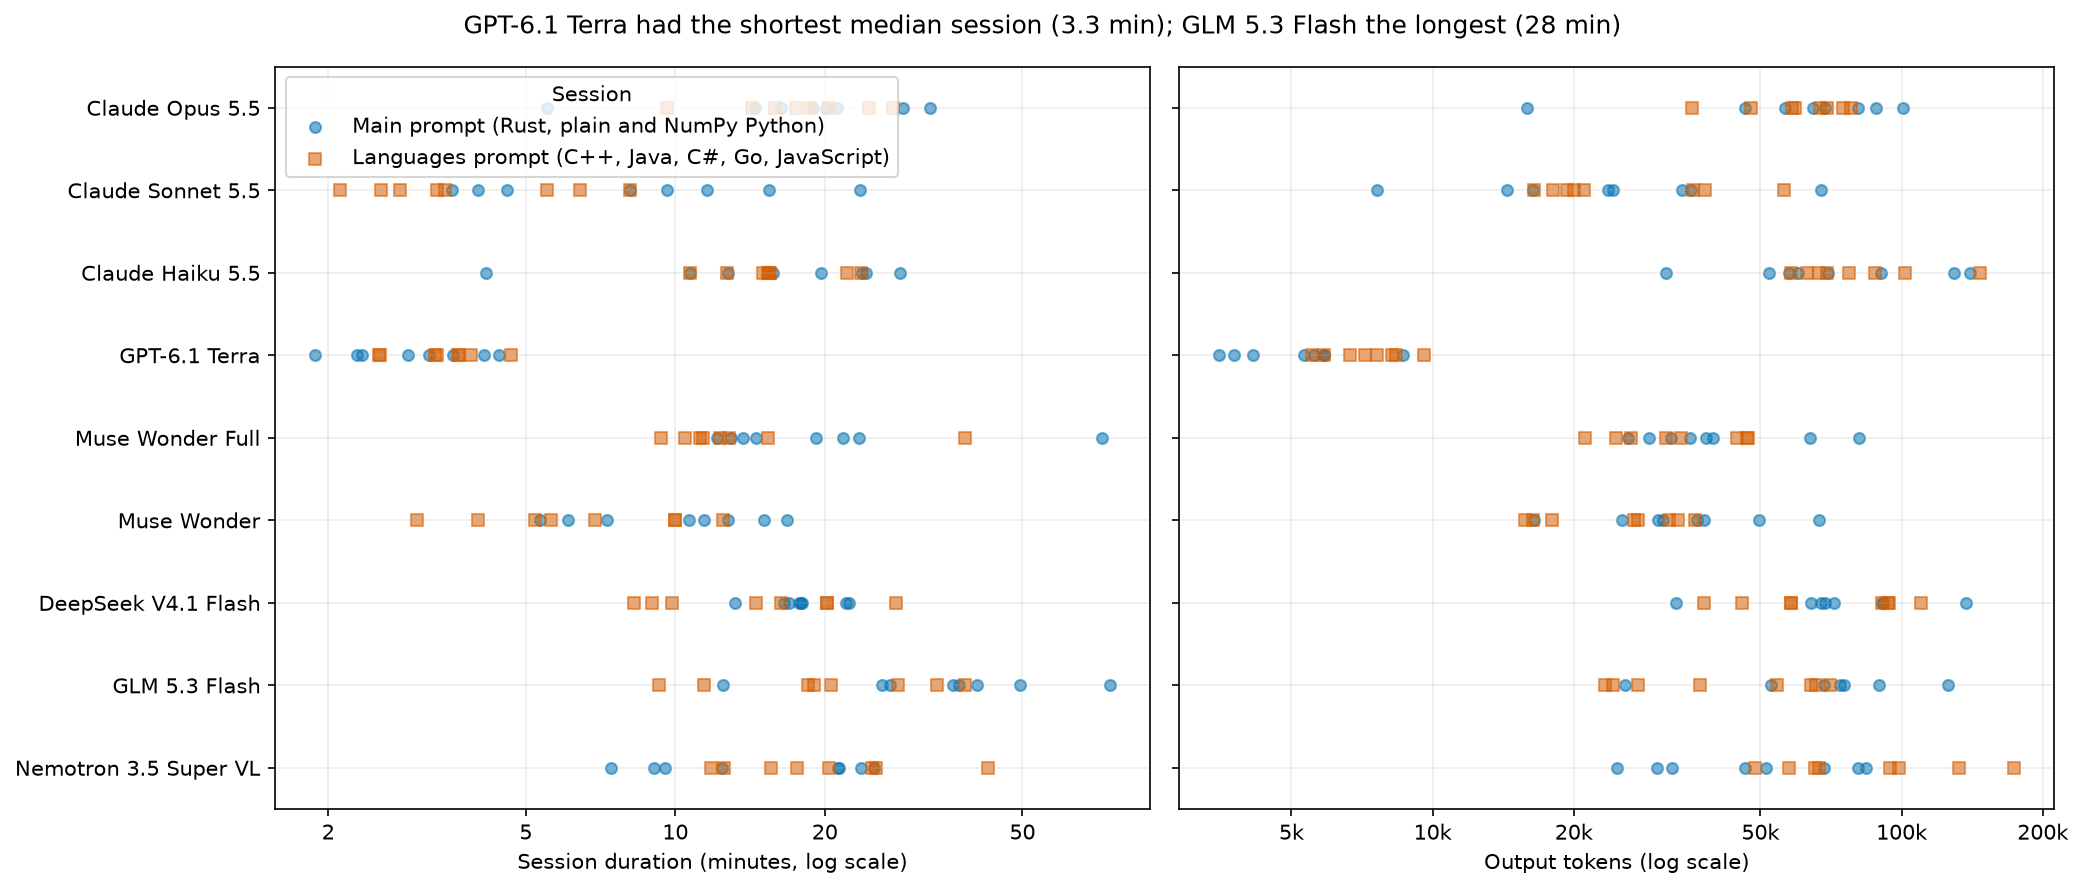

In [6]:
# Compute and present this analysis step for the reader.
def session_row(m):
    # Claude Code counts uncached, cache-read and cache-creation input separately; Codex and Muse report
    # total input directly.
    a = m.get("author")
    u = m.get("usage") or {}
    router = m.get("openrouter") or {}
    if a in ["terra", "sol"]:
        inp = u.get("input_tokens")
        cached = u.get("cached_input_tokens")
        reasoning = u.get("reasoning_output_tokens")
        basis = "Codex subscription (tokens only)"
        cost = np.nan
    elif a in ["wonder", "wonder-full"]:
        inp = u.get("input_tokens")
        cached = u.get("cached_tokens")
        reasoning = u.get("reasoning_tokens")
        basis = "Muse subscription (tokens only)"
        cost = np.nan
    else:
        inp = sum(u.get(k, 0) or 0 for k in ["input_tokens", "cache_read_input_tokens", "cache_creation_input_tokens"])
        cached = u.get("cache_read_input_tokens")
        reasoning = (u.get("output_tokens_details") or {}).get("thinking_tokens")
        reasoning = reasoning if reasoning is not None else (router.get("usage") or {}).get("thinking_tokens")
        basis = "OpenRouter charge" if a in OPEN_WEIGHT else "Claude Code list-price estimate"
        cost = router.get("cost_usd") if a in OPEN_WEIGHT else m.get("cost_usd")
    return dict(
        author=a,
        model=MODEL_LABELS.get(a, a),
        task=m.get("task"),
        kind=m.get("kind", "failed"),
        minutes=(m.get("wall_seconds") or 0) / 60,
        turns=m.get("turns"),
        tool_calls=m.get("tool_calls"),
        all_input_tokens=inp,
        cached_input_tokens=cached,
        output_tokens=u.get("output_tokens"),
        reasoning_tokens=reasoning,
        cost_usd=cost,
        cost_basis=basis,
        exit_code=m.get("exit_code"),
        timed_out=m.get("timed_out", False),
        missing=len(m.get("missing") or []),
    )


cols = [
    "author",
    "model",
    "task",
    "kind",
    "minutes",
    "turns",
    "tool_calls",
    "all_input_tokens",
    "cached_input_tokens",
    "output_tokens",
    "reasoning_tokens",
    "cost_usd",
    "cost_basis",
    "exit_code",
    "timed_out",
    "missing",
]
sessions = pd.DataFrame([session_row(m) for m in metas], columns=cols)
failed_meta = []
for a in AUTHORS + ["opus", "sol"]:
    for p in (DATA / "failed_sessions" / a).glob("*.meta.json"):
        m = json.loads(p.read_text(encoding="utf-8"))
        m.setdefault("author", a)
        m["kind"] = "failed"
        failed_meta.append(m)
failed_sessions = pd.DataFrame([session_row(m) for m in failed_meta], columns=cols)
sessions.to_csv(DERIVED / "sessions.csv", index=False)
summary = sessions.groupby("author").agg(
    sessions=("task", "size"),
    total_minutes=("minutes", "sum"),
    median_minutes=("minutes", "median"),
    median_tool_calls=("tool_calls", "median"),
    total_output_tokens=("output_tokens", lambda x: x.sum(min_count=1)),
    total_cost=("cost_usd", lambda x: x.sum(min_count=1)),
    cost_basis=("cost_basis", "first"),
    timed_out=("timed_out", "sum"),
)
summary["harness_failures"] = failed_sessions.groupby("author").size()
summary["harness_failures"] = summary.harness_failures.fillna(0).astype(int)
display(summary.reindex(AUTHORS + ["opus", "sol"]))
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for i, a in enumerate(AUTHORS):
    for kind, marker in [("main", "o"), ("langs", "s")]:
        d = sessions[(sessions.author == a) & (sessions.kind == kind)]
        for ax, col in zip(axes, ["minutes", "output_tokens"]):
            x = pd.to_numeric(d[col], errors="coerce")
            x = x[x > 0]
            ax.scatter(
                x,
                [i] * len(x),
                marker=marker,
                color={"main": "#0072B2", "langs": "#D55E00"}[kind],
                alpha=0.55,
                s=28,
                label={"main": "Main prompt (Rust, plain and NumPy Python)", "langs": "Languages prompt (C++, Java, C#, Go, JavaScript)"}[kind] if i == 0 else None,
            )
for ax, label in zip(axes, ["Session duration (minutes, log scale)", "Output tokens (log scale)"]):
    ax.set(
        xscale="log",
        xlabel=label,
        yticks=range(len(AUTHORS)),
        yticklabels=[MODEL_LABELS[a] for a in AUTHORS],
        ylim=(len(AUTHORS) - 0.5, -0.5),
    )
    plain_log_axis(ax)
from matplotlib.ticker import FuncFormatter
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x/1000:g}k" if x >= 1000 else format_number(x)))
meds = summary.reindex(AUTHORS).median_minutes.dropna()
fig.suptitle(
    f"{MODEL_LABELS[meds.idxmin()]} had the shortest median session ({format_number(meds.min())} "
    f"min); {MODEL_LABELS[meds.idxmax()]} the longest ({format_number(meds.max())} min)"
    if len(meds)
    else "Session effort: no sessions available"
)
axes[0].legend(title="Session")
fig.tight_layout()
savefig("session_effort.png")


The models worked very differently. GPT-6.1 Terra's sessions were the shortest (median 3.3 minutes, 11 tool calls,
0.10 million output tokens over 16 sessions) and Claude Sonnet 5.5's next (5.1 minutes, 19 calls). GLM 5.3 Flash's
were the longest (median 28 minutes), and Nemotron made the most tool calls (median 101). Claude Code's list-price
estimates put the 16 sessions at USD 40 for Opus, 7.9 for Sonnet and 2.7 for Haiku; OpenRouter charged USD 8.0 for
DeepSeek and 2.2 for GLM; Nemotron ran on a free tier; Terra and the Muse models ran on subscriptions that report
tokens only. One GLM session reached the 75-minute limit with all its files written and was measured as written.

The harness-failure column counts sessions that ended for reasons outside the model and were run again from scratch,
55 in all: C++ builds broken by an overlong PATH after the desktop app restarted, Nemotron's free tier running out of
daily requests, OpenRouter credits running out, the laptop going to sleep, and two crashes of the agent programs.
The failed runs are kept in `data/failed_sessions/`; `data/PROTOCOL.md` lists each. Section 13 asks whether longer
sessions bought faster code.

## 6. How the programs were checked and timed

For each task a straightforward reference solution produced the expected output for every input, and a second
solution written a different way had to agree before the input was used; all 55 inputs agreed. A program's output is
compared field by field with the expected output. A failure would be sorted into one of several kinds: the program
did not build, crashed, ran out of time, wrote output that cannot be read in the required format, or wrote readable
output with a wrong value. Only the last kind is a wrong answer. For the spring simulation, which uses floating-point
numbers, values within one part in a billion count as equal.

Every correct program ran once to warm up the disk cache and then five more times on the benchmark input, taking
turns in a shuffled order with all the other programs for the same task (73, or 79 for heat). The score is the
median of the five wall-clock times, from starting the program to its exit, as a user would wait for it, including
starting the runtime, reading the input and printing the answer. Single-threaded programs were held to the six
performance cores; their garbage collectors and just-in-time compilers could still use helper threads there. The
timing ran in one sitting on mains power, with a guard that waits for mains power and discards any run during
which the computer slept or was suspended; none was discarded. Peak memory is the largest amount of physical memory
the program held at once (Windows calls it the peak working set), in megabytes of a million bytes.

Three ratios summarise the times. Relative time compares the versions one model wrote for one task: with a fastest
version at 0.46 s, a version taking 0.92 s has relative time 2.0. A speed-up compares two versions directly: a
Python time of 3.1 s and a Rust time of 0.46 s give 3.1 / 0.46 = 6.8x. The model speed index compares the nine
models' programs for one task in one language: each program's time is divided by the geometric mean of the nine
models' times, so 0.5 means twice as fast as a typical model's program and 2.0 twice as slow.

Averages over tasks use the geometric mean (multiply the ratios and take the root), because an ordinary average lets
one large ratio dominate: for ratios of 2 and 50, the ordinary average is 26, the geometric mean 10. The 95%
intervals come from resampling the eight tasks with replacement 10,000 times, so they show how much an average
depends on which tasks were chosen.

## 7. Worked example: the heat task in nine versions

The heat task describes a floor plan of 400 x 400 cells. Open cells start at 0, heat sources hold a fixed value, and
at each of 250 steps every open cell becomes `(4 * old + up + down + left + right) // 8`, where a neighbour that is
a wall, or lies outside the grid, contributes the cell's own old value. The answer is the sum of the open cells, the
hottest cell and a checksum, in exact integer arithmetic.

This example follows Claude Sonnet 5.5's nine versions. Sonnet spent 3.5 minutes on Rust and the Pythons and 3.4
minutes on the other five languages. In every compiled and virtual-machine language it used one plan: add a border
of walls so every cell has its neighbours at fixed distances in memory, and update the grid as one flat array with
no branches. The next cell defines two helpers (`show_code` prints numbered lines of a saved program; `show_run`
prints its correctness checks and timing summary), and the cell after it prints the C++ version's update loop:

In [7]:
SHOW_PATHS = {'rust': 'rust/src/main.rs', 'cpp': 'cpp/main.cpp', 'java': 'java/src/Main.java', 'csharp': 'csharp/Program.cs',
              'go': 'go/main.go', 'js': 'js/main.js', 'plain': 'plain.py', 'fast': 'fast.py', 'simple': 'plain.py'}
def show_code(author, task, variant, start, end):
    author = 'reference' if variant == 'simple' else author
    path = DATA / 'programs' / author / task / SHOW_PATHS[variant]
    for i, line in enumerate(path.read_text(encoding='utf-8').splitlines(), 1):
        if start <= i <= end: print(f'{i:4}  {line}')
def show_run(author, task, variant, input):
    c = correctness[(correctness.author==author)&(correctness.task==task)&(correctness.variant==variant)&(correctness.input==input)]
    c = c[['workers','status','detail','stdout']].copy(); c['stdout'] = c.stdout.fillna('').astype(str).str[:200]; display(c)
    t = pd.concat([runs,sweep,scaling],ignore_index=True)
    t = t[(t.author==author)&(t.task==task)&(t.variant==variant)&(t.input==input)]
    display(t.groupby('workers').wall_seconds.agg(['count','median','min','max']))

In [8]:
show_code('sonnet', 'heat', 'cpp', 9, 14)

   9  static void step(const int* __restrict a, int* __restrict b, const int* __restrict c, const int* __restrict m,
  10                   long long lo, long long hi, long long w2) {
  11      for (long long i = lo; i < hi; i++) {
  12          b[i] = (c[i] * a[i] + ((a[i - 1] + a[i + 1] + a[i - w2] + a[i + w2]) & m[i])) >> 3;
  13      }
  14  }


Here `a` is the grid at the start of the step and `b` the new one, `w2` the padded row width (so `a[i - w2]` is the
cell above), `c[i]` is 4 plus the number of wall or outside neighbours (walls hold 0, so the cell's own value is
counted once for each), and `m[i]` keeps the neighbour sum for open cells and zeroes it for walls and sources.
Because the loop reads memory in order with fixed offsets, the compiler can process several cells per instruction.

The NumPy version does the same arithmetic on whole shifted copies of the grid, one array operation per term:

In [9]:
show_code('sonnet', 'heat', 'fast', 30, 39)

  30      for _ in range(steps):
  31          mul(cur[1:-1, 1:-1], coef, out=tmp)
  32          add(tmp, cur[:-2, 1:-1], out=tmp)
  33          add(tmp, cur[2:, 1:-1], out=tmp)
  34          add(tmp, cur[1:-1, :-2], out=tmp)
  35          add(tmp, cur[1:-1, 2:], out=tmp)
  36          rsh(tmp, 3, out=tmp)
  37          band(tmp, mask, out=tmp)
  38          bor(tmp, fixed, out=nxt[1:-1, 1:-1])
  39          cur, nxt = nxt, cur


The plain-Python version could not use NumPy, and a loop over 160,000 cells for 250 steps takes many seconds (the
simple reference loop takes 16 s). Instead it packs the whole grid into one Python integer, 24 bits per cell, and
moves every cell's neighbours into place with shifts of that one huge number. Python's integers can be any size,
and the interpreter does arithmetic on them in compiled code, so each step is a handful of operations on a number
with about 3.8 million bits:

In [10]:
show_code('sonnet', 'heat', 'plain', 55, 67)

  55  
  56      X = pack(vals)
  57      # keep result: divide by 8 leaves 3 stray bits in the top of each lane
  58      keep = pack(openm) & int.from_bytes(bytes((255, 255, 31)) * n, "little")
  59      F = pack(fixed)
  60      W0, W1, W2, W3 = (pack(a) for a in wall)
  61      # a source cell contributes its own value to wall-adjacent neighbours too,
  62      # which the wall masks handle because X holds the source value.
  63      up_sh = wp * L
  64      for _ in range(steps):
  65          s = (X << 2) + (X << up_sh) + (X >> up_sh) + (X << L) + (X >> L)
  66          s += (X & W0) + (X & W1) + (X & W2) + (X & W3)
  67          X = ((s >> 3) & keep) | F


The next cell shows, for the simple reference and all eight of Sonnet's versions, the correctness check on the
benchmark grid (status and the start of the output) and the five timed runs (count, median, fastest and slowest).

In [11]:
for author, variant in [('reference', 'simple')] + [('sonnet', v) for v in ['cpp', 'rust', 'csharp', 'go', 'java', 'js', 'fast', 'plain']]:
    print(author, variant)
    show_run(author, 'heat', variant, 'full')

reference simple


,workers,status,detail,stdout
1476,1,correct,NaN,sum 272113217\nmax 8748 240 346\nchecksum 2148...


,count,median,min,max
workers,,,,
1,5,16,14,17


sonnet cpp


,workers,status,detail,stdout
4673,1,correct,NaN,sum 272113217\nmax 8748 240 346\nchecksum 2148...


,count,median,min,max
workers,,,,
1,5,0.051,0.048,0.061


... (17 outputs left out)

,count,median,min,max
workers,,,,
1,5,0.39,0.35,0.54


sonnet plain


,workers,status,detail,stdout
1453,1,correct,NaN,sum 272113217\nmax 8748 240 346\nchecksum 2148...


,count,median,min,max
workers,,,,
1,5,0.87,0.85,1.2


All nine printed the same `sum`, `max` and `checksum` lines. The medians are 0.051 s for C++, 0.054 s for Rust,
0.104 s for C#, 0.109 s for Go, 0.207 s for Java, 0.221 s for JavaScript, 0.392 s for NumPy, 0.867 s for the
packed-integer plain Python and 15.8 s for the simple loop. Relative to C++, the fastest, that is 1.1 for Rust, 2.0
for C#, 2.1 for Go, 4.1 for Java, 4.3 for JavaScript, 7.7 for NumPy, 17 for plain Python and 310 for simple Python.
On this short task much of each time is start-up: an empty C++ program takes 0.03 s to start and exit on this
machine, an empty Java program 0.11 s (section 14). The packing trick made the standard-library Python 18 times
faster than the simple loop, which shows how far Python written for speed can be from Python written in a hurry.

The other eight models wrote the same task with other plans. Their C++ took from 0.038 s (Opus) to 0.184 s
(Nemotron), and their plain Python from 0.47 s (Opus, also packed) to 9.8 s (GLM, a loop over cells). Section 19
shows the GLM loop next to the packed versions.

## 8. Correctness

The first table shows, for each model and version, how many of the eight tasks the program passed: `8/8` means it
printed the expected output on the hidden small input and on the benchmark input for every task (for walkers, also
with every worker count tested), and a letter would mark a failure kind. The next tables list every failed run (none)
and count statuses per model, with readable failures and unreadable or format failures apart. The figure draws the
same grid.

variant,Rust,C++,Go,C#,Java,JavaScript,NumPy Python,Plain Python,Total
author,,,,,,,,,
Claude Opus 5.5,8/8,8/8,8/8,8/8,8/8,8/8,8/8,8/8,64/64
Claude Sonnet 5.5,8/8,8/8,8/8,8/8,8/8,8/8,8/8,8/8,64/64
Claude Haiku 5.5,8/8,8/8,8/8,8/8,8/8,8/8,8/8,8/8,64/64
GPT-6.1 Terra,8/8,8/8,8/8,8/8,8/8,8/8,8/8,8/8,64/64
Muse Wonder Full,8/8,8/8,8/8,8/8,8/8,8/8,8/8,8/8,64/64
Muse Wonder,8/8,8/8,8/8,8/8,8/8,8/8,8/8,8/8,64/64
DeepSeek V4.1 Flash,8/8,8/8,8/8,8/8,8/8,8/8,8/8,8/8,64/64
GLM 5.3 Flash,8/8,8/8,8/8,8/8,8/8,8/8,8/8,8/8,64/64
Nemotron 3.5 Super VL,8/8,8/8,8/8,8/8,8/8,8/8,8/8,8/8,64/64


,author,task,variant,input,workers,status,detail,stderr


status,correct,wrong,unreadable,crashed,timeout,build_failed,disallowed_dependency,missing,out_of,readable_accuracy,unreadable_type_failures
author,,,,,,,,,,,
opus55,64,0,0,0,0,0,0,0,64,1,0
sonnet,64,0,0,0,0,0,0,0,64,1,0
haiku,64,0,0,0,0,0,0,0,64,1,0
terra,64,0,0,0,0,0,0,0,64,1,0
wonder-full,64,0,0,0,0,0,0,0,64,1,0
wonder,64,0,0,0,0,0,0,0,64,1,0
deepseek,64,0,0,0,0,0,0,0,64,1,0
glm,64,0,0,0,0,0,0,0,64,1,0
nemotron,64,0,0,0,0,0,0,0,64,1,0


model programs: 576 of 576 correct
references: 8 of 8 correct
heat-pilot programs: 6 of 6 correct


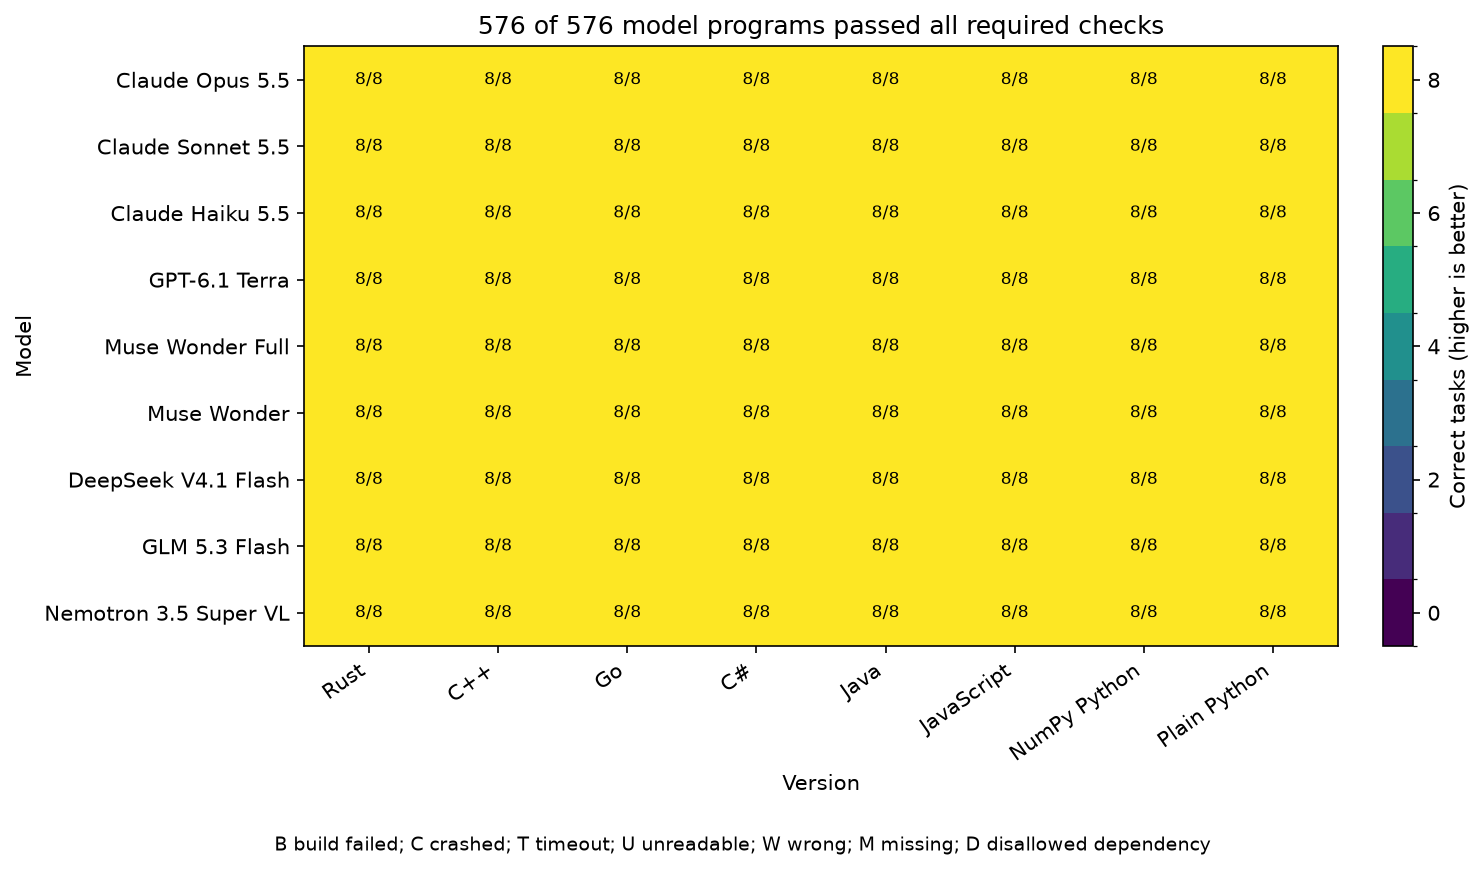

In [12]:
# Compute and present this analysis step for the reader.
required = correctness[correctness.input.isin(["t1", "full"])].copy()


def program_status(group):
    if set(group.input) != {"t1", "full"}:
        return "missing"
    failed = group[group.status != "correct"]
    if not failed.empty:
        return failed.status.iloc[0]
    if group.task.iloc[0] == "walkers":
        if not {1, 4, 16}.issubset(set(group.loc[group.input.eq("t1"), "workers"])):
            return "missing"
        extra = scaling[(scaling.author == group.author.iloc[0]) & (scaling.variant == group.variant.iloc[0])]
        if not {1, 2, 4, 8, 16}.issubset(set(extra.workers)):
            return "missing"
        if (extra.status != "correct").any():
            return extra.loc[extra.status != "correct", "status"].iloc[0]
    return "correct"


status = pd.DataFrame(
    [
        dict(author=a, task=t, variant=v, status=program_status(g))
        for (a, t, v), g in required.groupby(["author", "task", "variant"])
    ]
)
expected = pd.DataFrame(
    [(a, t, v) for a in AUTHORS for t in TASKS for v in MODEL_VERSIONS]
    + [("reference", t, "simple") for t in TASKS]
    + [(a, "heat", v) for a in ["opus", "sol"] for v in ["plain", "fast", "rust"]],
    columns=["author", "task", "variant"],
)
status = expected.merge(status, how="left", on=["author", "task", "variant"]).fillna({"status": "missing"})
codes = {"build_failed": "B", "crashed": "C", "timeout": "T", "unreadable": "U", "wrong": "W", "missing": "M", "disallowed_dependency": "D"}
def compact_status(g):
    count = int(g.status.eq("correct").sum())
    suffix = "".join(sorted({codes.get(x, "?") for x in g.status if x != "correct"}))
    return f"{count}/{len(g)}" + (f" {suffix}" if suffix else "")
compact = status[status.author.isin(AUTHORS)].groupby(["author", "variant"]).apply(compact_status, include_groups=False).unstack().reindex(index=AUTHORS, columns=MODEL_VERSIONS)
compact["Total"] = status[status.author.isin(AUTHORS)].groupby("author").apply(compact_status, include_groups=False).reindex(AUTHORS)
display(compact.rename(index=MODEL_LABELS, columns=LABELS))
failures = required[required.status.ne("correct")][
    ["author", "task", "variant", "input", "workers", "status", "detail", "stderr"]
].copy()
failures["stderr"] = failures.stderr.fillna("").astype(str).str[:200]
display(failures)
all_types = [
    "correct",
    "wrong",
    "unreadable",
    "crashed",
    "timeout",
    "build_failed",
    "disallowed_dependency",
    "missing",
]
counts_author = (
    status[status.author.isin(AUTHORS)]
    .groupby(["author", "status"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=AUTHORS, columns=all_types, fill_value=0)
)
counts_author["out_of"] = 64
denom = counts_author.correct + counts_author.wrong
counts_author["readable_accuracy"] = counts_author.correct / denom.replace(0, np.nan)
counts_author["unreadable_type_failures"] = counts_author[
    ["unreadable", "crashed", "timeout", "build_failed", "disallowed_dependency", "missing"]
].sum(axis=1)
display(counts_author)
for group, subset in [("model programs", status[status.author.isin(AUTHORS)]), ("references", status[status.author.eq("reference")]), ("heat-pilot programs", status[status.author.isin(["opus", "sol"])])]:
    print(f"{group}: {subset.status.eq('correct').sum()} of {len(subset)} correct")
grid = (
    status[status.author.isin(AUTHORS)]
    .assign(correct=lambda d: d.status.eq("correct"))
    .pivot_table(index="author", columns="variant", values="correct", aggfunc="sum")
    .reindex(index=AUTHORS, columns=MODEL_VERSIONS)
)
fig, ax = plt.subplots(figsize=(10, 5.5))
heatmap(ax, grid, fmt=".0f", cmap="viridis", label="Correct tasks (higher is better)", discrete=True)
codes = {
    "build_failed": "B",
    "crashed": "C",
    "timeout": "T",
    "unreadable": "U",
    "wrong": "W",
    "missing": "M",
    "disallowed_dependency": "D",
}
for i, a in enumerate(AUTHORS):
    for j, v in enumerate(MODEL_VERSIONS):
        subset = status[(status.author == a) & (status.variant == v)]
        n = int(subset.status.eq("correct").sum())
        types = "".join(sorted({codes.get(x, "?") for x in subset.status if x != "correct"}))
        ax.texts[i * len(MODEL_VERSIONS) + j].set_text(f"{n}/8" + (" " + types if types else ""))
ax.set_title(
    f"{int(grid.sum().sum())} of {len(AUTHORS) * len(TASKS) * len(MODEL_VERSIONS)} "
    f"model programs passed all required checks"
)
ax.set_xlabel("Version")
ax.set_ylabel("Model")
fig.text(
    0.5,
    -0.04,
    "B build failed; C crashed; T timeout; U unreadable; W wrong; M missing; D disallowed dependency",
    ha="center",
    fontsize=9,
)
fig.tight_layout()
savefig("correctness_grid.png")


Every program is correct and the failure list is empty: 576 model-written programs, 8 simple-Python references and
6 heat programs from the pilot. No program failed to build, crashed, timed out, printed unreadable output or gave a
wrong value, so there are no format failures to separate from wrong answers.

This is a ceiling. With every program correct, the test cannot rank the models or the languages on correctness, and
576 correct out of 576 still allows a true failure rate of up to about 0.5% for programs like these (95% upper
bound). The specs were exact, every model had samples with expected outputs to test against and a shell to run
them in. The rest of the comparison is about speed, memory, code size and build time.

## 9. Run time on the full inputs

The first table gives, for each task and version, the geometric mean over the nine models of their median times on
the benchmark input (the full table per model is saved as `data/results/derived/median_full.csv`). In the figure each
row is a task and each marker one version, placed at that geometric mean, with a thin line from the fastest model's
program to the slowest's, so a long line marks a version where the models disagreed. Marker shapes and colours
follow the legend. The x-axis is logarithmic: one grid step is a factor of ten.

In [13]:
ok = status[status.status.eq('correct')][['author', 'task', 'variant']]
full = runs[(runs.input == 'full') & runs.status.eq('correct')].merge(ok, on=['author', 'task', 'variant'])
median = full.groupby(['task', 'author', 'variant']).wall_seconds.agg(['median', 'min', 'max', 'count']).reset_index()
median.to_csv(DERIVED / 'median_times.csv', index=False)
shown = median[median.author.isin(AUTHORS + ['reference'])]
full_table = shown.pivot_table(index=['task', 'author'], columns='variant', values='median').reindex(columns=VERSIONS).reindex(TASKS, level='task')
full_table.to_csv(DERIVED / 'median_full.csv')
summary_times = shown.groupby(['task', 'variant'])['median'].agg(geom).unstack().reindex(index=TASKS, columns=VERSIONS)
display(summary_times.rename(columns=LABELS).round(4))


variant,Rust,C++,Go,C#,Java,JavaScript,NumPy Python,Plain Python,Simple Python
task,,,,,,,,,
springs,0.11,0.11,0.14,0.21,0.3,0.32,0.49,13,16
wordpairs,1.0,1.1,1.2,1.3,1.5,1.9,4.6,12,45
ledger,1.2,1.2,1.4,1.5,1.6,2.6,9.6,8.2,10
logscan,0.66,0.58,0.6,0.8,1.1,1.3,4.8,4.3,6.7
routes,0.24,0.26,0.32,0.42,0.51,0.55,2.6,6.1,11
align,0.1,0.11,0.12,0.25,0.34,0.36,0.93,9.4,13
heat,0.069,0.069,0.089,0.13,0.22,0.22,0.47,1.7,16
walkers,0.19,0.12,0.14,0.22,0.29,0.79,1.9,11,23


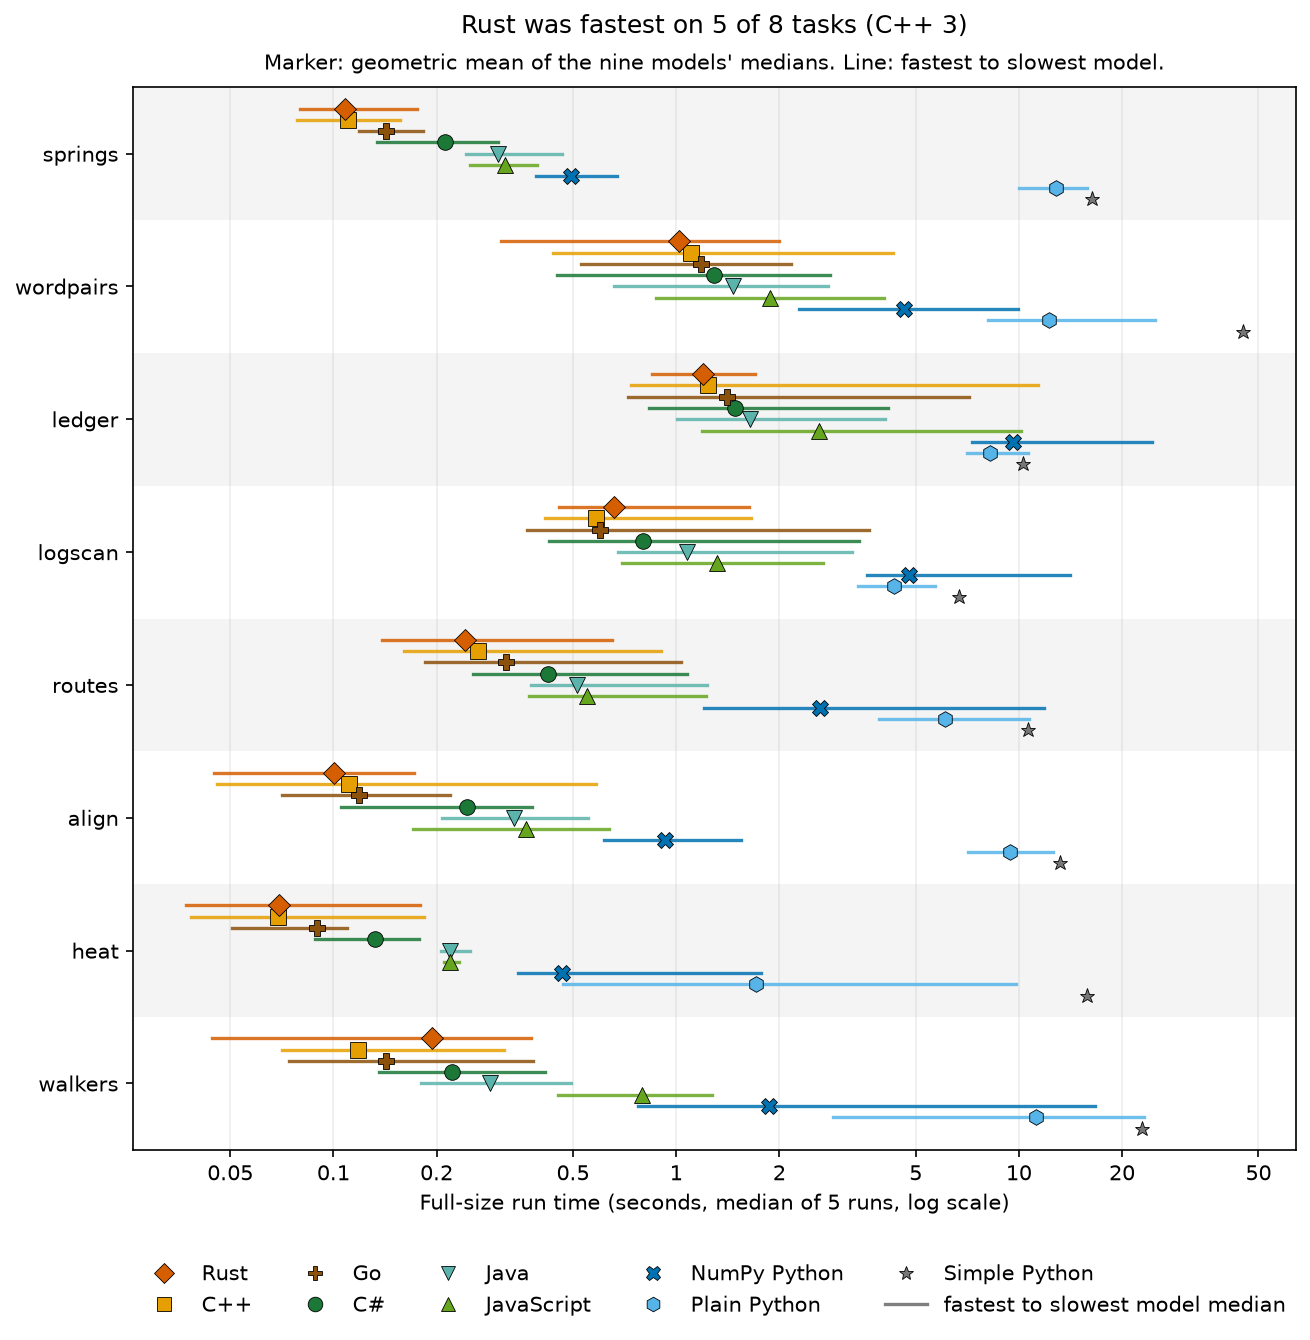

Rust was fastest on 5 of 8 tasks (C++ 3)


In [14]:
# Compute and present this analysis step for the reader.
OFFS = {v: (i - (len(VERSIONS) - 1) / 2) * 0.085 for i, v in enumerate(VERSIONS)}


def combine_authors(df, col):
    """Summarize each task and version across model authors and the reference."""
    rows = []
    for (t, v), g in df.groupby(["task", "variant"]):
        vals = g[col].to_numpy(dtype=float)
        rows.append(dict(task=t, variant=v, gm=geom(vals), lo=vals.min(), hi=vals.max(), n=len(vals)))
    return pd.DataFrame(rows, columns=["task", "variant", "gm", "lo", "hi", "n"])


def strip_by_task(ax, comb, xlabel):
    for ti in range(0, len(TASKS), 2):
        ax.axhspan(ti - 0.5, ti + 0.5, color="black", alpha=0.045, lw=0)
    for r in comb.itertuples():
        y = TASKS.index(r.task) + OFFS[r.variant]
        if r.hi > r.lo:
            ax.plot([r.lo, r.hi], [y, y], color=COLORS[r.variant], lw=1.6, alpha=0.85)
        ax.plot(
            r.gm,
            y,
            marker=MARKERS[r.variant],
            ms=7.5,
            color=COLORS[r.variant],
            markeredgecolor="black",
            markeredgewidth=0.4,
            ls="none",
        )
    ax.set(xscale="log", yticks=range(len(TASKS)), yticklabels=TASKS, xlabel=xlabel, ylim=(len(TASKS) - 0.5, -0.5))
    ax.grid(axis="y", visible=False)
    plain_log_axis(ax)


def winners_title(comb, verb):
    best = comb.loc[comb.groupby("task").gm.idxmin()].variant.value_counts()
    if best.empty:
        return "No measured programs", best
    top = best.index[0]
    rest = ", ".join(f"{LABELS[v]} {n}" for v, n in best.iloc[1:].items())
    return f"{LABELS[top]} {verb} on {best.iloc[0]} of {len(TASKS)} tasks" + (f" ({rest})" if rest else ""), best


time_comb = combine_authors(median[median.author.isin(AUTHORS + ["reference"])], "median")
title, best_counts = winners_title(time_comb, "was fastest")
fig, ax = plt.subplots(figsize=(10, 9.2))
strip_by_task(ax, time_comb, "Full-size run time (seconds, median of 5 runs, log scale)")
ax.set_title(title, fontsize=12, pad=26)
ax.text(
    0.5,
    1.012,
    "Marker: geometric mean of the nine models' medians. Line: fastest to slowest model.",
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=10,
)
ax.legend(
    handles=version_handles(ls="none")
    + [Line2D([0], [0], color="gray", lw=1.6, label="fastest to slowest model median")],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.09),
    ncol=5,
    frameon=False,
)
savefig("runtime_by_task.png")
print(title)


The rows show three groups. Rust, C++ and Go sit at the left, between 0.07 and 1.4 s. C#, Java and JavaScript sit
just to their right, typically 1.5 to 3 times slower. The Python versions sit far to the right: NumPy at 0.5 to 10
s, plain Python at 1.7 to 13 s and simple Python at 6.7 to 45 s.

The lines are long. On wordpairs the nine models' C++ ranged from 0.44 to 4.3 s and on ledger from 0.74 to 11.4 s,
so the slowest model's C++ could be slower than the fastest model's JavaScript. On heat the plain-Python line runs
from 0.47 s (packed integers) to 9.8 s (a loop over cells). Sections 12 and 19 explain these gaps.

## 10. Which language was fastest

For each task and model, a version's relative time is its median divided by the fastest median among that model's
versions on the task. The first table gives the geometric mean over the eight tasks per model and version. The first
figure draws these means with their 95% bootstrap intervals, the heatmap shows the same numbers as a grid (darker is
slower, log colour scale). The count after them is how often each version was a model's fastest on a task, and the
last table gives the speed-up of each compiled or virtual-machine language over the faster of the same model's two
Python versions.

author,opus55,sonnet,haiku,terra,wonder-full,wonder,deepseek,glm,nemotron
version,,,,,,,,,
rust,1.2,1.1,1.1,1.1,1.3,1.3,1.2,1.3,1.5
cpp,1.1,1.1,1.2,2.0,1.1,1.2,1.1,1.1,1.1
go,1.4,1.5,1.4,1.7,1.3,1.2,1.3,1.5,1.4
csharp,1.7,2.1,2.0,2.3,1.8,1.8,1.8,2.1,1.9
java,2.9,2.7,2.6,2.3,2.7,2.4,2.4,2.4,2.6
js,3.7,3.3,3.5,3.2,3.1,3.0,3.1,3.1,3.9
fast,10.0,8.2,13,6.8,8.9,7.4,8.5,7.6,13
plain,33,38,39,27,29,27,29,35,40
simple,111,84,78,39,80,62,75,65,52


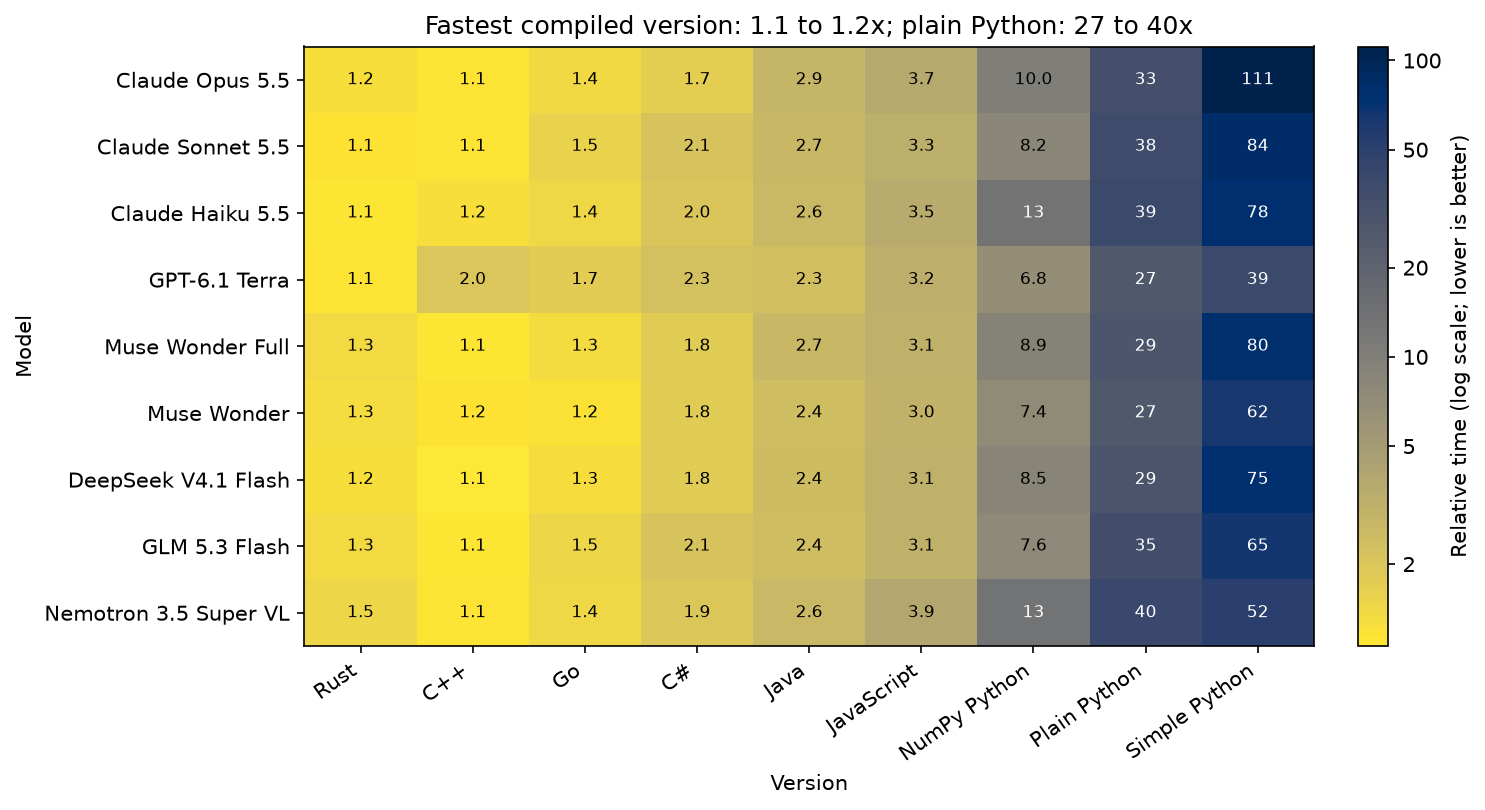

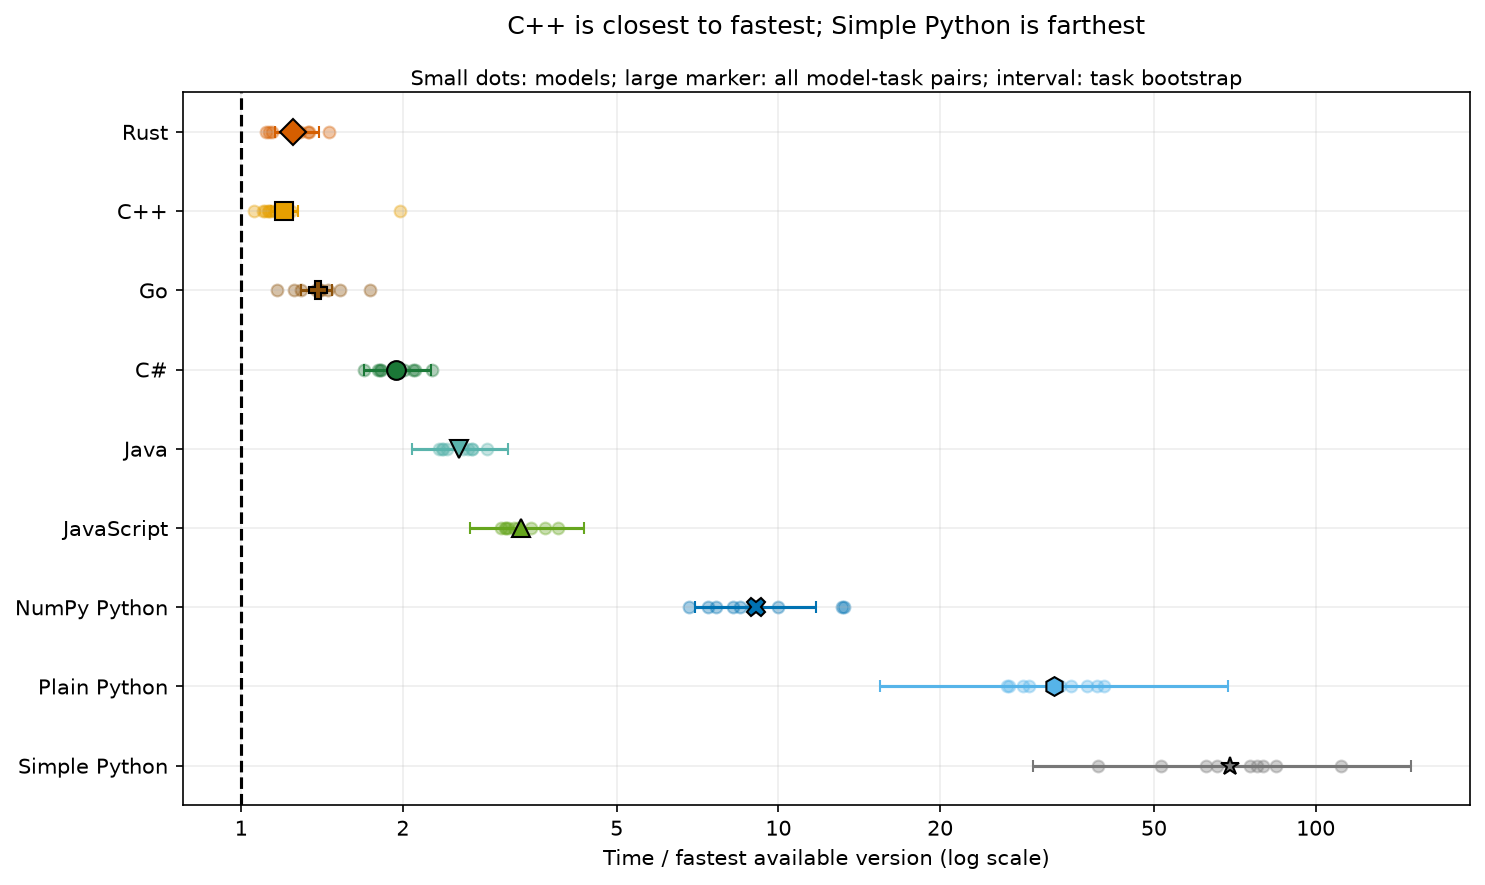

version
rust      29
cpp       30
go        13
csharp     0
java       0
js         0
fast       0
plain      0
simple     0
Name: fastest task-model pairs, dtype: int64

author,opus55,sonnet,haiku,terra,wonder-full,wonder,deepseek,glm,nemotron
language,,,,,,,,,
rust,7.7,6.9,8.9,5.9,6.6,5.7,6.8,5.6,9.1
cpp,8.5,6.9,8.0,3.4,8.0,6.3,8.0,6.8,12
go,6.9,5.2,7.1,3.8,6.8,6.3,6.7,5.1,9.4
csharp,5.6,3.8,4.9,2.9,4.9,4.0,4.7,3.5,6.8
java,3.3,2.9,3.8,2.9,3.3,3.1,3.5,3.1,5.0
js,2.6,2.4,2.9,2.1,2.9,2.4,2.7,2.4,3.4


In [15]:
# Compute and present this analysis step for the reader.
mt = median.set_index(["task", "author", "variant"])["median"]


def med(task, author, version):
    x = mt.get((task, "reference" if version == "simple" else author, version), np.nan)
    return float(x) if pd.notna(x) and x > 0 else np.nan


rng = np.random.default_rng(39)


def bootstrap_geom(x, n=10000):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x) & (x > 0)]
    if not len(x):
        return (np.nan,) * 3
    b = np.exp(np.log(rng.choice(x, size=(n, len(x)))).mean(axis=1))
    return geom(x), *np.quantile(b, [0.025, 0.975])


def task_bootstrap(d, value):
    ts = d.task.unique()
    if not len(ts):
        return (np.nan,) * 3
    logs = {t: np.log(d.loc[d.task.eq(t), value].to_numpy(dtype=float)) for t in ts}
    bs = []
    for sample in rng.choice(ts, size=(10000, len(ts))):
        bs.append(np.exp(np.concatenate([logs[t] for t in sample]).mean()))
    return geom(d[value]), *np.quantile(bs, [0.025, 0.975])


rr = []
for a in AUTHORS:
    for t in TASKS:
        vals = {v: med(t, a, v) for v in VERSIONS}
        vals = {v: x for v, x in vals.items() if np.isfinite(x)}
        if vals:
            best = min(vals.values())
            rr.extend(dict(task=t, author=a, version=v, ratio=x / best) for v, x in vals.items())
rel_pairs = pd.DataFrame(rr, columns=["task", "author", "version", "ratio"])
rel_pairs.to_csv(DERIVED / "relative_speed_pairs.csv", index=False)
rows = []
for (a, v), d in rel_pairs.groupby(["author", "version"]):
    g, lo, hi = bootstrap_geom(d.ratio)
    rows.append(dict(author=a, version=v, geometric_mean=g, ci_low=lo, ci_high=hi, tasks=len(d)))
rel = pd.DataFrame(rows, columns=["author", "version", "geometric_mean", "ci_low", "ci_high", "tasks"])
rel.to_csv(DERIVED / "relative_speed.csv", index=False)
display(rel.pivot(index="version", columns="author", values="geometric_mean").reindex(index=VERSIONS, columns=AUTHORS))
grid = rel.pivot(index="author", columns="version", values="geometric_mean").reindex(index=AUTHORS, columns=VERSIONS)
compiled_best = grid[["rust", "cpp", "go"]].min(axis=1).dropna()
plain_values = grid["plain"].dropna()
relative_title = (
    f"Fastest compiled version: {format_number(compiled_best.min())} to {format_number(compiled_best.max())}x; "
    f"plain Python: {format_number(plain_values.min())} to {format_number(plain_values.max())}x"
    if len(compiled_best) and len(plain_values)
    else "Relative time compared with the fastest available version"
)
fig, ax = plt.subplots(figsize=(10, 5.5))
heatmap(ax, grid, log=True, label="Relative time (log scale; lower is better)")
ax.set(title=relative_title, xlabel="Version", ylabel="Model")
fig.tight_layout()
savefig("relative_speed_heatmap.png")
overall = {v: task_bootstrap(rel_pairs[rel_pairs.version.eq(v)], "ratio") for v in VERSIONS}
fig, ax = plt.subplots(figsize=(10, 6))
for i, v in enumerate(VERSIONS):
    d = rel[rel.version.eq(v)]
    ax.scatter(d.geometric_mean, [i] * len(d), color=COLORS[v], alpha=0.35, s=32)
    g, lo, hi = overall[v]
    if np.isfinite(g):
        ax.errorbar(
            g,
            i,
            xerr=[[g - lo], [hi - g]],
            fmt=MARKERS[v],
            color=COLORS[v],
            markeredgecolor="black",
            markersize=9,
            capsize=3,
        )
ax.axvline(1, color="black", ls="--")
ax.set(
    xscale="log",
    yticks=range(len(VERSIONS)),
    yticklabels=[LABELS[v] for v in VERSIONS],
    ylim=(len(VERSIONS) - 0.5, -0.5),
    xlabel="Time / fastest available version (log scale)",
)
plain_log_axis(ax)
valid = {v: x[0] for v, x in overall.items() if np.isfinite(x[0])}
ax.set_title(
    f"{LABELS[min(valid, key=valid.get)]} is closest to fastest; {LABELS[max(valid, key=valid.get)]} is farthest"
    if valid
    else "No relative timings available",
    pad=28,
)
ax.text(
    0.5,
    1.01,
    "Small dots: models; large marker: all model-task pairs; interval: task bootstrap",
    transform=ax.transAxes,
    ha="center",
)
fig.tight_layout()
savefig("relative_speed.png")
display(
    rel_pairs[rel_pairs.ratio.eq(1)]
    .groupby("version")
    .size()
    .reindex(VERSIONS, fill_value=0)
    .rename("fastest task-model pairs")
)
sp = []
for a in AUTHORS:
    for t in TASKS:
        py = [med(t, a, v) for v in ["plain", "fast"]]
        py = [x for x in py if np.isfinite(x)]
        if len(py) < 2:
            continue
        for v in LANGS:
            x = med(t, a, v)
            if np.isfinite(x):
                sp.append(dict(author=a, task=t, language=v, speedup=min(py) / x))
speed = pd.DataFrame(sp, columns=["author", "task", "language", "speedup"])
rows = []
for (a, v), d in speed.groupby(["author", "language"]):
    g, lo, hi = bootstrap_geom(d.speedup)
    rows.append(dict(author=a, language=v, geometric_mean=g, ci_low=lo, ci_high=hi, tasks=len(d)))
speedups = pd.DataFrame(rows, columns=["author", "language", "geometric_mean", "ci_low", "ci_high", "tasks"])
speedups.to_csv(DERIVED / "speedups.csv", index=False)
display(
    speedups.pivot(index="language", columns="author", values="geometric_mean").reindex(index=LANGS, columns=AUTHORS)
)


| Version | Relative time, range over the nine models | Speed-up over the model's faster Python version |
|---|---|---|
| Rust | 1.11 to 1.46 | 5.6x to 9.1x |
| C++ | 1.06 to 1.98 | 3.4x to 11.8x |
| Go | 1.17 to 1.74 | 3.8x to 9.4x |
| C# | 1.69 to 2.27 | 2.9x to 6.8x |
| Java | 2.34 to 2.86 | 2.9x to 5.0x |
| JavaScript | 3.04 to 3.89 | 2.1x to 3.4x |
| NumPy Python | 6.8 to 13.3 | |
| Plain Python | 26.6 to 40.4 | |

The families separate cleanly for every model: the ahead-of-time compiled languages between 1.06 and 2.0, the
virtual-machine languages from 1.7 to 3.9, NumPy Python from 6.8 to 13 and plain Python above 26. C++ was the
fastest version in 30 of the 72 task-and-model pairs, Rust in 29 and Go in 13; no other version was ever fastest.
Inside a family the order depends on the model: C++ averaged 1.06 to 1.24 for eight models and 1.98 for Terra,
whose C++ was slow on three tasks (section 19). Among the virtual-machine languages the order was the same for all
nine models: C#, then Java, then JavaScript.

The speed-up column is the comparison a team would make when deciding whether to move a Python job: given the better
of the model's two Python versions, how much does each language add. It depends on the model's Python as well as
its faster language. Nemotron's gains were the largest (9.1x for Rust, 11.8x for C++) partly because its Python was
the slowest of the nine; Terra's were the smallest (5.9x for Rust, 3.4x for C++) because its compiled versions were
slow too.

## 11. Where NumPy helps

The table divides each model's plain-Python time by its NumPy time for every task. A value above 1 means the NumPy
version was faster than the same model's plain version; below 1 means it was slower.

In [16]:
p=median[median.author.isin(AUTHORS)].pivot(index=['task','author'],columns='variant',values='median').reindex(columns=['plain','fast'])
display((p['plain']/p['fast']).unstack('author').reindex(index=TASKS,columns=AUTHORS))


author,opus55,sonnet,haiku,terra,wonder-full,wonder,deepseek,glm,nemotron
task,,,,,,,,,
springs,27,31,33,22,28,26,22,25,22
wordpairs,3.7,6.0,1.6,1.8,2.7,3.6,3.1,1.3,2.5
ledger,0.68,0.75,0.32,1.0,1.3,0.96,1.2,0.8,1.3
logscan,0.98,0.94,0.33,0.94,0.91,1,0.92,1.3,1.3
routes,3.8,2.9,4.3,0.9,1.4,1.6,2.2,3.9,2.4
align,12,12,13,7.6,9.2,9.7,9.0,14,7.0
heat,1.4,2.2,2.9,17,2.1,2.3,2.2,22,3.5
walkers,3.7,18,7.2,13,4.5,9.1,5.9,4.8,1.4


NumPy paid off when the work is arithmetic over many numbers at once. On springs every model's NumPy version was 22
to 33 times faster than its plain one, and on align 7 to 14 times. On heat the gain depends on the plain version:
1.4 to 3.5 times against the six models' packed-integer plain Python, 17 and 22 times against Terra's and GLM's cell
loops. On walkers it ranged from 1.4 (Nemotron, whose NumPy version moved all walkers one step at a time) to 18
(Sonnet).

It did nothing for the parsing tasks. Each JSON line or log line still has to be read by Python code one item at a
time, and NumPy can only take over after that: on ledger the NumPy versions ran at 0.68 to 1.3 times the speed of
the plain ones, and Haiku's at 0.32, three times slower, because it tried to parse the JSON with whole-array
operations (section 19). Logscan was the same, 0.92 to 1.3 for eight models and 0.33 for Haiku.

## 12. Language or model: which matters more

Sections 9 and 10 showed both decisions at work: the language sorts the versions into families, and within a
language the nine models' programs can differ several times over. To compare the two on one scale, the run times
within each task are split into parts. Take the 54 programs of one task in the six non-Python languages (nine models
times six languages), with their times on a logarithmic scale so that a doubling counts the same anywhere. Part of
their spread lines up with the language (all the Java programs slower than all the Rust ones, say), part with the
model (one model's programs faster in every language), and the rest is the particular combination of model and
language, together with timing noise. The shares add up to 100%. This is a two-way analysis of variance with one
program per cell, so the combination and the noise cannot be told apart.

The pooled row adds each part's sum of squares over the eight tasks and divides by the total, which is the same as
letting the language and model effects differ by task. The table also gives the unweighted mean of the per-task
shares as a check, and the right-hand panel repeats the split with NumPy and plain Python included. A second figure
gives the same contrast as ratios: for each task, the slowest-to-fastest ratio across the nine models in one
language (averaged over languages) against the slowest-to-fastest ratio across the six languages for one model
(averaged over models).

,scope,task,language,model,shared,interaction,n,total_ss,language_mean_share,model_mean_share
0,six languages,springs,0.837,0.069,0.000,0.094,54,2.375,NaN,NaN
1,six languages,wordpairs,0.113,0.695,0.000,0.193,54,3.636,NaN,NaN
2,six languages,ledger,0.167,0.600,0.000,0.233,54,4.096,NaN,NaN
3,six languages,logscan,0.279,0.613,0.000,0.108,54,3.363,NaN,NaN
4,six languages,routes,0.311,0.590,0.000,0.099,54,3.262,NaN,NaN
5,six languages,align,0.601,0.224,0.000,0.175,54,4.882,NaN,NaN
6,six languages,heat,0.722,0.124,0.000,0.154,54,3.347,NaN,NaN
7,six languages,walkers,0.612,0.293,0.000,0.095,54,6.336,NaN,NaN
8,six languages,all tasks,0.456,0.399,0.000,0.145,432,31.297,0.455,0.401
9,all model versions,springs,0.983,0.007,0.000,0.009,72,29.149,NaN,NaN


Pooled decomposition sample sizes: {'six languages': 432, 'all model versions': 576}


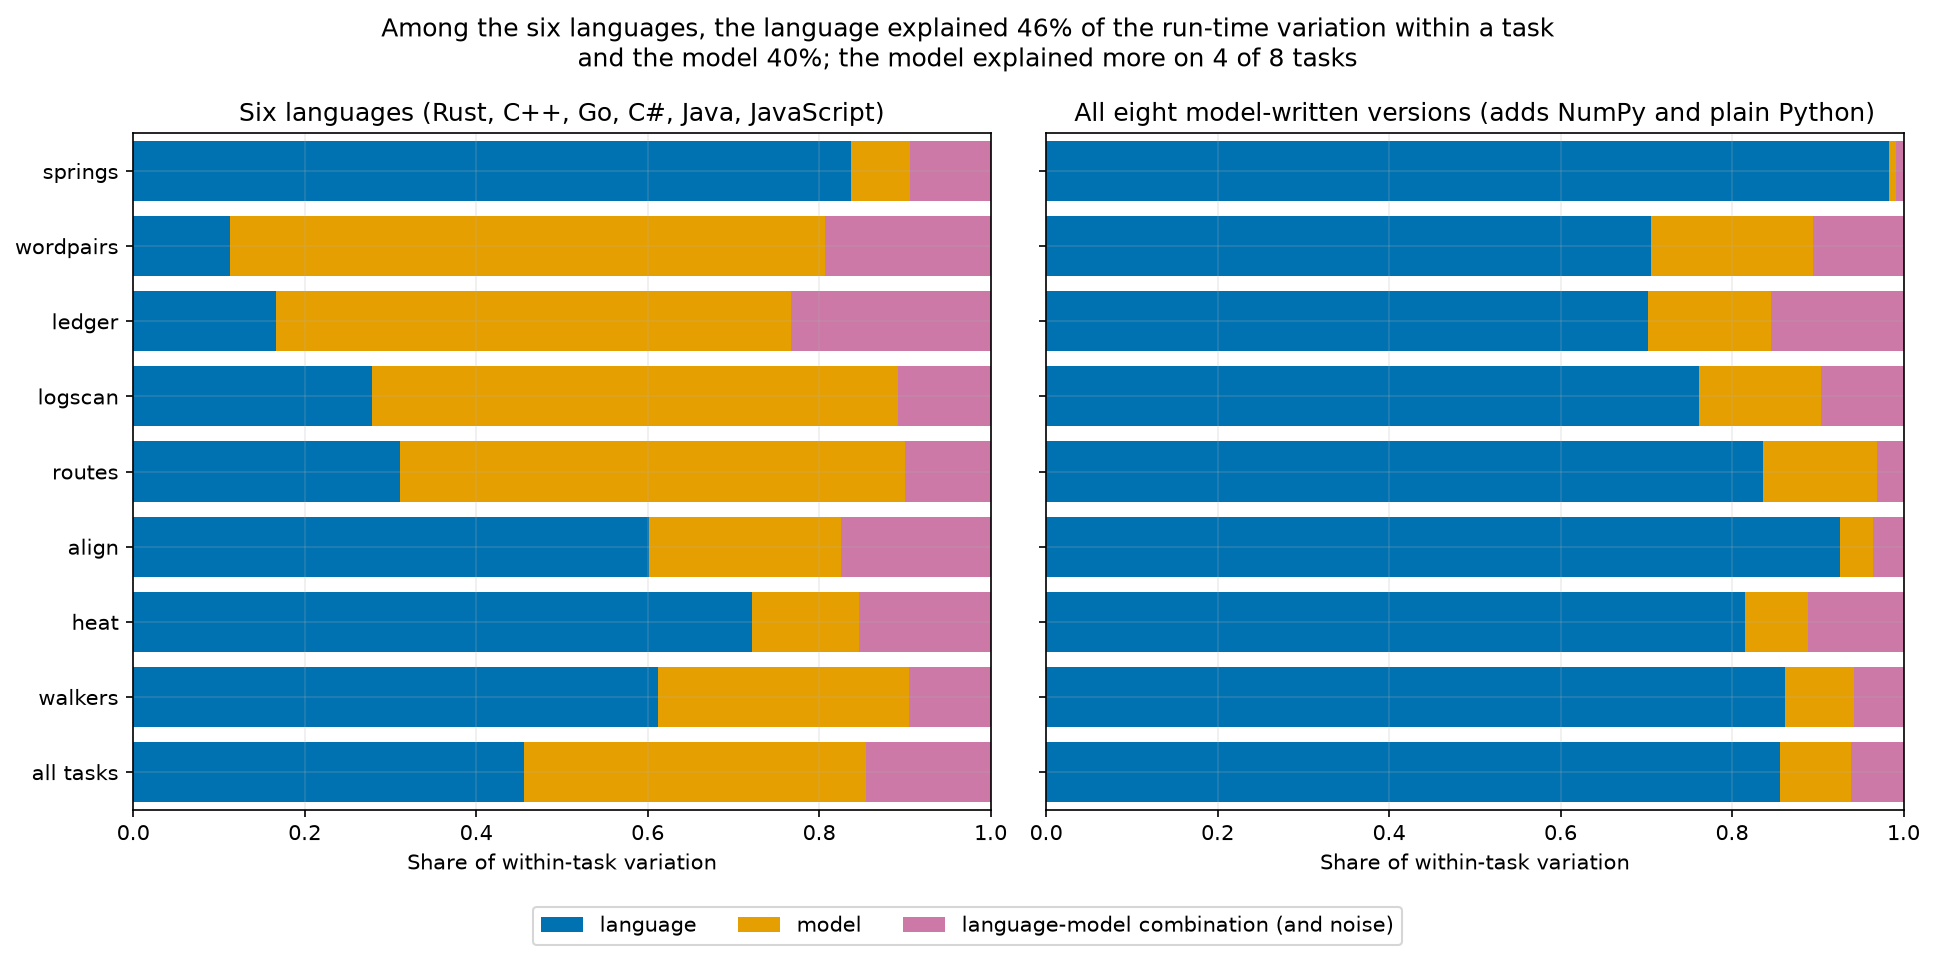

variant
rust     4.1
cpp      6.1
go       4.3
csharp   3.9
java     2.9
js       3.1
Name: spread, dtype: float64

author
opus55        3.8
sonnet        3.3
haiku         3.5
terra         3.6
wonder-full   3.7
wonder        3.1
deepseek      3.3
glm           3.2
nemotron      4.1
Name: spread, dtype: float64

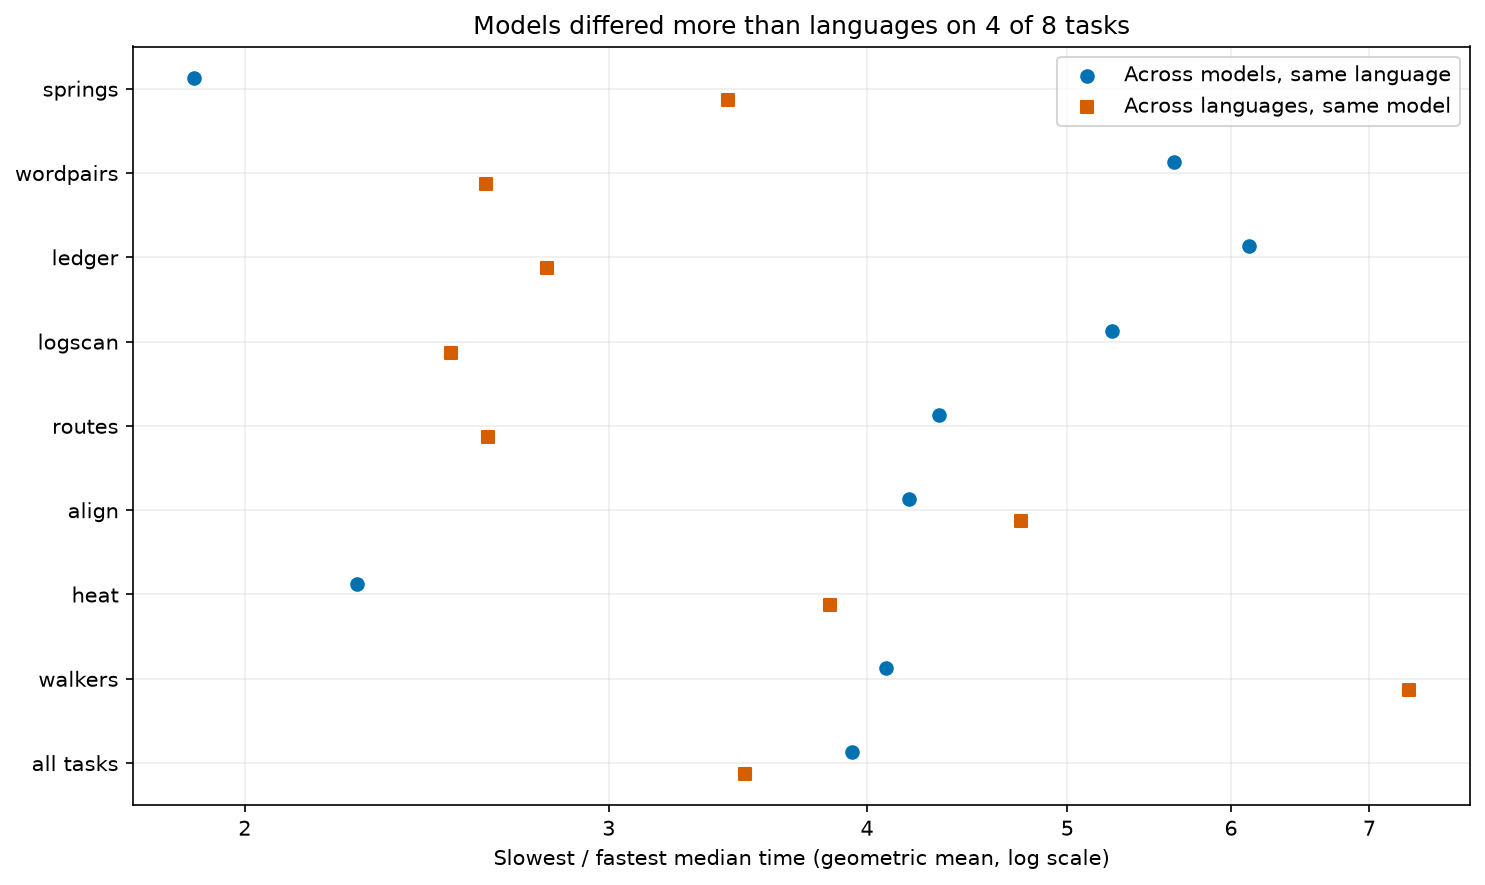

In [17]:
# Compute and present this analysis step for the reader.
# Least-squares decomposition, conditioning pooled comparisons on task.
def decomposition(d, pooled=False):
    d = d[d["median"] > 0].copy()
    if len(d) < 2:
        return None
    y = np.log10(d["median"].to_numpy())
    intercept = np.ones((len(d), 1))

    def dummy(col):
        return pd.get_dummies(d[col], drop_first=True, dtype=float).to_numpy()

    task = dummy("task") if pooled else np.empty((len(d), 0))
    lang = dummy("variant")
    model = dummy("author")
    base = np.column_stack([intercept, task])

    def sse(*xs):
        X = np.column_stack([base, *xs])
        residual = y - X @ np.linalg.lstsq(X, y, rcond=None)[0]
        return residual @ residual

    total = sse()
    if total < 1e-15:
        return None
    l = 1 - sse(lang) / total
    m = 1 - sse(model) / total
    a = 1 - sse(lang, model) / total
    return dict(language=a - m, model=a - l, shared=l + m - a, interaction=1 - a, n=len(d), total_ss=total)


rows = []
for scope, vs in [("six languages", LANGS), ("all model versions", MODEL_VERSIONS)]:
    d = median[median.author.isin(AUTHORS) & median.variant.isin(vs)]
    task_rows = []
    for t in TASKS:
        x = decomposition(d[d.task.eq(t)])
        if x:
            task_rows.append(dict(scope=scope, task=t, **x))
    rows.extend(task_rows)
    if task_rows:
        frame = pd.DataFrame(task_rows)
        pooled = {col: np.average(frame[col], weights=frame.total_ss) for col in ["language", "model", "shared", "interaction"]}
        rows.append(dict(scope=scope, task="all tasks", **pooled, n=int(frame.n.sum()), total_ss=frame.total_ss.sum(),
                         language_mean_share=frame.language.mean(), model_mean_share=frame.model.mean()))
lvm = pd.DataFrame(rows)
lvm.to_csv(DERIVED / "language_vs_model.csv", index=False)
shown_lvm = lvm.copy()
for col in ["language", "model", "shared", "interaction", "language_mean_share", "model_mean_share"]:
    shown_lvm.loc[shown_lvm[col].abs() < 0.0005, col] = 0
with pd.option_context("display.max_rows", None, "display.float_format", lambda x: f"{x:.3f}"):
    display(shown_lvm.round(3))
print("Pooled decomposition sample sizes:", lvm[lvm.task.eq("all tasks")].set_index("scope").n.to_dict())
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
segments = ["language", "model"] + (["shared"] if lvm.shared.abs().max() >= 0.005 else []) + ["interaction"]
colors = {"language": "#0072B2", "model": "#E69F00", "shared": "#999999", "interaction": "#CC79A7"}
segment_labels = {"language": "language", "model": "model", "shared": "overlap", "interaction": "language-model combination (and noise)"}
for ax, scope in zip(axes, ["six languages", "all model versions"]):
    d = lvm[lvm.scope.eq(scope)].set_index("task").reindex(TASKS + ["all tasks"])
    left = np.zeros(len(d))
    for col in segments:
        x = d[col].fillna(0).to_numpy()
        ax.barh(range(len(d)), x, left=left, color=colors[col], label=segment_labels[col])
        left += x
    ax.set(
        xlim=(0, 1),
        yticks=range(len(d)),
        yticklabels=TASKS + ["all tasks"],
        ylim=(len(d) - 0.5, -0.5),
        xlabel="Share of within-task variation",
        title={"six languages": "Six languages (Rust, C++, Go, C#, Java, JavaScript)", "all model versions": "All eight model-written versions (adds NumPy and plain Python)"}[scope],
    )
pooled = lvm[(lvm.scope == "six languages") & (lvm.task == "all tasks")]
task_comparison = lvm[(lvm.scope == "six languages") & (lvm.task != "all tasks")]
model_wins = int((task_comparison.model > task_comparison.language).sum())
figure_title = (f"Among the six languages, the language explained {pooled.iloc[0]['language']:.0%} of the run-time variation within a task\n"
                f"and the model {pooled.iloc[0]['model']:.0%}; the model explained more on {model_wins} of {len(task_comparison)} tasks") if len(pooled) else "Language and model effects: insufficient measured data"
fig.suptitle(figure_title)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0), ncol=4)
fig.tight_layout()
savefig("language_vs_model.png")
d = median[median.author.isin(AUTHORS) & median.variant.isin(LANGS)]
ms = (
    d.groupby(["task", "variant"])["median"]
    .agg(lambda x: x.max() / x.min() if len(x) >= 2 and x.min() > 0 else np.nan)
    .rename("spread")
    .reset_index()
)
ls = (
    d.groupby(["task", "author"])["median"]
    .agg(lambda x: x.max() / x.min() if len(x) >= 2 and x.min() > 0 else np.nan)
    .rename("spread")
    .reset_index()
)
display(ms.groupby("variant").spread.agg(geom).reindex(LANGS))
display(ls.groupby("author").spread.agg(geom).reindex(AUTHORS))
fig, ax = plt.subplots(figsize=(10, 6))
wins = 0
compared = 0
for i, t in enumerate(TASKS + ["all tasks"]):
    m = geom(ms.spread if t == "all tasks" else ms.loc[ms.task.eq(t), "spread"])
    l = geom(ls.spread if t == "all tasks" else ls.loc[ls.task.eq(t), "spread"])
    if t != "all tasks" and np.isfinite(m) and np.isfinite(l):
        compared += 1
        wins += l > m
    if np.isfinite(m):
        ax.scatter(m, i - 0.13, color="#0072B2", marker="o", label="Across models, same language" if i == 0 else None)
    if np.isfinite(l):
        ax.scatter(l, i + 0.13, color="#D55E00", marker="s", label="Across languages, same model" if i == 0 else None)
ax.set(
    xscale="log",
    yticks=range(len(TASKS) + 1),
    yticklabels=TASKS + ["all tasks"],
    ylim=(len(TASKS) + 0.5, -0.5),
    xlabel="Slowest / fastest median time (geometric mean, log scale)",
    title=(f"Languages differed more than models on {wins} of {compared} tasks" if wins > compared - wins else f"Models differed more than languages on {compared - wins} of {compared} tasks"),
)
plain_log_axis(ax)
ax.legend()
fig.tight_layout()
savefig("model_vs_language_spread.png")


Among the six languages, the language explained 46% of the variation within a task and the model 40%, with 14% left
for particular combinations and noise; the unweighted mean of the per-task shares gives 46% and 40% as well.

The tasks split into two kinds. Where the work is arithmetic, the language decided: springs 84% language against 7%
model, heat 72% against 12%, walkers 61% against 29% and align 60% against 22%. Where the work is reading text and
looking things up in tables, the model decided: wordpairs 11% language against 70% model, ledger 17% against 60%,
logscan 28% against 61% and routes 31% against 59%. On those tasks each model's choice of parser and table carried
across its six languages, so a model that wrote a fast byte scanner wrote one in all six, and a model that used a
general JSON library used it in several (section 19).

With NumPy and plain Python included, the language explained 86% and the model 8%. That says only that Python is far
slower than the other six languages; it does not mean the model stops mattering once a fast language is chosen.

In the ratio view, the nine models' programs in one language differed by a factor of 4.1 on average for Rust, 6.1
for C++, 4.3 for Go, 3.9 for C#, 2.9 for Java and 3.1 for JavaScript, while one model's six languages differed by
3.1 to 4.1. The widest of nine programs is naturally wider than the widest of six, so this view favours the model
somewhat; the split above has no such bias.

## 13. Which model wrote the fastest code

The model speed index of section 6 puts the nine models on one scale. For each task and version, each model's
median is divided by the geometric mean of the nine models' medians; a model's index is the geometric mean of those
ratios over its 64 programs (eight tasks times eight versions), with a 95% interval from resampling tasks. The cell
prints the indices, draws them (open-weight models shaded, dashed line at 1.0 for a typical model), breaks them down
by version in a heatmap, counts how often each model wrote the fastest and the slowest of the nine programs in a
cell, and plots the index against the model's median session length.

,author,index,ci_low,ci_high,cells,tasks
0,opus55,0.63,0.55,0.73,64,8
1,sonnet,0.83,0.75,0.91,64,8
2,haiku,0.96,0.87,1.1,64,8
3,terra,1.8,1.5,2.2,64,8
4,wonder-full,0.83,0.72,0.92,64,8
5,wonder,1.0,0.88,1.1,64,8
6,deepseek,0.85,0.77,0.94,64,8
7,glm,1.0,0.94,1.2,64,8
8,nemotron,1.5,1.3,1.7,64,8


Speed index cells per model: {'opus55': 64, 'sonnet': 64, 'haiku': 64, 'terra': 64, 'wonder-full': 64, 'wonder': 64, 'deepseek': 64, 'glm': 64, 'nemotron': 64}


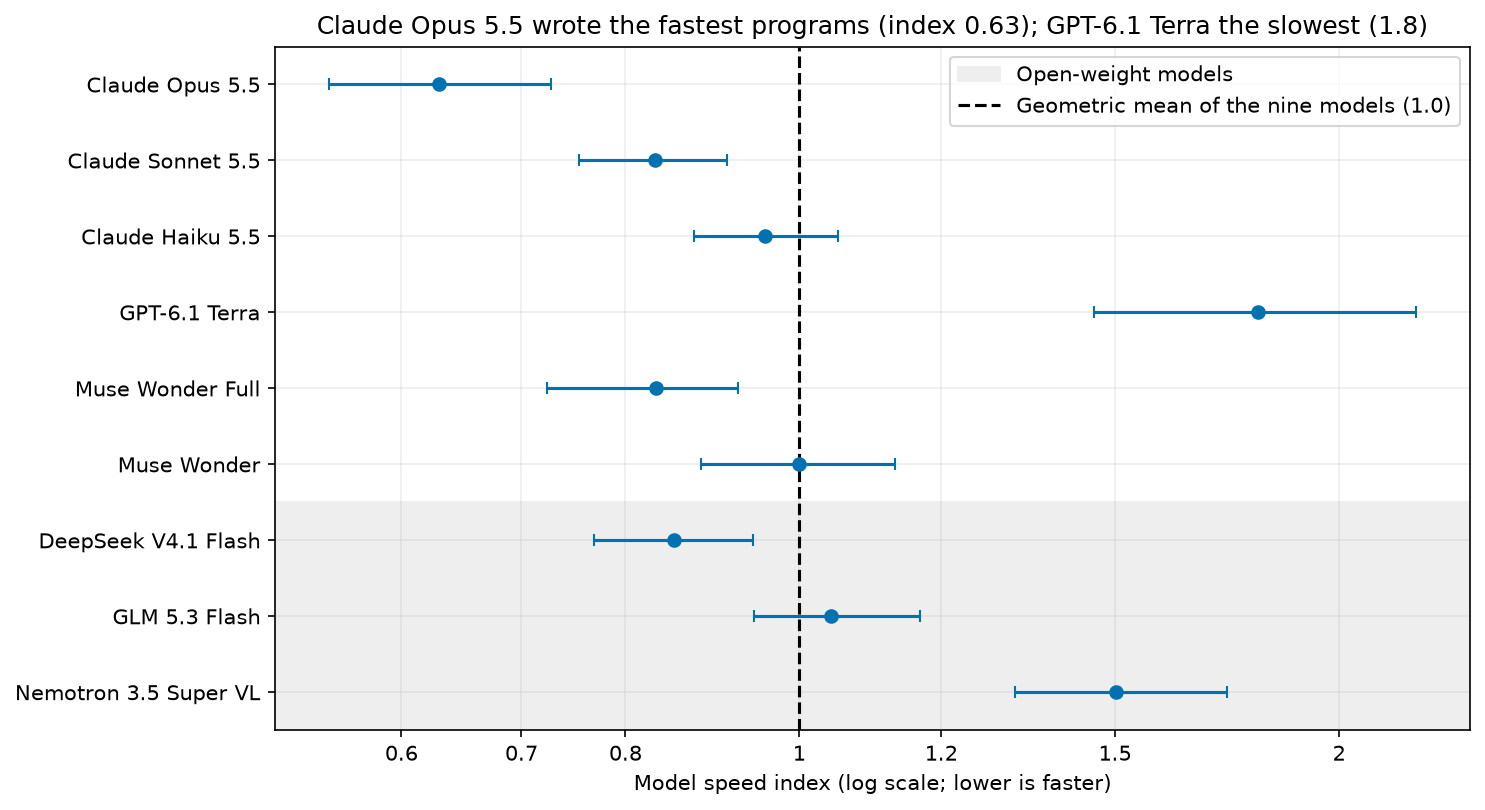

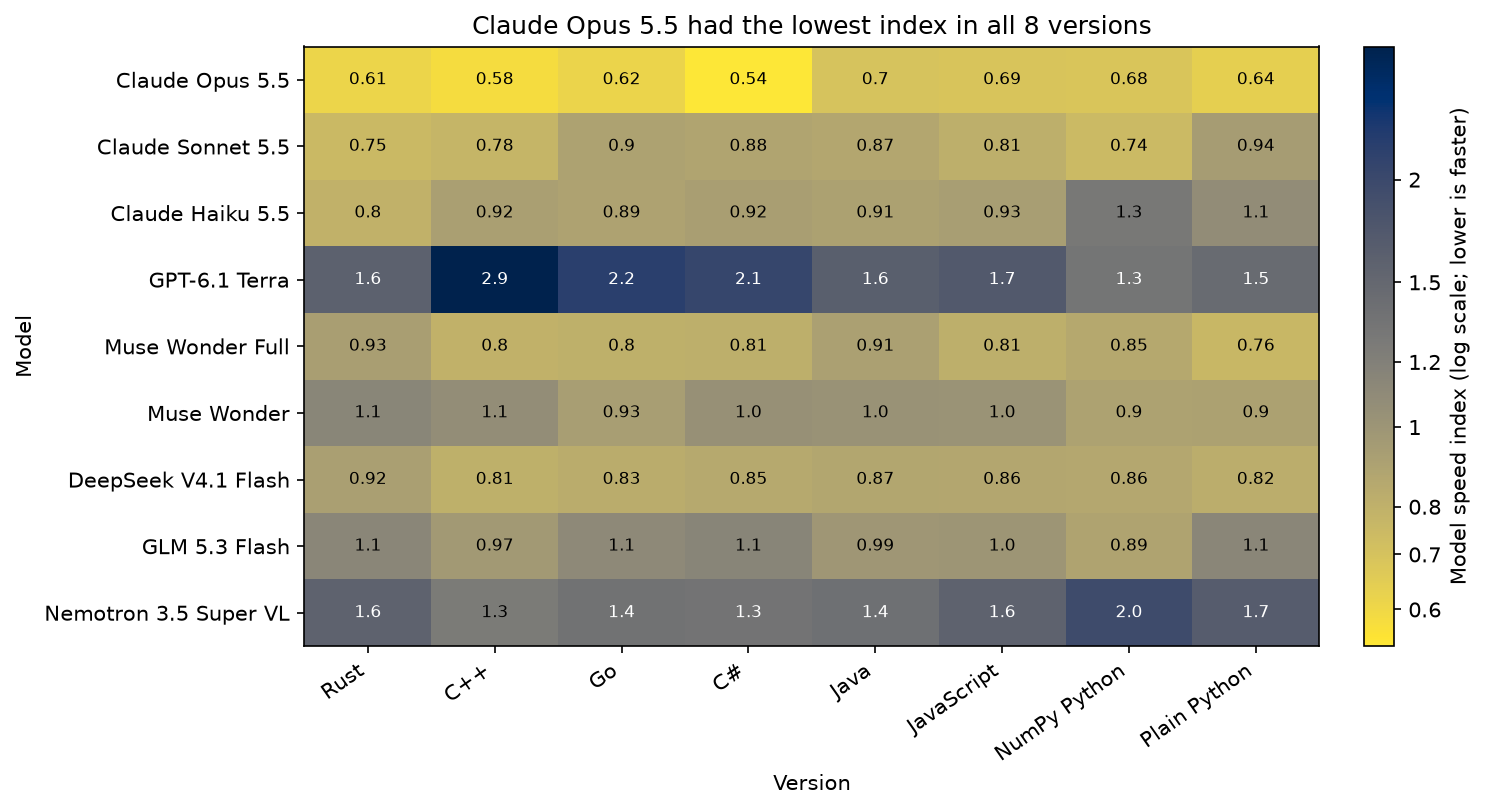

,fastest,slowest
author,,
opus55,38,0
sonnet,7,1
haiku,0,7
terra,0,28
wonder-full,8,2
wonder,5,3
deepseek,5,0
glm,1,2
nemotron,0,21


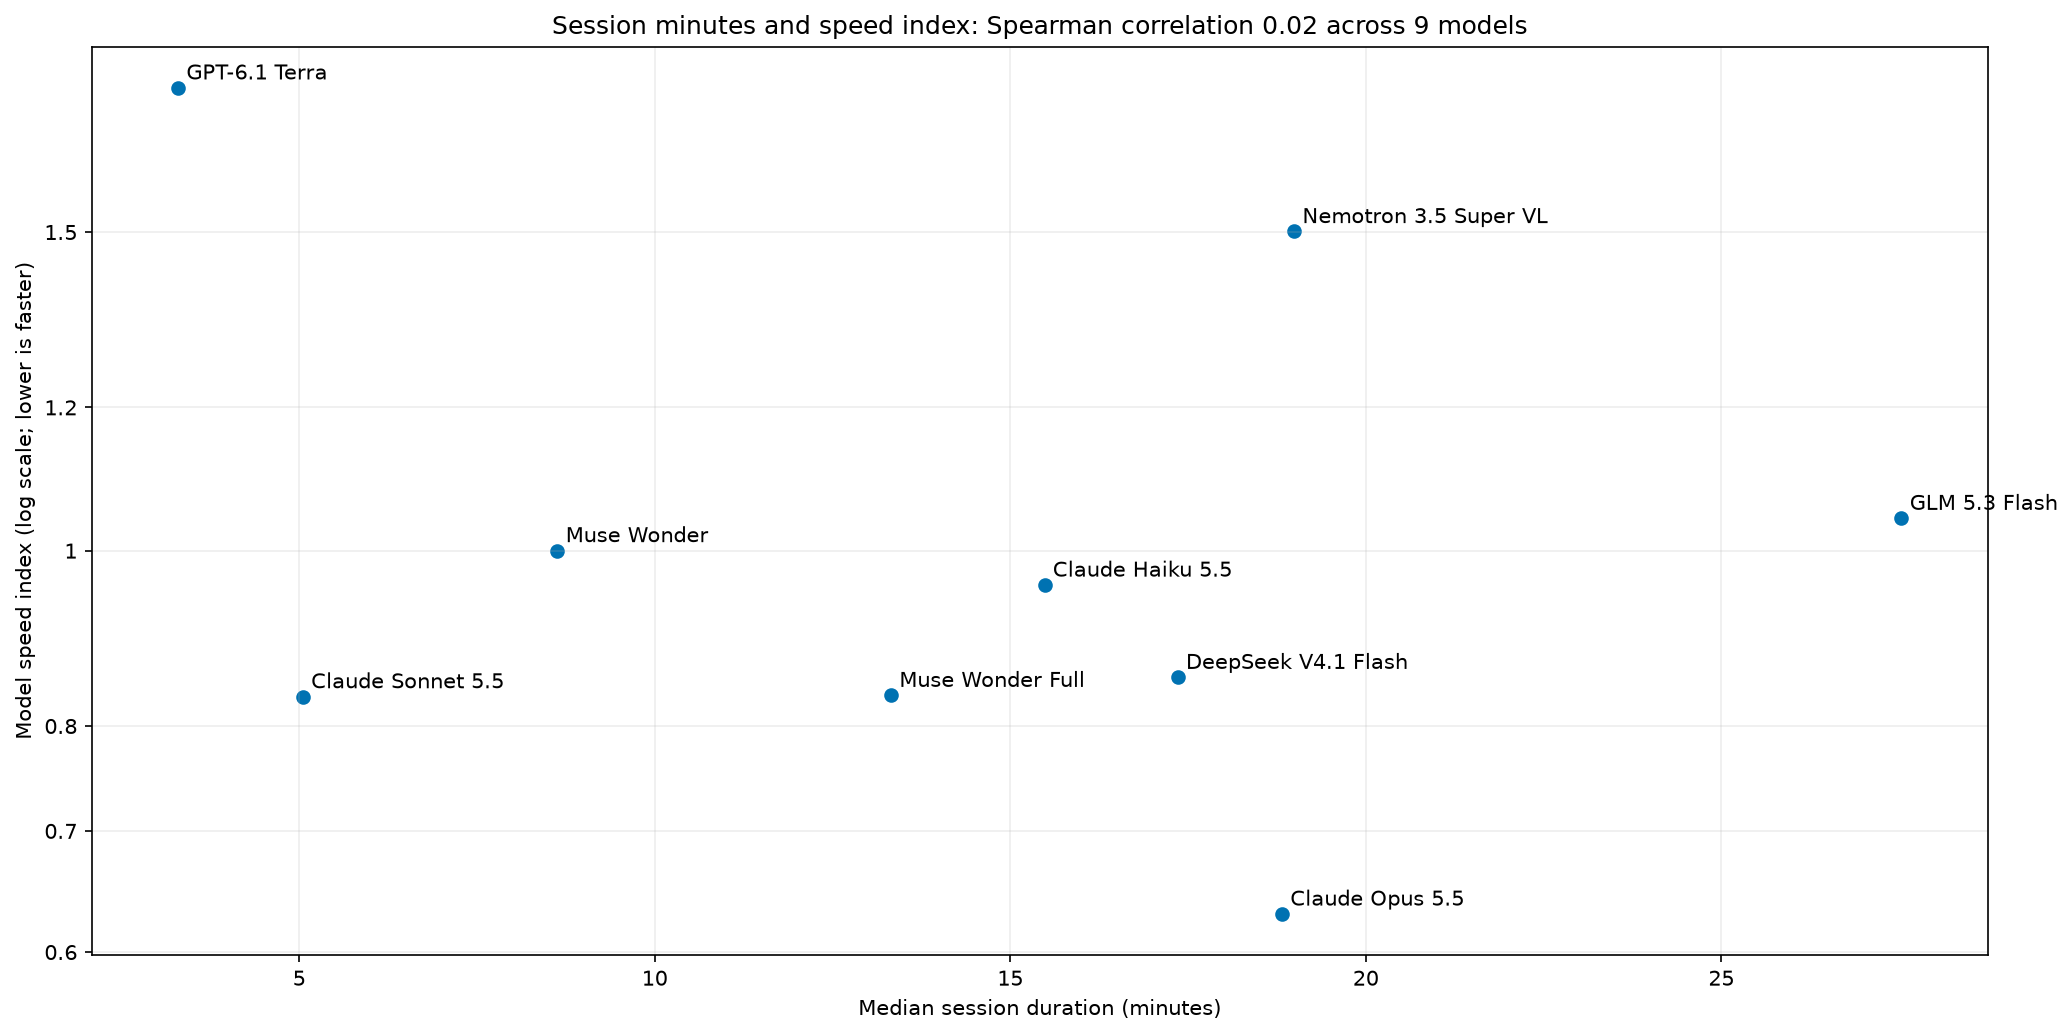

In [18]:
# Compute and present this analysis step for the reader.
d = median[median.author.isin(AUTHORS) & median.variant.isin(MODEL_VERSIONS) & (median["median"] > 0)].copy()
d = d.groupby(["task", "variant"]).filter(lambda g: g.author.nunique() >= 5)
d["index"] = d["median"] / d.groupby(["task", "variant"])["median"].transform(geom)
rows = []
for a in AUTHORS:
    x = d[d.author.eq(a)]
    g, lo, hi = task_bootstrap(x, "index")
    rows.append(dict(author=a, index=g, ci_low=lo, ci_high=hi, cells=len(x), tasks=x.task.nunique()))
model_speed = pd.DataFrame(rows)
model_speed.to_csv(DERIVED / "model_speed.csv", index=False)
display(model_speed)
print("Speed index cells per model:", model_speed.set_index("author").cells.to_dict())
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.axhspan(5.5, 8.5, color="#eeeeee", label="Open-weight models")
for i, r in enumerate(model_speed.itertuples()):
    if np.isfinite(r.index):
        ax.errorbar(
            r.index, i, xerr=[[r.index - r.ci_low], [r.ci_high - r.index]], fmt="o", color="#0072B2", capsize=3
        )
ax.axvline(1, color="black", ls="--", label="Geometric mean of the nine models (1.0)")
ax.set(
    xscale="log",
    yticks=range(len(AUTHORS)),
    yticklabels=[MODEL_LABELS[a] for a in AUTHORS],
    ylim=(len(AUTHORS) - 0.5, -0.5),
    xlabel="Model speed index (log scale; lower is faster)",
    title=f"Model speed index across {d.task.nunique()} tasks with at least five models",
)
valid_models = model_speed.dropna(subset=["index"]).set_index("author")["index"]
ax.set_title(
    f"{MODEL_LABELS[valid_models.idxmin()]} wrote the fastest programs (index {format_number(valid_models.min())}); "
    f"{MODEL_LABELS[valid_models.idxmax()]} the slowest ({format_number(valid_models.max())})"
    if len(valid_models)
    else "No model speed indices available"
)
plain_log_axis(ax)
ax.legend()
fig.tight_layout()
savefig("model_speed.png")
grid = (
    d.groupby(["author", "variant"])["index"]
    .agg(geom)
    .unstack("variant")
    .reindex(index=AUTHORS, columns=MODEL_VERSIONS)
)
fig, ax = plt.subplots(figsize=(10, 5.5))
heatmap(ax, grid, log=True, label="Model speed index (log scale; lower is faster)")
winner_counts = grid.dropna(axis=1, how="all").idxmin().value_counts()
winner_title = (
    f"{MODEL_LABELS[winner_counts.index[0]]} had the lowest index in "
    f"all {winner_counts.iloc[0]} versions" if winner_counts.iloc[0] == grid.notna().any().sum() else f"{MODEL_LABELS[winner_counts.index[0]]} had the lowest index in {winner_counts.iloc[0]} of {grid.notna().any().sum()} versions"
    if len(winner_counts)
    else "No model speed indices available"
)
ax.set(title=winner_title, xlabel="Version", ylabel="Model")
fig.tight_layout()
savefig("model_speed_heatmap.png")
if len(d):
    extrema = (
        d.assign(
            fastest=d["median"].eq(d.groupby(["task", "variant"])["median"].transform("min")),
            slowest=d["median"].eq(d.groupby(["task", "variant"])["median"].transform("max")),
        )
        .groupby("author")[["fastest", "slowest"]]
        .sum()
        .reindex(AUTHORS, fill_value=0)
    )
    display(extrema)
else:
    display(pd.DataFrame(0, index=AUTHORS, columns=["fastest", "slowest"]))
fig, ax = plt.subplots(figsize=(14, 7))
x = sessions[sessions.author.isin(AUTHORS)].groupby("author").minutes.median()
for r in model_speed.itertuples():
    if r.author in x and np.isfinite(r.index) and x[r.author] > 0:
        ax.scatter(x[r.author], r.index, color="#0072B2")
        ax.annotate(MODEL_LABELS[r.author], (x[r.author], r.index), xytext=(4, 4), textcoords="offset points")
paired = model_speed.set_index("author")["index"].to_frame().join(x.rename("minutes")).dropna()
paired = paired[paired.minutes > 0]
correlation = paired["minutes"].corr(paired["index"], method="spearman") if len(paired) >= 2 else np.nan
correlation_title = (
    f"Session minutes and speed index: Spearman correlation {correlation:.2f} across {len(paired)} models"
    if np.isfinite(correlation)
    else f"Session minutes and speed index: correlation unavailable ({len(paired)} models)"
)
ax.set(
    yscale="log",
    xlabel="Median session duration (minutes)",
    ylabel="Model speed index (log scale; lower is faster)",
    title=correlation_title,
)
plain_log_axis(ax, "y")
fig.tight_layout()
savefig("model_effort_vs_speed.png")


| Model | Speed index (95% interval) | Fastest of nine | Slowest of nine |
|---|---|---|---|
| Claude Opus 5.5 | 0.63 (0.55 to 0.73) | 38 | 0 |
| Claude Sonnet 5.5 | 0.83 (0.75 to 0.91) | 7 | 1 |
| Muse Wonder Full | 0.83 (0.72 to 0.92) | 8 | 2 |
| DeepSeek V4.1 Flash | 0.85 (0.77 to 0.94) | 5 | 0 |
| Claude Haiku 5.5 | 0.96 (0.87 to 1.05) | 0 | 7 |
| Muse Wonder | 1.00 (0.88 to 1.13) | 5 | 3 |
| GLM 5.3 Flash | 1.04 (0.94 to 1.17) | 1 | 2 |
| Nemotron 3.5 Super VL | 1.50 (1.32 to 1.73) | 0 | 21 |
| GPT-6.1 Terra | 1.80 (1.46 to 2.21) | 0 | 28 |

Claude Opus 5.5 wrote the fastest code: its programs took about two thirds of a typical model's time, were the
fastest of the nine in 38 of the 64 task-and-version cells and never the slowest. GPT-6.1 Terra (1.80) and Nemotron
(1.50) were slowest and wrote 49 of the 64 slowest programs between them. The six models in the middle, from 0.83 to
1.04, have overlapping intervals, and their order could change in a second set of sessions.

By version, Opus had the lowest index in all eight, from 0.54 in C# to 0.70 in Java, so its lead was not one
language's. Terra's index was highest in C++ (2.9), Go (2.2) and C# (2.1), the languages where it parsed with
general libraries, and Nemotron's in NumPy Python (2.0).

Within a company, the larger model wrote faster code: Opus (0.63) ahead of Sonnet (0.83) and Haiku (0.96), and
Wonder Full (0.83) ahead of Wonder (1.00). Across companies, size and openness did not sort the models: the
open-weight DeepSeek was level with Sonnet and Wonder Full, while Terra, a closed model, was slowest.

Longer sessions did not buy faster code. The rank correlation between a model's median session length and its index
is 0.02 across the nine models: Opus spent 19 minutes per session and wrote the fastest code, Nemotron spent as long
with the most tool calls and wrote nearly the slowest, and GLM had the longest sessions and a middling index. Terra
is the one model where little effort and slow code went together: the shortest sessions, the fewest output tokens
and the shortest code (127 kB over 64 programs against 304 to 448 kB, section 18). In cost, Opus's sessions came to
five times Sonnet's for programs about a quarter faster, and DeepSeek matched Sonnet's speed at about the same price.

The next cell compares the heat programs of every model with those of the two pilot models, Claude Opus 5.5 and
GPT-6.1 Sol, which wrote heat in Rust and both Pythons only, in the first test of the pipeline on 2026-10-30. The
last column divides Opus's main-run times by its pilot times.

In [19]:
pilot=median[(median.task=='heat') & median.author.isin(['opus','sol']+AUTHORS) & median.variant.isin(['rust','plain','fast'])].pivot(index='variant',columns='author',values='median').reindex(index=['rust','plain','fast'],columns=['opus','sol']+AUTHORS)
pilot['opus55 / opus']=pilot['opus55']/pilot['opus']; display(pilot)


author,opus,sol,opus55,sonnet,haiku,terra,wonder-full,wonder,deepseek,glm,nemotron,opus55 / opus
variant,,,,,,,,,,,,
rust,0.038,0.037,0.037,0.054,0.041,0.16,0.081,0.07,0.052,0.054,0.18,0.98
plain,0.59,0.95,0.47,0.87,1.0,6.8,0.99,0.88,0.85,9.8,6.1,0.79
fast,0.4,0.33,0.35,0.39,0.37,0.39,0.46,0.38,0.38,0.45,1.8,0.87


The two pilot models' heat Rust took 0.038 and 0.037 s, level with the main-run Opus (0.037 s) and Haiku (0.041 s)
and faster than every other model's. Opus's two heat sessions, six days apart, gave Rust programs within 3% of
each other and plain Python of 0.59 and 0.47 s, both packed integers. That is one repeat of one model on one task,
but it fits the model's choices being fairly stable between sessions.

## 14. Start-up cost

Every runtime pays a fixed cost before it does any work. The next cell runs a program that prints one word and
exits, 20 times in each runtime, and draws the median start-up time and peak memory as bars.

,startup_s,working_set_MB,repeats
version,,,
Rust,0.027,4.5,20
C++,0.028,4.0,20
Go,0.03,6.0,20
C#,0.083,22,20
Java,0.11,42,20
JavaScript,0.079,27,20
NumPy Python,0.26,26,20
Plain Python,0.1,14,20


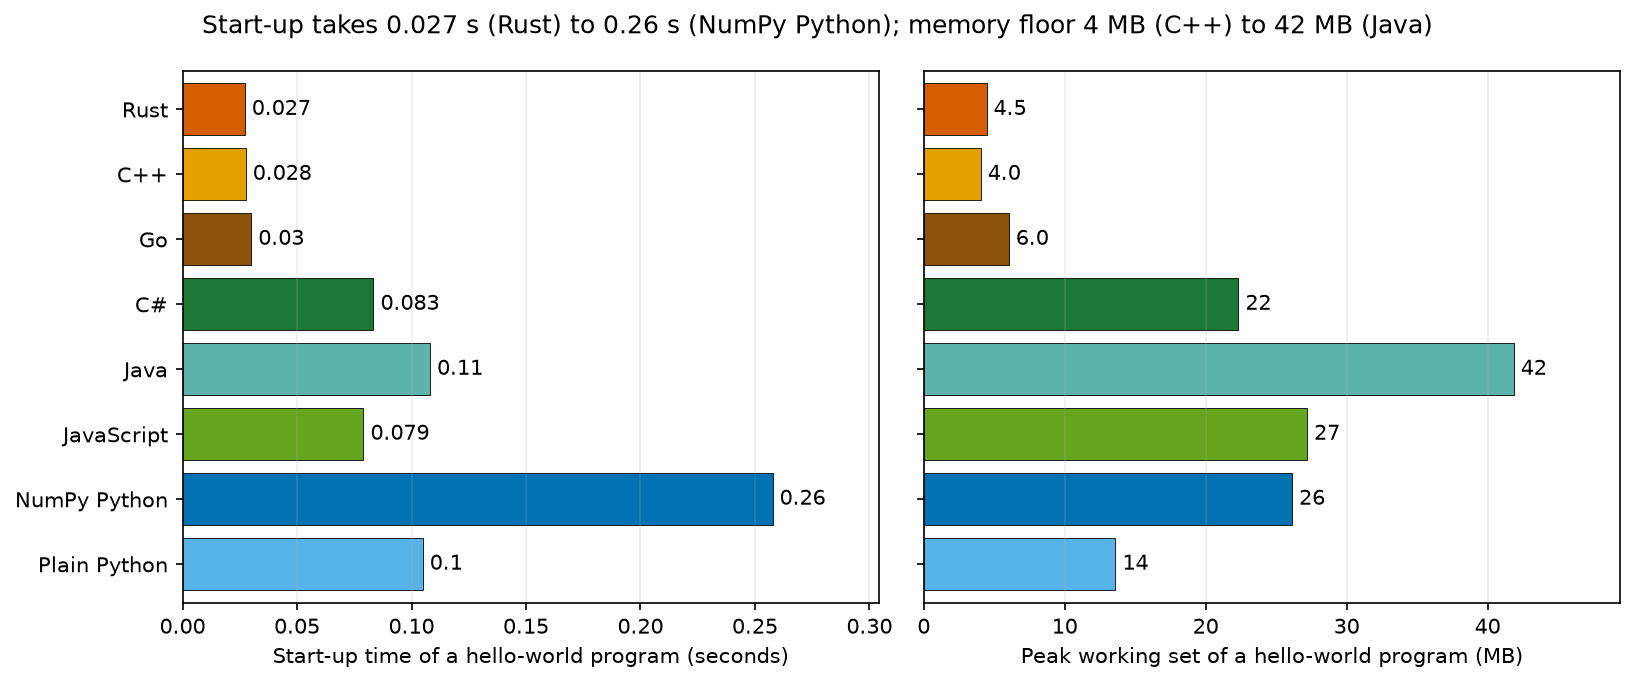

In [20]:
# Compute and present this analysis step for the reader.
# Hello-world programs in every runtime: the cost of starting the runtime before any task work happens.
BASE_VERSION = dict(
    python="plain", numpy="fast", rust="rust", cpp="cpp", go="go", csharp="csharp", java="java", js="js"
)
bl = baseline.copy()
bl["version"] = bl.variant.map(BASE_VERSION)
floor = (
    bl.groupby("version")
    .agg(
        startup_s=("wall_seconds", "median"),
        working_set_MB=("peak_working_set", lambda x: x.median() / 1e6),
        repeats=("wall_seconds", "size"),
    )
    .reindex([v for v in VERSIONS if v != "simple"])
)
display(floor.rename(index=LABELS).round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, col, xl in zip(
    axes,
    ["startup_s", "working_set_MB"],
    ["Start-up time of a hello-world program (seconds)", "Peak working set of a hello-world program (MB)"],
):
    ys = range(len(floor))
    ax.barh(list(ys), floor[col], color=[COLORS[v] for v in floor.index], edgecolor="black", linewidth=0.4)
    for y, (v, x) in zip(ys, floor[col].items()):
        if pd.notna(x):
            ax.text(x, y, f" {format_number(x)}", va="center", fontsize=10)
    ax.set(
        yticks=list(ys),
        yticklabels=[LABELS[v] for v in floor.index],
        xlabel=xl,
        ylim=(len(floor) - 0.4, -0.6),
        xlim=(0, floor[col].max() * 1.18 if floor[col].notna().any() else 1),
    )
    ax.grid(axis="y", visible=False)
axes[1].set_yticklabels([])
slow_s, fast_s = (
    (floor.startup_s.idxmax(), floor.startup_s.idxmin()) if floor.startup_s.notna().any() else ("rust", "rust")
)
big_m, small_m = (
    (floor.working_set_MB.idxmax(), floor.working_set_MB.idxmin())
    if floor.working_set_MB.notna().any()
    else ("rust", "rust")
)
fig.suptitle(
    f"Start-up takes {floor.startup_s.min():.3f} s ({LABELS[fast_s]}) "
    f"to {floor.startup_s.max():.2f} s ({LABELS[slow_s]}); memory "
    f"floor {floor.working_set_MB.min():.0f} MB ({LABELS[small_m]}) "
    f"to {floor.working_set_MB.max():.0f} MB ({LABELS[big_m]})",
    fontsize=12,
)
fig.tight_layout()
savefig("startup_floor.png")


An empty program took 0.027 s and 4.5 MB in Rust, 0.028 s and 4.0 MB in C++, 0.030 s and 6.0 MB in Go, 0.079 s and
27 MB in Node.js, 0.083 s and 22 MB in .NET, 0.10 s and 14 MB in Python, 0.11 s and 42 MB in Java, and 0.26 s and
26 MB in Python that imports NumPy. Windows starts processes more slowly than Linux, so all of these are higher than
they would be on a Linux server, but their order would be the same. These floors explain much of the small-input
results in section 16 and part of every short task's time.

## 15. Memory

The figure has the same layout as the run-time figure, with peak memory in megabytes on a logarithmic x-axis. The
table after it gives each version's geometric-mean memory relative to the same model's smallest version on each
task.

author,opus55,sonnet,haiku,terra,wonder-full,wonder,deepseek,glm,nemotron
variant,,,,,,,,,
rust,1.1,1.5,1.1,1.3,1.5,1.9,1.4,2.0,2.1
cpp,1.1,1.0,1.1,1.1,2.2,1.8,1.7,1.9,1.7
go,1.7,1.5,1.5,1.8,3.2,2.4,2.3,2.4,2.9
csharp,3.4,3.2,3.4,4.0,6.0,4.5,4.7,4.5,4.5
java,6.3,5.7,6.3,9.1,11,8.4,8.4,8.4,8.9
js,4.6,4.0,4.8,6.1,8.2,5.8,6.1,5.7,6.9
fast,8.1,5.6,9.6,4.2,8.0,7.7,6.8,7.5,8.7
plain,5.0,4.1,4.4,4.0,3.7,6.6,5.0,3.8,4.0
simple,4.7,4.2,4.6,4.6,4.8,3.7,4.6,3.7,3.5


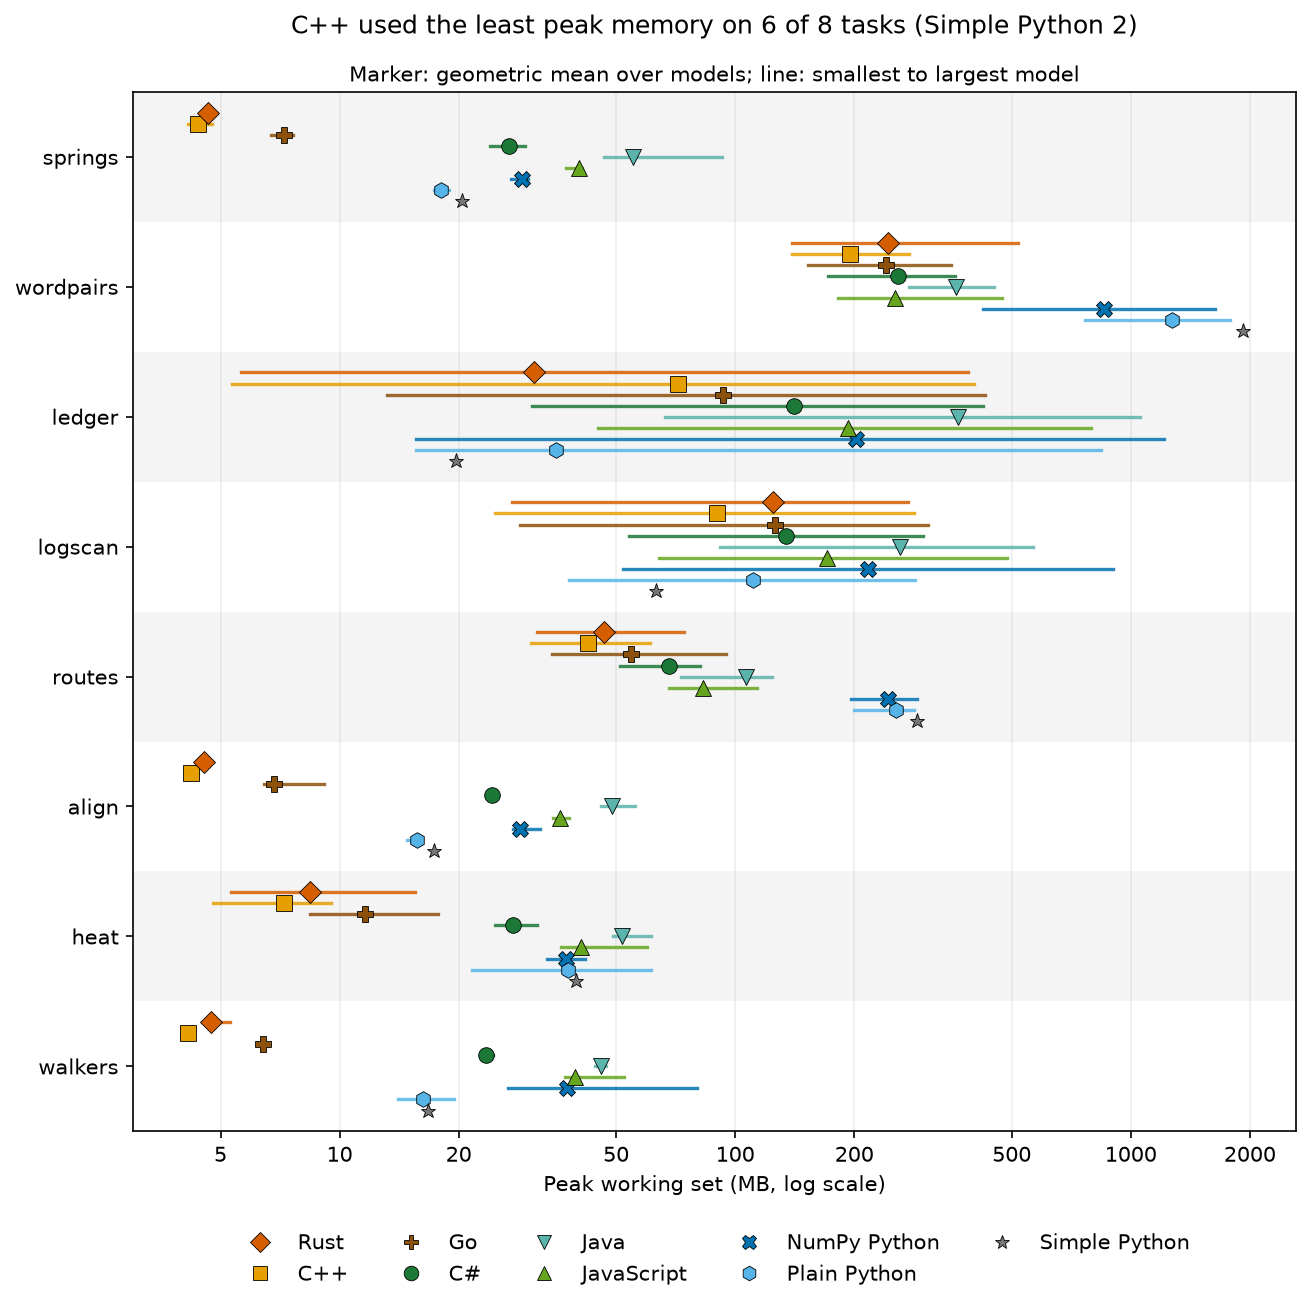

In [21]:
mem=full[full.author.isin(AUTHORS+['reference'])].copy(); mem['memory_MB']=mem.peak_working_set/1e6
memory=mem.groupby(['task','author','variant']).memory_MB.median().reset_index(); memory.to_csv(DERIVED/'memory.csv',index=False)
rows=[]
for a in AUTHORS:
    for t in TASKS:
        vals={v:memory[(memory.task==t)&(memory.author==('reference' if v=='simple' else a))&(memory.variant==v)].memory_MB for v in VERSIONS}
        vals={v:x.iloc[0] for v,x in vals.items() if len(x) and x.iloc[0]>0}
        if vals:
            low=min(vals.values()); rows.extend(dict(author=a,variant=v,ratio=x/low) for v,x in vals.items())
mr=pd.DataFrame(rows,columns=['author','variant','ratio'])
display(mr.groupby(['variant','author']).ratio.agg(geom).unstack('author').reindex(index=VERSIONS,columns=AUTHORS))
mem_comb=combine_authors(memory,'memory_MB'); title,_=winners_title(mem_comb,'used the least peak memory')
fig,ax=plt.subplots(figsize=(10,9)); strip_by_task(ax,mem_comb,'Peak working set (MB, log scale)'); ax.set_title(title, pad=28); ax.text(.5,1.01,'Marker: geometric mean over models; line: smallest to largest model',transform=ax.transAxes,ha='center'); ax.legend(handles=version_handles(ls='none'),loc='upper center',bbox_to_anchor=(.5,-.08),ncol=5,frameon=False); savefig('memory_by_task.png')


Relative to each model's smallest version on each task, C++ needed 1.0 to 2.2 times the smallest (geometric mean
over tasks, range over the nine models), Rust 1.1 to 2.1, Go 1.5 to 3.2, C# 3.2 to 6.0, JavaScript 4.0 to 8.2, Java
5.7 to 11, plain Python 3.7 to 6.6 and NumPy Python 4.2 to 9.6.

On small-data tasks the difference is mostly the runtime itself: a few megabytes for the compiled languages against
tens for the virtual machines and Python. On large-data tasks it is how data is stored. The plain-Python wordpairs
programs, which keep about 4 million word pairs as Python objects, peaked at 0.8 to 1.8 GB and the simple reference
at 1.9 GB, against 0.14 to 0.27 GB for the models' C++. Java's virtual machine lets its heap grow before collecting
garbage, which is why Java used more memory than Python on several tasks.

## 16. Small inputs and start-up time

Wordpairs, routes and heat were also run at 1/256, 1/64, 1/16 and 1/4 of the benchmark size, three timed runs each.
Each panel is one task, with input size and run time on logarithmic axes and one line per version (geometric mean
of the nine models). The first table gives each version's slope between the two largest sizes (1 means time grows
in proportion to input; near 0 means the time is mostly fixed cost); the second gives each version's time relative
to Rust at each size.

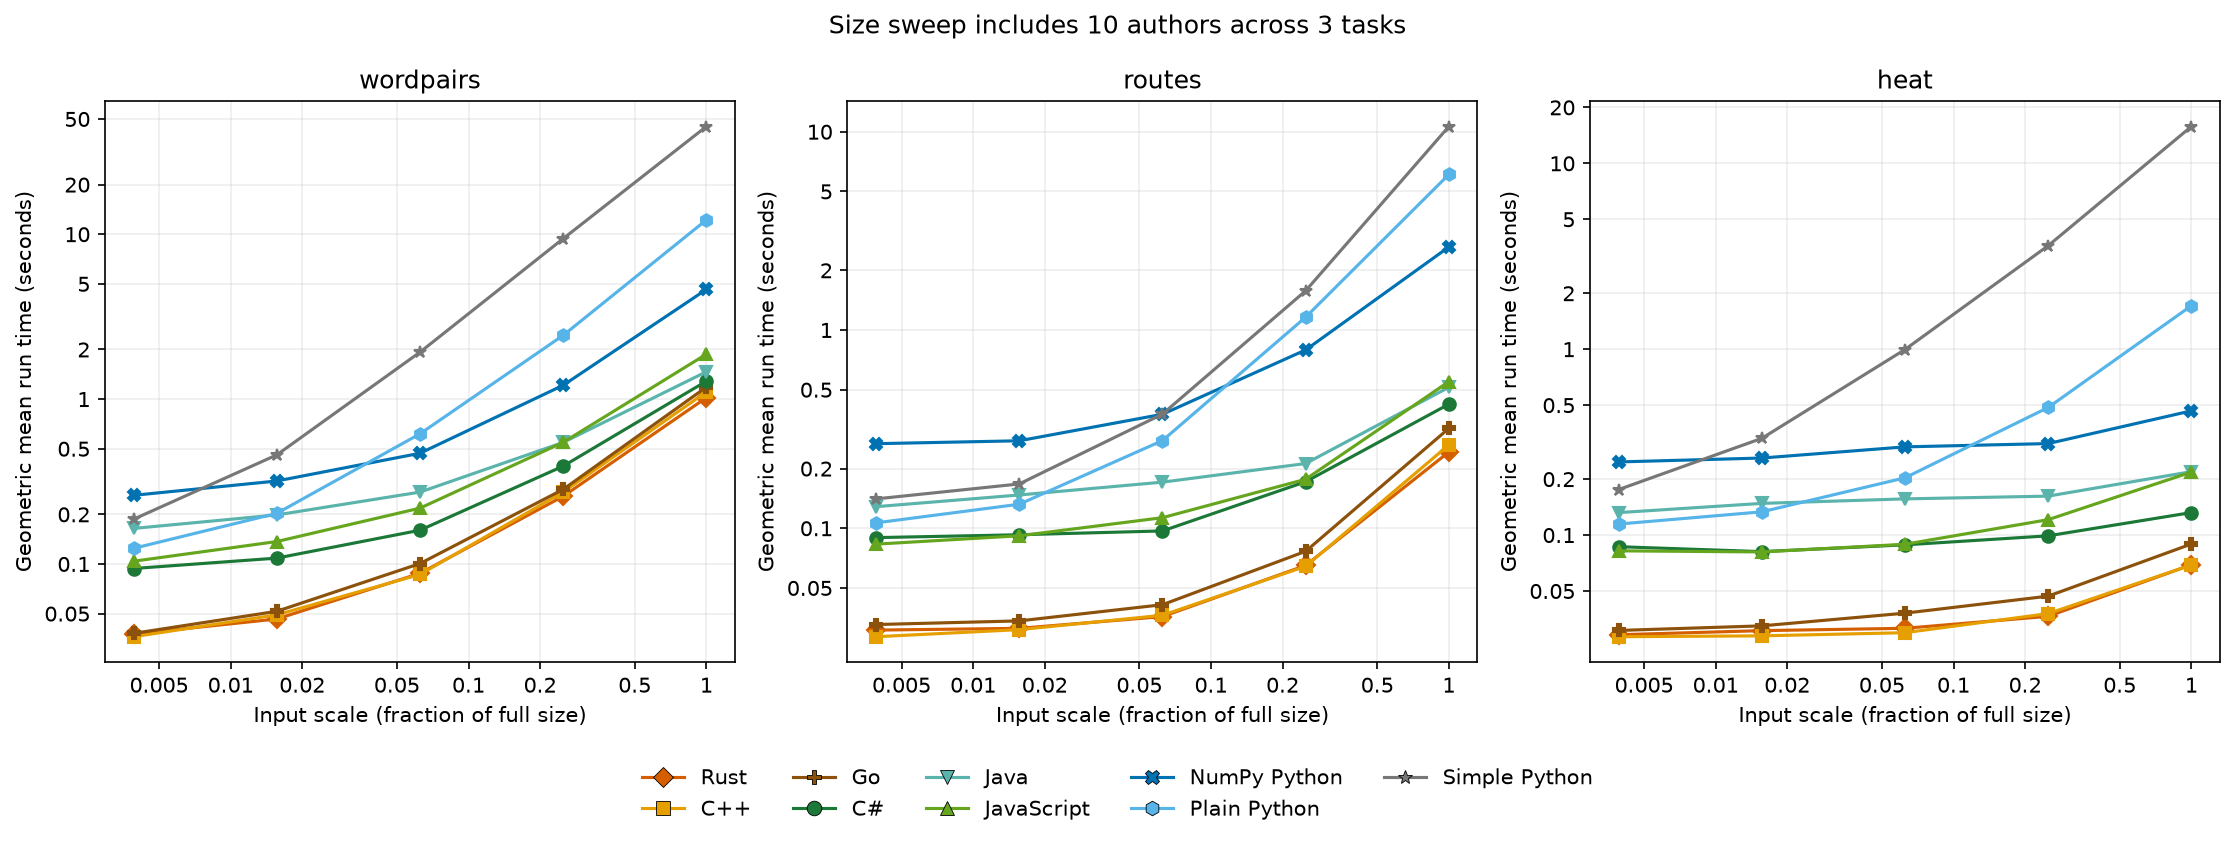

variant,rust,cpp,go,csharp,java,js,fast,plain,simple
task,,,,,,,,,
heat,0.33,0.41,0.48,0.21,0.19,0.45,0.23,0.9,1.1
routes,0.85,0.95,0.97,0.69,0.58,0.78,0.81,1.3,1.4
wordpairs,1.0,0.99,1.0,0.84,0.68,0.88,0.9,1.2,1.1


variant           rust  cpp  go  csharp  java  js  fast  plain  simple
task      scale                                                       
heat      0.0039     1 0.98 1.1     3.0   4.5 2.8   8.5    3.9     6.0
          0.016      1 0.94 1.1     2.7   4.8 2.7   8.5    4.4      11
          0.062      1 0.95 1.2     2.8   5.0 2.8   9.5    6.5      32
          0.25       1  1.0 1.3     2.7   4.4 3.3   8.5     13      99
          1          1    1 1.3     1.9   3.2 3.2   6.7     25     228
routes    0.0039     1 0.93 1.1     2.9   4.2 2.7   8.7    3.5     4.6
          0.016      1 0.99 1.1     3.0   4.7 2.9   8.8    4.2     5.3
          0.062      1  1.0 1.1     2.7   4.8 3.2    10    7.7      11
          0.25       1 0.99 1.2     2.6   3.3 2.7    12     18      24
          1          1  1.1 1.3     1.7   2.1 2.3    11     25      44
wordpairs 0.0039     1 0.96 1.0     2.5   4.4 2.8   6.9    3.3     5.0
          0.016      1  1.1 1.1     2.3   4.3 2.9   6.9    4.4     9.9
          0.062      1 0.98 1.1     1.8   3.1 2.5   5.3    7.0      22
          0.25       1  1.1 1.1     1.5   2.1 2.1   4.7    9.5      37
          1          1  1.1 1.2     1.3   1.4 1.8   4.5     12      44

In [22]:
# Compute and present this analysis step for the reader.
sw = pd.concat(
    [sweep, runs[runs.task.isin(["wordpairs", "routes", "heat"]) & runs.input.eq("full")]], ignore_index=True
)
sw = sw[sw.author.isin(AUTHORS + ["reference"]) & sw.status.eq("correct")].merge(ok, on=["author", "task", "variant"])
sw["scale"] = [entries.get((r.task, r.input), {}).get("scale", np.nan) for r in sw.itertuples()]
sm = sw.groupby(["task", "author", "variant", "scale"]).wall_seconds.median().reset_index()
smc = sm.groupby(["task", "variant", "scale"]).wall_seconds.agg(geom).reset_index(name="gm")
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, t in zip(axes, ["wordpairs", "routes", "heat"]):
    for v in VERSIONS:
        d = smc[(smc.task == t) & (smc.variant == v)].sort_values("scale")
        ax.plot(d.scale, d.gm, marker=MARKERS[v], color=COLORS[v])
    if smc[smc.task.eq(t)].empty:
        ax.set_xlim(0.001, 1)
        ax.set_ylim(0.001, 1)
    ax.set(
        xscale="log",
        yscale="log",
        title=t,
        xlabel="Input scale (fraction of full size)",
        ylabel="Geometric mean run time (seconds)",
    )
    plain_log_axis(ax, "x")
    plain_log_axis(ax, "y")
fig.suptitle(f"Size sweep includes {sm.author.nunique()} authors across {sm.task.nunique()} tasks")
fig.legend(handles=version_handles(), loc="upper center", bbox_to_anchor=(0.5, 0), ncol=5, frameon=False)
fig.tight_layout()
savefig("size_sweep.png")
slopes = []
for (t, a, v), d in sm.groupby(["task", "author", "variant"]):
    d = d.sort_values("scale").tail(2)
    if len(d) == 2 and d.wall_seconds.min() > 0:
        slopes.append(
            dict(
                task=t,
                author=a,
                variant=v,
                slope=np.log(d.wall_seconds.iloc[1] / d.wall_seconds.iloc[0])
                / np.log(d.scale.iloc[1] / d.scale.iloc[0]),
            )
        )
sl = pd.DataFrame(slopes, columns=["task", "author", "variant", "slope"])
sl.to_csv(DERIVED / "sweep_slopes.csv", index=False)
display(sl.groupby(["task", "variant"]).slope.median().unstack("variant").reindex(columns=VERSIONS))
pv = smc.pivot_table(index=["task", "scale"], columns="variant", values="gm").reindex(columns=VERSIONS)
display(pv.div(pv["rust"], axis=0))


At 1/256 of the benchmark size every version finishes within a few tenths of a second and the order follows the
start-up costs: relative to Rust, C++ and Go took about the same time, C# 2.5 to 3.0 times, JavaScript 2.7 to 2.8,
plain Python 3.3 to 3.9, Java 4.2 to 4.5 and NumPy Python 6.9 to 8.7, across the three tasks. As inputs grow, the
virtual machines' start-up and warm-up are spread over more work and they close in (C# to 1.3 to 1.9 times Rust at
full size, Java to 1.4 to 3.2), while plain Python falls behind (to 12 to 25 times) and simple Python further (to 44
to 228 times). For a script that handles small files, start-up time can matter more than the language's speed.

## 17. More cores

The walkers task asks for the walks to be split over a given number of workers. Each program ran with 1, 2, 4, 8
and 16 workers, three timed runs each. The left panel shows median run time (log scale), the right panel each
version's speed-up over its own one-worker time (geometric mean of the nine models), with the dotted diagonal as a
perfect speed-up and the vertical line at the laptop's six performance cores. The first table gives the geometric
means with CPU time divided by wall time (how many cores were busy on average); the second gives each model's
16-worker speed-up.

,variant,workers,time,speedup,cpu_wall
0,cpp,1,0.12,1,0.92
1,cpp,2,0.091,1.4,1.3
2,cpp,4,0.066,1.9,2.0
3,cpp,8,0.054,2.3,3.2
4,cpp,16,0.047,2.7,4.0
5,csharp,1,0.26,1,0.94
6,csharp,2,0.17,1.5,1.4
7,csharp,4,0.15,1.7,1.7
8,csharp,8,0.13,1.9,2.3
9,csharp,16,0.11,2.3,2.9


author,opus55,sonnet,haiku,terra,wonder-full,wonder,deepseek,glm,nemotron
variant,,,,,,,,,
rust,3.4,3.1,3.2,4.4,1.0,6.8,5.1,5.6,5.5
cpp,1.8,1.7,3.5,4.3,1.9,3.6,3.8,1.7,3.1
go,1.4,2.6,2.1,5.4,1.8,2.4,2.4,2.9,4.7
csharp,2.0,2.5,1.3,3.2,1.7,2.6,3.2,1.8,2.9
java,0.88,0.48,0.88,1.4,0.84,0.87,0.81,0.91,1.1
js,1.8,2.1,1.8,2.4,2.2,2.5,4.4,2.7,2.6
fast,0.88,0.86,1.7,0.86,1.6,1.5,1.2,2.1,1.1
plain,3.4,6.9,7.0,6.0,4.1,6.0,4.2,5.3,6.2
simple,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


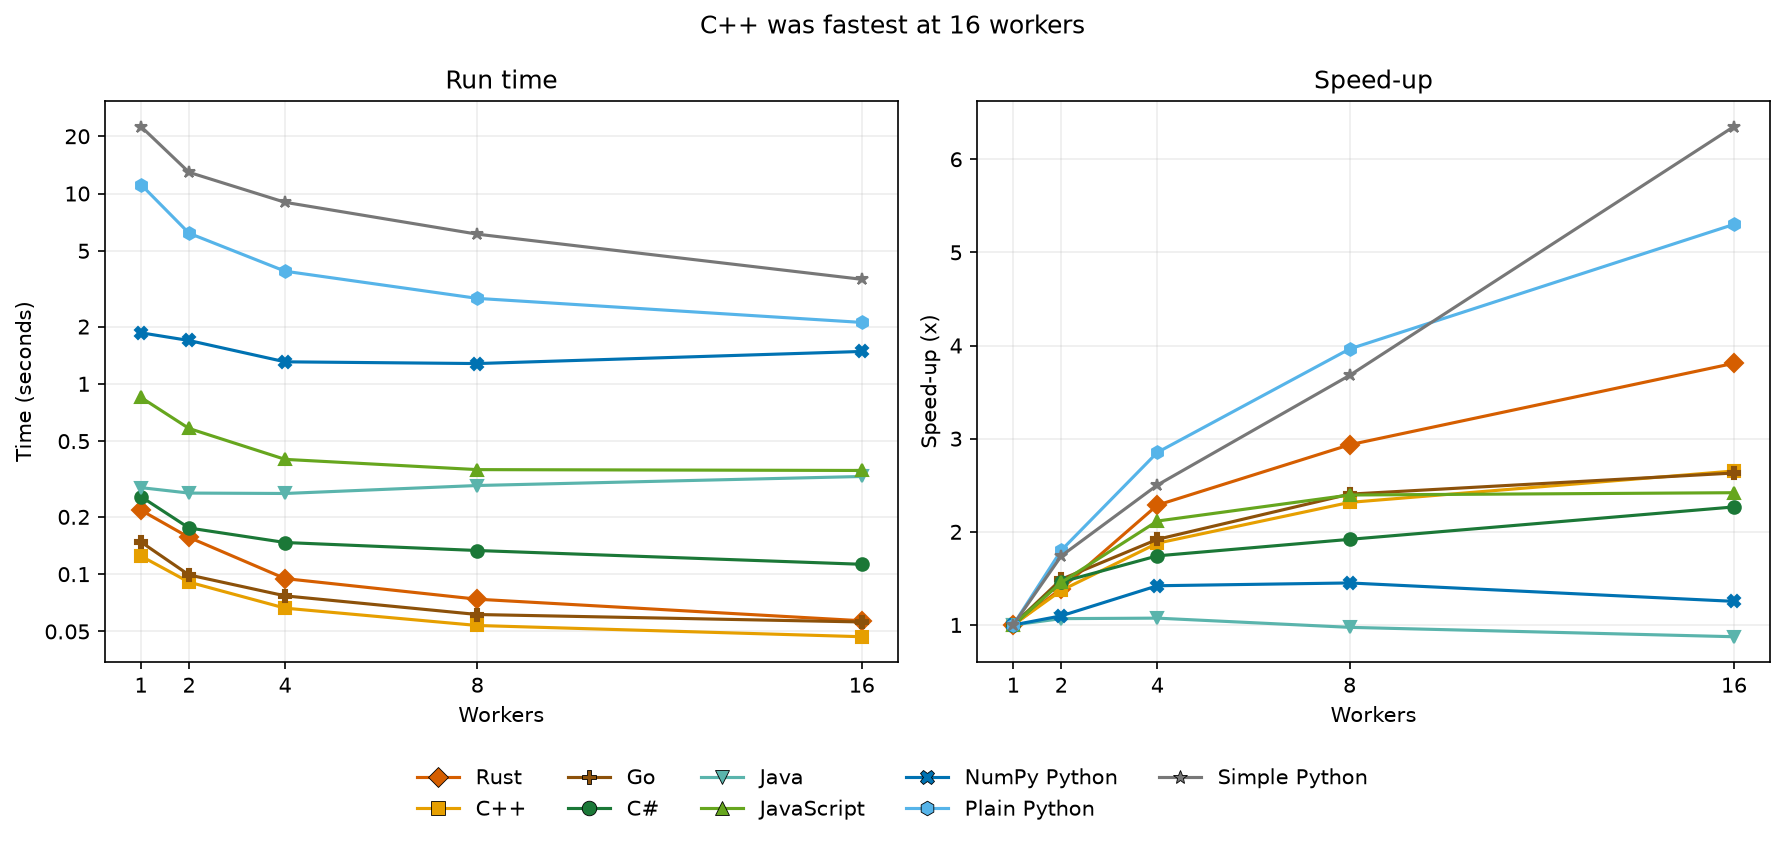

In [23]:
# Compute and present this analysis step for the reader.
sc = scaling[scaling.status.eq("correct")].merge(ok, on=["author", "task", "variant"])
scm = (
    sc.groupby(["author", "variant", "workers"])
    .agg(time=("wall_seconds", "median"), cpu_wall=("cpu_wall_ratio", "median"))
    .reset_index()
)
one = scm[scm.workers.eq(1)].set_index(["author", "variant"]).time
scm["speedup"] = [one.get((r.author, r.variant), np.nan) / r.time for r in scm.itertuples()]
scm.to_csv(DERIVED / "scaling_by_author.csv", index=False)
scv = (
    scm.groupby(["variant", "workers"])
    .agg(time=("time", geom), speedup=("speedup", geom), cpu_wall=("cpu_wall", geom))
    .reset_index()
)
display(scv)
display(
    scm[scm.workers.eq(16)]
    .pivot(index="variant", columns="author", values="speedup")
    .reindex(index=VERSIONS, columns=AUTHORS)
)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for v in VERSIONS:
    d = scv[scv.variant.eq(v)].sort_values("workers")
    for ax, col in zip(axes, ["time", "speedup"]):
        ax.plot(d.workers, d[col], marker=MARKERS[v], color=COLORS[v])
if scv.empty:
    axes[0].set_ylim(0.1, 10)
axes[0].set(yscale="log", ylabel="Time (seconds)", title="Run time")
plain_log_axis(axes[0], "y")
axes[1].set(ylabel="Speed-up (x)", title="Speed-up")
for ax in axes:
    ax.set(xlabel="Workers", xticks=[1, 2, 4, 8, 16])
t16 = scv[scv.workers.eq(16)].dropna(subset=["time"])
fig.suptitle(
    f"{LABELS[t16.loc[t16.time.idxmin(), 'variant']]} was fastest at 16 workers"
    if len(t16)
    else "No 16-worker scaling measurements available"
)
fig.legend(handles=version_handles(), loc="upper center", bbox_to_anchor=(0.5, 0), ncol=5, frameon=False)
fig.tight_layout()
savefig("walkers_scaling.png")


Standard Python cannot run Python code on several cores within one process, so the models started one process per
worker, and plain Python ran 5.3 times faster with 16 workers than with one (geometric mean over models; 3.4 to 7.0
per model). The compiled and virtual-machine languages used threads and gained 2.3 to 3.8 times, less in relative
terms because their one-worker times (0.05 to 1.4 s) were already close to their start-up floors. Java did not gain
at all (0.28 s with one worker, 0.33 s with sixteen), and NumPy barely (1.3 times). Even with 16 processes, plain
Python (2.1 s) stayed slower than every model's single-threaded C++, Rust and Go.

## 18. Code size and build time

The left panel shows the total source size over the eight tasks per version and model, in kilobytes; line counts
would mislead, because some models wrote several statements on one line (Terra's Go ledger is 33 lines). The right
panel shows each compiled program's clean build time (median of three builds), with the median per language marked.
JavaScript and Python have no build step. The tables give the sizes per model and version, and each model's median
build times from clean and after a one-line change.

variant,Rust,C++,Go,C#,Java,JavaScript,NumPy Python,Plain Python,Total
author,,,,,,,,,
Claude Opus 5.5,64,69,45,75,74,53,47,21,448
Claude Sonnet 5.5,43,43,31,50,50,41,30,17,304
Claude Haiku 5.5,48,56,39,61,60,46,47,16,372
GPT-6.1 Terra,21,16,14,16,18,16,15,12,128
Muse Wonder Full,64,58,42,63,62,47,39,28,404
Muse Wonder,64,55,36,56,58,40,32,22,362
DeepSeek V4.1 Flash,50,55,41,66,65,56,31,20,384
GLM 5.3 Flash,50,53,34,54,53,44,37,19,342
Nemotron 3.5 Super VL,48,50,37,46,46,42,23,17,309


,author,variant,clean,incremental
0,deepseek,cpp,3.5,3.5
1,deepseek,csharp,4.5,2.9
2,deepseek,go,5.2,0.22
3,deepseek,java,1.2,1.2
4,deepseek,js,NaN,NaN
5,deepseek,rust,3.6,3.1
6,glm,cpp,3.4,3.4
7,glm,csharp,4.3,3.0
8,glm,go,4.6,0.21
9,glm,java,1.1,1.1


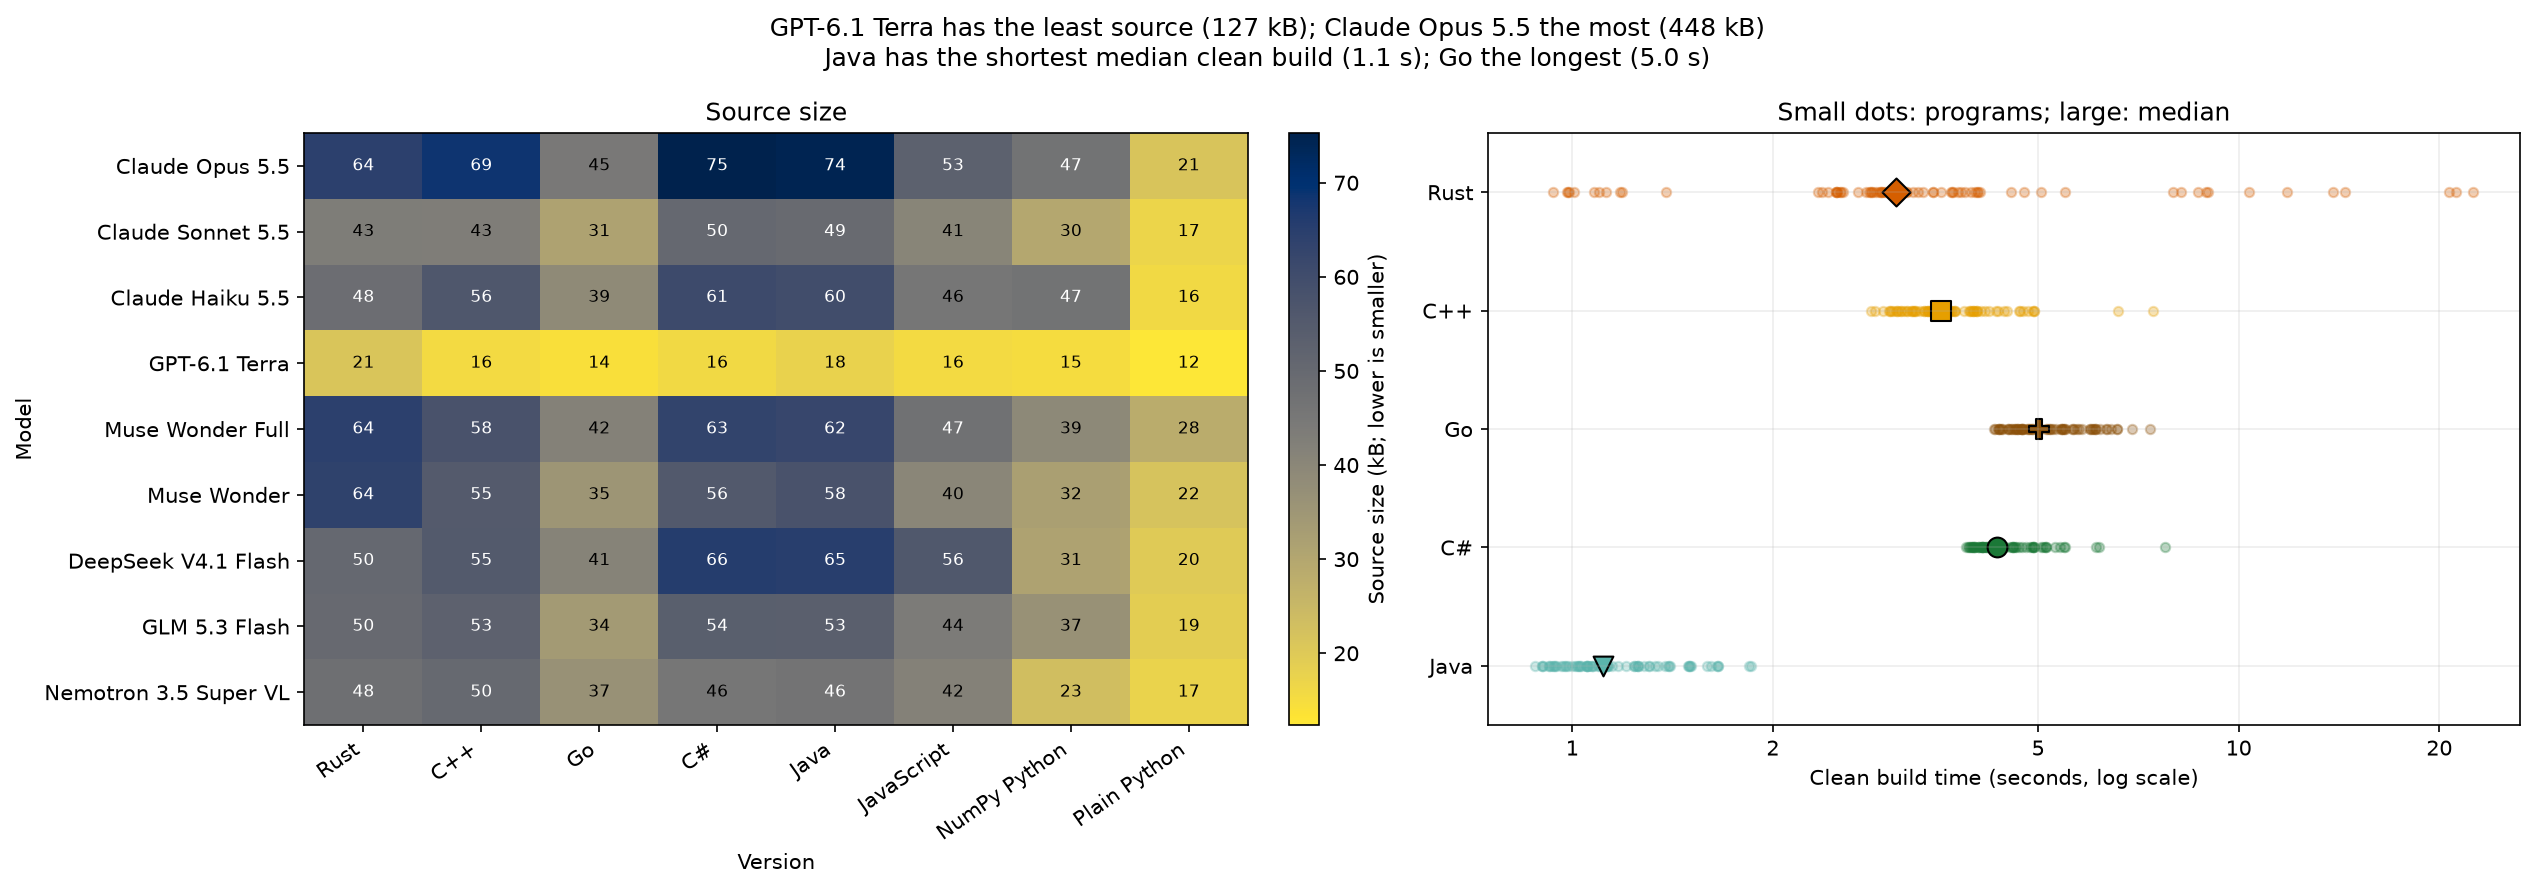

In [24]:
# Compute and present this analysis step for the reader.
loc_main = (
    loc[loc.author.isin(AUTHORS)]
    .groupby(["author", "task", "variant"])
    .agg(code_lines=("code_lines", "sum"), bytes=("bytes", "sum"))
    .reset_index()
)
tot = loc_main.groupby(["author", "variant"])[["bytes", "code_lines"]].sum(min_count=1)
size_table = (tot.bytes / 1000).unstack("variant").reindex(index=AUTHORS, columns=MODEL_VERSIONS)
size_table["Total"] = size_table.sum(axis=1)
display(size_table.rename(index=MODEL_LABELS, columns=LABELS).round(1))


def clean_median(x):
    try:
        a = json.loads(x) if isinstance(x, str) else x
        return np.median(a) if isinstance(a, list) and a else np.nan
    except (ValueError, TypeError):
        return np.nan


build_main = builds[builds.author.isin(AUTHORS)].copy()
build_main["clean_median"] = build_main.clean_seconds.map(clean_median)
BUILT = ["rust", "cpp", "go", "csharp", "java"]
bt = (
    build_main.groupby(["author", "variant"])
    .agg(clean=("clean_median", "median"), incremental=("incremental_seconds", "median"))
    .reset_index()
)
display(bt)
grid = (tot.bytes / 1000).unstack("variant").reindex(index=AUTHORS, columns=MODEL_VERSIONS)
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
heatmap(axes[0], grid, fmt=".1f", label="Source size (kB; lower is smaller)")
axes[0].set(title="Source size", xlabel="Version", ylabel="Model")
for i, v in enumerate(BUILT):
    x = build_main.loc[build_main.variant.eq(v), "clean_median"].dropna()
    x = x[x > 0]
    axes[1].scatter(x, [i] * len(x), color=COLORS[v], alpha=0.3, s=20)
    if len(x):
        axes[1].scatter([x.median()], [i], color=COLORS[v], edgecolor="black", s=90, marker=MARKERS[v])
axes[1].set(
    xscale="log",
    yticks=range(len(BUILT)),
    yticklabels=[LABELS[v] for v in BUILT],
    ylim=(len(BUILT) - 0.5, -0.5),
    xlabel="Clean build time (seconds, log scale)",
    title="Small dots: programs; large: median",
)
if build_main.clean_median.dropna().empty:
    axes[1].set_xlim(0.1, 10)
plain_log_axis(axes[1])
source_totals = loc_main.groupby("author").bytes.sum().dropna() / 1000
build_medians = build_main.groupby("variant").clean_median.median().dropna()
source_title = (
    f"{MODEL_LABELS[source_totals.idxmin()]} has the least source ({format_number(source_totals.min())} "
    f"kB); {MODEL_LABELS[source_totals.idxmax()]} the most ({format_number(source_totals.max())} kB)"
    if len(source_totals)
    else "No source totals available"
)
build_title = (
    f"{LABELS[build_medians.idxmin()]} has the shortest median clean build ({format_number(build_medians.min())} "
    f"s); {LABELS[build_medians.idxmax()]} the longest ({format_number(build_medians.max())} s)"
    if len(build_medians)
    else "No clean builds available"
)
fig.suptitle(source_title + "\n" + build_title)
fig.tight_layout()
savefig("code_and_build.png")


Terra wrote the least code, 127 kB over its 64 programs, and Opus the most, 448 kB; the other seven wrote 304 to 404
kB. Much of the extra length is hand-written parsing and hash tables, which is also where much of the speed came
from, though length alone did not make code fast: Haiku (372 kB) and DeepSeek (384 kB) wrote more than Sonnet (304 kB)
for slower or equally fast programs.

Building from clean took a median of about 1.1 s for Java, 3 s for Rust (up to 22 s when the JSON or pattern
libraries were compiled too), 3.5 s for C++, 4.2 to 4.7 s for C# and 4.6 to 6.5 s for Go, whose clean build
recompiles its standard library; a Go rebuild after a one-line change took 0.2 s.

## 19. Error analysis: slow choices, not wrong answers

No program gave a wrong answer, so this section looks at the next most useful thing: programs that were correct but
much slower than they needed to be, and why. The cases are the largest gaps between models in the same language for
the same task (5 to 22 times; the first table of section 20 ranks every task and version), plus one case where NumPy
made a program slower. Each explanation comes from reading the programs; where a cause was not tested separately,
the text says so.

**Plain-Python heat: six models packed the grid, three looped over cells.** Opus, Sonnet, Haiku, both Muse models and
DeepSeek packed the floor plan into one large integer and moved every cell with a few shifts per step, as in the
worked example; their plain Python took 0.47 to 1.05 s. Terra, GLM and Nemotron kept the grid as lists and computed
each of the 160,000 cells in Python for each of 250 steps: 6.8, 9.8 and 6.1 s. GLM's step loop:

In [25]:
show_code('glm', 'heat', 'plain', 72, 93)

  72      for _ in range(s):
  73          new_rows = rows[:]  # share unchanged rows, copy only updated ones
  74          for r in range(1, h + 1):
  75              seg_r = segs[r]
  76              spec_r = spec[r]
  77              if not seg_r and not spec_r:
  78                  continue
  79              row = rows[r]
  80              up = rows[r - 1]
  81              dn = rows[r + 1]
  82              nrow = row[:]
  83              new_rows[r] = nrow
  84              for a, b in seg_r:
  85                  nrow[a:b] = [
  86                      (4 * v + u + d + l + rr) >> 3
  87                      for v, u, d, l, rr in zip(
  88                          row[a:b], up[a:b], dn[a:b], row[a - 1 : b - 1], row[a + 1 : b + 1]
  89                      )
  90                  ]
  91              for c, mm in spec_r:
  92                  nrow[c] = (mm * row[c] + row[c - 1] + row[c + 1] + up[c] + dn[c]) >> 3
  93          rows = new_rows


This is the program most people would write, and it is correct. The packed versions use a trick that pays only in
Python, where one operation on a huge integer runs in compiled code.

**Ledger: a general JSON library against a scanner written for the format.** Terra's C++ ledger took 11.4 s, its Go
7.2 s and its JavaScript 10.1 s, against 0.72 to 1.10 s, 0.72 to 1.97 s and 1.19 to 2.23 s for the other models in
those languages (Nemotron's JavaScript aside). Terra's C++ builds a full nlohmann/json object tree for each of the
million lines:

In [26]:
show_code('terra', 'ledger', 'cpp', 13, 24)

  13      ios::sync_with_stdio(false); cin.tie(nullptr);
  14      ifstream f(argv[1], ios::binary); string line;
  15      getline(f, line); auto first = json::parse(line);
  16      unordered_map<string,int64_t> rates;
  17      for (auto it=first["rates"].begin(); it!=first["rates"].end(); ++it) rates.emplace(it.key(), it.value().get<int64_t>());
  18      unordered_map<string,int64_t> accounts; unordered_map<string,Stat> channels;
  19      int64_t count=0, net=0;
  20      while (getline(f,line)) {
  21          auto j=json::parse(line);
  22          auto &type=j["type"].get_ref<const string&>();
  23          if(type=="void") continue;
  24          bool skip=false; for(auto &tag:j["tags"]) if(tag=="test") {skip=true; break;}


The Go version decodes each line into a map of raw fields and then decodes each field again with Go's
reflection-based `encoding/json`:

In [27]:
show_code('terra', 'ledger', 'go', 16, 24)

  16   r:=bufio.NewReaderSize(f,1<<20); line,err:=r.ReadBytes('\n'); if err!=nil {panic(err)}
  17   var first map[string]json.RawMessage; if err=json.Unmarshal(line,&first); err!=nil {panic(err)}; rates:=make(map[string]int64); if err=json.Unmarshal(first["rates"],&rates); err!=nil {panic(err)}
  18   accounts:=make(map[string]int64); channels:=make(map[string]*stat); var count,net int64
  19   for { line,err=r.ReadBytes('\n'); if err==io.EOF && len(line)==0 {break}; if err!=nil && err!=io.EOF {panic(err)}
  20    var fields map[string]json.RawMessage; if e:=json.Unmarshal(line,&fields); e!=nil {panic(e)}
  21    var t transaction
  22    for _, field:=range []struct{key string; dest any}{{"account",&t.Account},{"type",&t.Type},{"amount",&t.Amount},{"currency",&t.Currency},{"tags",&t.Tags}} {if e:=json.Unmarshal(fields[field.key],field.dest); e!=nil {panic(e)}}
  23    var meta map[string]json.RawMessage; if e:=json.Unmarshal(fields["meta"],&meta); e!=nil {panic(e)}; if e:=json.Unmars

Terra's JavaScript calls `JSON.parse` per line and does every amount in `BigInt` arithmetic, and so does Nemotron's
(8.4 s). The other seven models wrote small byte-level scanners in each language that read only the fields the task
needs. This one choice accounts for most of the model share on ledger in section 12.

**NumPy that made parsing slower.** Haiku's NumPy ledger took 24.4 s and its NumPy logscan 14.1 s, three times its
own plain Python (7.8 and 4.6 s). Its NumPy ledger is a 310-line attempt to find JSON fields with whole-array
operations over the raw bytes, with a fallback to the `json` module for awkward lines; its plain version is 52 lines
around `json.loads`. NumPy cannot express the per-line decisions of parsing, and the attempt cost more than it saved.
The other models' NumPy ledgers took 7.3 to 10.4 s, no faster than their plain Python either.

**Walkers in Rust: the same generator, eight times apart.** Muse Wonder Full's Rust took 0.044 s and Muse Wonder's
0.376 s. Both run the task's SplitMix64 random number generator, two multiplications per step that must happen in
order. Wonder stepped one walker at a time and chose the direction with a four-way `match`:

In [28]:
show_code('wonder', 'walkers', 'rust', 63, 82)

  63          while i < l {
  64              i += 1;
  65              state = state.wrapping_add(0x9E3779B97F4A7C15u64);
  66              let mut z = state;
  67              z = (z ^ (z >> 30)).wrapping_mul(0xBF58476D1CE4E5B9u64);
  68              z = (z ^ (z >> 27)).wrapping_mul(0x94D049BB133111EB_u64);
  69              // Top two bits of (z ^ (z >> 31)) equal top two bits of z.
  70              match z >> 62 {
  71                  0 => {
  72                      if x == bi {
  73                          bumps += 1;
  74                      } else {
  75                          x += 1;
  76                          if x == 0 && y == 0 { returns += 1; }
  77                      }
  78                  }
  79                  1 => {
  80                      if x == nb {
  81                          bumps += 1;
  82                      } else {


Each step branches on two random bits, which the processor cannot predict. Wonder Full wrote the step without
branches and ran it for four walkers in one loop (its `run4` function repeats this step four times per iteration),
so the processor could work on four independent chains of multiplications at once:

In [29]:
show_code('wonder-full', 'walkers', 'rust', 49, 75)

  49  // One step for one walker. Coordinates are offset by +B, so they lie in
  50  // [0, 2B]; the origin is (B, B). Branchless: the direction is random, so
  51  // real branches on it would mispredict constantly. Only the top two bits
  52  // of the SplitMix64 output are needed, and the final `z ^ (z >> 31)`
  53  // cannot change those bits, so it is omitted.
  54  macro_rules! step {
  55      ($state:ident, $x:ident, $y:ident, $bumps:ident, $rets:ident, $b:ident, $a:ident) => {{
  56          $state = $state.wrapping_add(GOLD);
  57          let mut z = $state;
  58          z = (z ^ (z >> 30)).wrapping_mul(C1);
  59          z = (z ^ (z >> 27)).wrapping_mul(C2);
  60          let d = (z >> 62) as i64; // 0..3
  61          let sign = 1 - ((d & 1) << 1); // +1 for d in {0,2}, -1 for {1,3}
  62          let is_y = d >> 1; // 0 = x move, 1 = y move
  63          let nx = $x + sign * (1 - is_y);
  64          let ny = $y + sign * is_y;
  65          // As unsigned, a negative valu

Four other models' Rust took 0.33 to 0.35 s, like Wonder's. Which of Wonder Full's two changes did more was not
measured.

**Walkers in NumPy: a wrong belief in a comment.** Nemotron's NumPy walkers took 16.7 s, against 0.78 s for Opus's.
Its docstring and loop:

In [30]:
show_code('nemotron', 'walkers', 'fast', 1, 13)
print()
show_code('nemotron', 'walkers', 'fast', 37, 53)

   1  """Random walkers simulation, Python 3.13 + NumPy 2.2.
   2  
   3  All J walkers are evolved in lockstep: their generator states, positions and
   4  counters are NumPy arrays, so one Python iteration advances every walker by one
   5  step. SplitMix64 arithmetic on uint64 arrays wraps modulo 2^64 automatically.
   6  Walkers are independent, so the result does not depend on WORKERS (which is
   7  accepted for interface compatibility).
   8  
   9  Notes on speed: NumPy's per-call overhead dominates for small walker counts
  10  because the per-step random-number stream is inherently sequential per walker,
  11  so this version runs in a single process and keeps the per-step call count
  12  small.
  13  """

  37      for _ in range(l):
  38          states += C
  39          z = states ^ (states >> 30)
  40          z = z * M1
  41          z = z ^ (z >> 27)
  42          z = z * M2
  43          d = (z ^ (z >> 31)) >> 62
  44  
  45          nx = x + np.take(DX, d)
  46     

The loop runs 500,000 times over arrays of only 64 numbers, so it pays NumPy's per-call cost for about 30 array operations per step.
The docstring says the random stream "is inherently sequential per walker". It is not: SplitMix64's state after k
steps is the seed plus k times a constant, so all of a walker's random numbers can be computed at once, which is what
Opus's version did before resolving the walk in blocks.

**Walkers in plain Python: 2.9 s against 18 to 24 s.** Opus's plain Python made 4,096 random numbers at a time by
packing their states into one large integer, and while a walker was far from every wall and from the origin, it
skipped the step-by-step walk and only counted how many of the next steps went each way. Five models wrote the direct
loop and took 17.6 to 24.1 s, about the simple reference's 22.8 s.

**Terra's other slow choices.** On wordpairs, Terra's C++ (4.3 s) kept counts in the standard `std::unordered_map`,
which Microsoft's library builds from linked nodes, while the other eight wrote their own flat tables (0.44 to 1.9 s;
why those differ among themselves was not tested). On logscan, Terra's Go checked every line against one long
regular expression and took 3.7 s; the other eight checked the format by hand and took 0.37 to 0.57 s. On align,
Terra's C++ took 0.58 s against 0.046 to 0.12 s, with the same recurrence as its own 0.12 s Rust; the cause was not
found.

Together these cases are the model share of section 12: on the text and table tasks one parsing or table choice
moved a model's programs in every language at once, while on the arithmetic tasks the models' choices differed less
than the languages did.

## 20. Measurement quality

The laptop was running other work during the timing. The first table ranks the task-and-version cells by how far
apart the fastest and slowest of the nine models' programs were; the error analysis took its cases from the top of
it. The next cell prints the coefficient of variation of each program's five repeats (standard deviation divided by
mean) by version, the programs with the largest variation, how many cores the rest of the machine kept busy during
each run (`other_busy_cores`: busy CPU time on the whole machine minus the program's own, divided by its wall time),
how often a single-worker run used more than 1.2 cores on average, and the rows set aside by the setup cell.

In [31]:
spread=median[median.author.isin(AUTHORS)&median.variant.isin(MODEL_VERSIONS)].groupby(['task','variant']).filter(lambda g:len(g)>=2)
choices=[]
for (t,v),g in spread.groupby(['task','variant']):
    lo=g.loc[g['median'].idxmin()]; hi=g.loc[g['median'].idxmax()]
    if lo['median']>0: choices.append(dict(task=t,version=v,fastest=lo.author,slowest=hi.author,ratio=hi['median']/lo['median']))
display(pd.DataFrame(choices,columns=['task','version','fastest','slowest','ratio']).sort_values('ratio',ascending=False).head(20))
def compare_cell(task,version):
    sizes=loc_main[(loc_main.task==task)&(loc_main.variant==version)].set_index('author')['bytes']
    times=median[(median.task==task)&(median.variant==version)].set_index('author')['median']
    display(pd.DataFrame({'source_bytes':sizes,'median_seconds':times}).reindex(AUTHORS))


,task,version,fastest,slowest,ratio
50,walkers,fast,opus55,nemotron,22
14,heat,plain,opus55,glm,21
16,ledger,cpp,opus55,terra,15
0,align,cpp,opus55,terra,13
27,logscan,go,opus55,terra,10.0
19,ledger,go,sonnet,terra,9.9
56,wordpairs,cpp,opus55,terra,9.8
34,routes,fast,opus55,terra,9.8
55,walkers,rust,wonder-full,wonder,8.5
21,ledger,js,sonnet,terra,8.5


In [32]:
quality_tables = {'correctness': correctness, 'runs': runs, 'sweep': sweep, 'scaling': scaling, 'baseline': baseline}
cv = full.groupby(['task','author','variant']).wall_seconds.agg(['mean','std','count']); cv['CV'] = cv['std']/cv['mean']
display(cv.reset_index().groupby('variant').CV.agg(median='median', max='max').reindex(VERSIONS).rename(index=LABELS).round(3))
display(cv.sort_values('CV', ascending=False).head(10).round(4))
display(pd.DataFrame({name: {'median': d.other_busy_cores.median(), 'max': d.other_busy_cores.max()} for name,d in quality_tables.items()}).T.round(3))
for name, d in quality_tables.items():
    print(name, 'rows with other_busy_cores > 2:', int((d.other_busy_cores > 2).sum()), 'of', len(d))
# CPU time / wall time above 1.2 for single-worker runs is expected for runtimes with background threads (garbage collection, JIT compiler).
single = pd.concat([d.assign(table=name) for name, d in quality_tables.items() if name != 'baseline' for d in [d[d.get('workers', pd.Series(1, index=d.index)) == 1]]])
single['version'] = single.variant
per_runtime = single.groupby('version').agg(rows=('cpu_wall_ratio', 'size'), above_1_2=('cpu_wall_ratio', lambda x: int((x > 1.2).sum())), median_cpu_wall=('cpu_wall_ratio', 'median'), max_cpu_wall=('cpu_wall_ratio', 'max'))
per_runtime['share_above_1_2'] = per_runtime.above_1_2 / per_runtime.rows
display(per_runtime.reindex(VERSIONS).dropna(how='all').rename(index=LABELS).round(3))
aot = single[single.version.isin(['rust', 'cpp', 'go']) & (single.cpu_wall_ratio > 1.2)]
print('ahead-of-time compiled (Rust, C++, Go), single worker, CPU/wall > 1.2:', len(aot))
print(aot.groupby(['version', 'task', 'author']).cpu_wall_ratio.agg(['size', 'max']).round(2).to_string() if len(aot) else 'none')
display(pd.DataFrame(exclusions).groupby(['table','reason']).size().rename('excluded rows') if exclusions else 'No rows were excluded by the freshness filter.')
periods=[]
for name,d in {'runs':runs,'sweep':sweep,'scaling':scaling,'baseline':baseline}.items():
    d=d.copy(); d['task']=d.task.fillna('baseline')
    for task,g in d.groupby('task'):
        periods.append(dict(table=name,task=task,first_started_utc=g.started_utc.min(),last_started_utc=g.started_utc.max(),rows=len(g),median_other_busy_cores=g.other_busy_cores.median()))
display(pd.DataFrame(periods,columns=['table','task','first_started_utc','last_started_utc','rows','median_other_busy_cores']))

exclusion_table = pd.DataFrame(exclusions)
if not exclusion_table.empty:
    exclusion_table.to_csv(DERIVED / "exclusions.csv", index=False)
    print("Exclusions by reason:", exclusion_table.reason.value_counts().to_dict())


,median,max
variant,,
Rust,0.12,0.46
C++,0.14,0.34
Go,0.13,0.3
C#,0.11,0.29
Java,0.12,0.33
JavaScript,0.12,0.53
NumPy Python,0.14,0.29
Plain Python,0.1,0.21
Simple Python,0.086,0.19


mean   std  count   CV
task      author      variant                        
wordpairs sonnet      js        1.9  0.98      5 0.53
ledger    wonder-full js        2.2   1.1      5 0.49
align     wonder      rust     0.11 0.048      5 0.46
heat      terra       rust     0.19 0.084      5 0.44
springs   sonnet      js       0.35  0.12      5 0.35
align     glm         cpp      0.13 0.045      5 0.34
springs   deepseek    cpp      0.15 0.051      5 0.34
align     deepseek    java      0.4  0.13      5 0.33
          terra       java     0.31   0.1      5 0.33
routes    terra       rust     0.72  0.24      5 0.33

,median,max
correctness,11,30
runs,9.7,24
sweep,9.7,26
scaling,10,22
baseline,12,24


correctness rows with other_busy_cores > 2: 3315 of 3315
runs rows with other_busy_cores > 2: 2950 of 2950
sweep rows with other_busy_cores > 2: 2700 of 2700
scaling rows with other_busy_cores > 2: 1095 of 1095
baseline rows with other_busy_cores > 2: 160 of 160


,rows,above_1_2,median_cpu_wall,max_cpu_wall,share_above_1_2
version,,,,,
Rust,1097,40,0.87,6.4,0.036
C++,1053,36,0.87,2.0,0.034
Go,1053,49,0.9,2.8,0.047
C#,1053,30,0.94,1.6,0.028
Java,1053,586,1.2,2.8,0.56
JavaScript,1053,192,1.0,2.0,0.18
NumPy Python,1097,0,0.93,1.2,0
Plain Python,1097,2,0.96,1.2,0.002
Simple Python,117,0,0.96,1.1,0


ahead-of-time compiled (Rust, C++, Go), single worker, CPU/wall > 1.2: 125
                               size  max
version task      author                
cpp     align     haiku           1  1.4
                  opus55          1  1.2
                  terra           1  1.2
                  wonder          1  1.2
        heat      deepseek        2  1.9
                  glm             1  1.2
                  haiku           2  2.0
                  nemotron        2  1.5
                  terra           1  1.6
                  wonder          2  1.4
                  wonder-full     1  1.6
        ledger    haiku           2  1.3
        routes    deepseek        1  1.7
                  glm             1  1.3
                  opus55          2  1.5
                  sonnet          1  1.6
                  terra           2  1.3
                  wonder          1  1.3
                  wonder-full     1  1.7
        springs   glm             1  1.2
                  sonne

table        reason                   
builds       program missing               22
correctness  source hash mismatch         697
             superseded by a later run    824
loc          older version of the file    143
             program missing                1
Name: excluded rows, dtype: int64

,table,task,first_started_utc,last_started_utc,rows,median_other_busy_cores
0,runs,align,2026-11-08T09:03:47.418119+00:00,2026-11-08T09:14:16.240217+00:00,365,9.5
1,runs,heat,2026-11-08T09:15:47.453704+00:00,2026-11-08T09:21:16.098282+00:00,395,9.7
2,runs,ledger,2026-11-08T08:07:30.203896+00:00,2026-11-08T08:32:18.523642+00:00,365,9.5
3,runs,logscan,2026-11-08T08:35:12.265206+00:00,2026-11-08T08:48:08.370939+00:00,365,10
4,runs,routes,2026-11-08T08:50:38.018758+00:00,2026-11-08T09:01:33.067465+00:00,365,9.0
5,runs,springs,2026-11-08T07:19:52.095705+00:00,2026-11-08T07:32:09.175829+00:00,365,9.9
6,runs,walkers,2026-11-08T09:24:57.505634+00:00,2026-11-08T09:41:56.640363+00:00,365,9.5
7,runs,wordpairs,2026-11-08T07:37:32.055010+00:00,2026-11-08T08:02:08.781639+00:00,365,9.5
8,sweep,heat,2026-11-08T09:56:35.426458+00:00,2026-11-08T09:59:58.912579+00:00,948,10
9,sweep,routes,2026-11-08T09:51:45.752247+00:00,2026-11-08T09:55:14.992515+00:00,876,9.8


Exclusions by reason: {'superseded by a later run': 824, 'source hash mismatch': 697, 'older version of the file': 143, 'program missing': 23}


The median coefficient of variation over the five repeats was 9 to 14% per version (8.6% for simple Python); the
largest was 53%, Sonnet's wordpairs JavaScript (mean 1.9 s). Other programs kept a median of 9.7 of the 22 logical
processors busy during the timed runs, more than in the earlier two-model timing (4.4), and more than 2 in every
run, so the outside load was a constant background rather than an occasional spike. The largest consumer seen on the
machine afterwards was OneDrive's file synchronisation, at about 4.5 cores. The load affected all versions alike,
because the programs took turns in a shuffled order, but it widens the noise for any single program.

A single-worker run used more than 1.2 cores on average in 56% of Java runs and 18% of JavaScript runs, from their
garbage collectors and compilers working on other threads, and rarely in the compiled languages (125 of about 3,200
runs). Ratios above about 1.5 between two programs are well beyond this noise; smaller differences between two single
programs are not reliable. The model index and the language-and-model split average over dozens of programs, which
reduces the effect of this noise.

The setup cell set aside 697 correctness rows for programs whose source has since changed, 824 correctness rows
replaced by a later run of the same program and input, 143 code-size rows for older versions of a file, and 23 rows
for programs that do not exist (build records for Rust versions the reference and the two pilot models never had, and
one source file that a later session removed).
No timed run was set aside.

## 21. Limitations

- One program per model, language and task. A second session might choose a different parser, table or loop and
  change a ratio several times over. The family order held for every model; the six middle models did not separate
  beyond their intervals.
- The models were asked for speed, so their plain Python is faster than ordinary Python.
- Different agent programs. The Claude models ran in Claude Code, Terra in Codex and the Muse models in Muse Code,
  each the maker's own tool. The open-weight models ran inside Claude Code through a proxy, a tool built for other
  models, which may suit them less well.
- Harness failures. 55 sessions ended for reasons outside the model (a C++ build script broken by an overlong PATH,
  a free tier's daily limit, credits running out, the laptop sleeping) and were run again from scratch; the failed
  runs are kept. One GLM session reached the 75-minute limit and was measured as written.
- One machine and fixed settings: Windows, an Intel Core Ultra 9 laptop on mains power, MSVC, .NET 8, Java 23 with
  default settings. Other programs, chiefly file synchronisation, kept a median of 9.7 of the 22 logical processors
  busy during the timing, and the median variation between a program's five repeats was 9 to 14% per language. The
  shuffled order spreads this load over all versions but widens the noise for single programs.
- Correctness at a ceiling: this test cannot say how often each model's code is wrong on harder or vaguer tasks.
- Who wrote the study. The specs are by Claude Opus 5.5, the fastest model here, and the generators by GPT-6.1 Sol;
  a spec's wording could suit one company's models. The measurement plan, the speed index and the language-and-model
  split were set before the final timing. How the split is pooled over tasks was changed after the results were
  seen, from a fit that put task-specific differences into the remainder (37% language, 26% model) to the sum over
  tasks; both are in the saved results. The run history is in [data/PROTOCOL.md](data/PROTOCOL.md).

## 22. What the evidence supports

For a job that runs often enough for seconds to matter, ask the model for Rust, C++ or Go. Every one of the nine
models wrote its fastest version in one of these three, three to twelve times faster than its best Python, with a
build of a few seconds. C# and Java were two to seven times faster than Python but used as much memory or more;
JavaScript was two to three times faster.

For arithmetic, the language is most of the decision. For parsing text and looking things up in tables, the model
matters as much: the same language ran up to 15 times slower in one model's hands than in another's, so checking
which parser and table a model chose is worth more than switching languages. The largest model of each company
wrote its fastest code, and Claude Opus 5.5 led clearly; open-weight DeepSeek matched the mid-priced closed models.
The open question is how stable these model differences are across repeated sessions.

## 23. How the study got here

A pilot ran the heat task in Rust and Python with the models first planned, Claude Opus 5.5 and GPT-6.1 Sol. To save
subscription quota, Claude Sonnet 5.5 and GPT-6.1 Terra then wrote Rust and Python for all tasks on 2026-10-30 and
the other five languages on 2026-11-03. Seven more models wrote everything from 2026-11-05 to 2026-11-07 with the
same prompts. A first timing of two tasks ran on battery power, 1.6 to 2.5 times slower, so every program was timed
again in one sitting on mains power on 2026-11-08, with a guard that discards any run during which the machine slept
or lost power (none did). All numbers here come from that sitting.

The two earlier timings are kept in `data/results_2026-11-03/` and `data/results_battery_2026-11-06/`; details are in `data/PROTOCOL.md`.

## 24. How to reproduce

This notebook reads only the saved results in `data/`. To regenerate everything, run these from the notebook's
folder on Windows with Python 3.13, NumPy 2.2 and the toolchains of section 5, in order:
`python -X utf8 -m bench.generate` (inputs, about 1 GB, written to `%USERPROFILE%\nb-work\39-rust-vs-python` or the
folder in `NB39_WORK`), `python -X utf8 -m bench.reference all` and `python -X utf8 -m bench.check_reference`
(expected outputs and their cross-check), `python -X utf8 -m bench.sessions run-all --kind main` and
`--kind langs` (the 144 sessions; skipped while the saved programs match their request hashes; new sessions need the
`claude`, `codex` and `muse` tools and an `OPENROUTER_API_KEY`), `python -X utf8 -m bench.measure all` (builds,
correctness and timing, about five hours, on mains power), and then this notebook with
`python -m nbconvert --to notebook --execute --inplace 39_rust_vs_python.ipynb`. Toolchain paths can be set with
`NB39_VCVARS`, `NB39_JAVA`, `NB39_DOTNET`, `NB39_GO` and `NB39_NODE`; the vendored C++ and Java libraries are pinned
by SHA-256 in `bench/template/vendor_langs.json`.

## 25. Spend

The cell totals the session costs and tokens per model, first for the kept sessions and then for the sessions ended
by harness failures. Claude Code reports a list-price cost estimate in US dollars, OpenRouter the amount it charged,
and Codex and Muse Code report tokens used on a subscription.

In [33]:
for name,d in [('kept',sessions),('harness failures',failed_sessions)]:
    report=d.groupby(['author','cost_basis']).agg(sessions=('task','size'),cost_usd=('cost_usd',lambda x:x.sum(min_count=1)),all_input_tokens=('all_input_tokens',lambda x:x.sum(min_count=1)),cached_input_tokens=('cached_input_tokens',lambda x:x.sum(min_count=1)),output_tokens=('output_tokens',lambda x:x.sum(min_count=1)),reasoning_tokens=('reasoning_tokens',lambda x:x.sum(min_count=1)))
    print(name); display(report.reindex(AUTHORS+['opus','sol'],level='author')); print('Totals:',d[['cost_usd','all_input_tokens','cached_input_tokens','output_tokens','reasoning_tokens']].sum(min_count=1).to_dict())


kept


,,sessions,cost_usd,all_input_tokens,cached_input_tokens,output_tokens,reasoning_tokens
author,cost_basis,,,,,,
opus55,Claude Code list-price estimate,16,40,44624821,43283545,1011499,440680
sonnet,Claude Code list-price estimate,16,7.9,11954969,11373163,448357,131790
haiku,Claude Code list-price estimate,16,2.7,46357971,44774603,1300810,835236
terra,Codex subscription (tokens only),16,NaN,4821182,4395520,101632,12793
wonder-full,Muse subscription (tokens only),16,NaN,40016604,38471344,621778,295759
wonder,Muse subscription (tokens only),16,NaN,32465670,31240692,499788,218525
deepseek,OpenRouter charge,16,8.0,52728580,4385280,1212917,754650
glm,OpenRouter charge,16,2.2,42333698,41192896,877314,649176
nemotron,OpenRouter charge,16,0,90549100,85419200,1155846,747931


Totals: {'cost_usd': 61.584953510000005, 'all_input_tokens': 367423328.0, 'cached_input_tokens': 305976640.0, 'output_tokens': 7281519.0, 'reasoning_tokens': 4110027.0}
harness failures


,,sessions,cost_usd,all_input_tokens,cached_input_tokens,output_tokens,reasoning_tokens
author,cost_basis,,,,,,
opus55,Claude Code list-price estimate,5,11,12147306,11748848,284226,92574
haiku,Claude Code list-price estimate,5,1.1,18871676,18288920,480037,273557
wonder-full,Muse subscription (tokens only),6,NaN,15972351,15378068,226255,75924
wonder,Muse subscription (tokens only),6,NaN,8834535,8489520,134957,41470
deepseek,OpenRouter charge,9,4.0,26885505,2243328,506002,284983
glm,OpenRouter charge,11,0.98,23468308,22872576,397275,202188
nemotron,OpenRouter charge,13,0,121222756,116243824,1338293,887213


Totals: {'cost_usd': 17.281618334, 'all_input_tokens': 227402437.0, 'cached_input_tokens': 195265084.0, 'output_tokens': 3367045.0, 'reasoning_tokens': 1857909.0}


The 146 kept sessions (144 plus the two pilot sessions) cost USD 61.6 where a cost is reported: USD 40 for Opus,
8.0 for DeepSeek, 7.9 for Sonnet, 2.7 for Haiku, 2.2 for GLM, 1.1 for the Opus pilot and nothing for Nemotron's free
tier. The 55 sessions ended by harness failures cost USD 17.3 more. Together the sessions read 595 million input
tokens, 501 million of them from cache, and wrote 10.6 million output tokens. The measurement itself makes no model
calls.

## 26. Future work and further reading

### Future work

- Several sessions per model and task, to show how much of the 40% model share is the model and how much one
  session's choice; the ledger and walkers gaps of 8 to 15 times are the cases to repeat first.
- Steer the parser: repeat ledger, logscan and wordpairs with a prompt that names the approach (scan bytes, no
  general JSON tree, a flat hash table) and measure how much of the model share one sentence removes.
- Ask for clear code instead of fast code; the 18x gap between Sonnet's packed-integer heat and the simple loop
  suggests the instruction changes Python results most.
- Run each open-weight model in its maker's own agent tool, where one exists, against the same model in Claude Code.
- Re-time the saved programs on an idle Linux machine with Clang or GCC, .NET 10, a tuned Java heap, Bun, PyPy and
  free-threaded Python; no new sessions are needed.

### Further reading

Links checked on 2026-10-30.

- [EffiBench: Benchmarking the Efficiency of Automatically Generated Code](https://arxiv.org/abs/2402.02037)
  (Huang et al., 2024). Run time and memory of code from 42 models on LeetCode problems, in one language.
- [Mercury: A Code Efficiency Benchmark for Code Large Language Models](https://arxiv.org/abs/2402.07844)
  (Du et al., 2024). Scores the speed of model-written Python together with its correctness.
- [Learning Performance-Improving Code Edits](https://arxiv.org/abs/2302.07867) (Shypula et al., 2023). Trains
  models to make C++ programs faster, the step after measuring their first versions.
- [Energy efficiency across programming languages: how do energy, time, and memory relate?](https://doi.org/10.1145/3136014.3136031)
  (Pereira et al., 2017). Run time, memory and energy of 27 languages on expert-written programs.
- [The Computer Language Benchmarks Game](https://benchmarksgame-team.pages.debian.net/benchmarksgame/). Expert-tuned
  programs in many languages, for seeing how far model-written code is from tuned code.
- [Array programming with NumPy](https://doi.org/10.1038/s41586-020-2649-2) (Harris et al., 2020). How NumPy's
  arrays work, and why NumPy helped on the numeric tasks and not on parsing.